# Postnatal Multiome analysis 

# Load packages

In [1]:
library(Signac)
library(Seurat)
library(rtracklayer)
library(dplyr)
library(Matrix)
library(ggplot2)
library(cowplot)
require(biomaRt)
library(DoubletFinder)
library(RColorBrewer)
library(stringr)
set.seed(1234)

Warning message:
“package ‘Signac’ was built under R version 4.3.3”
Warning message:
“package ‘Seurat’ was built under R version 4.3.3”
Loading required package: SeuratObject

Warning message:
“package ‘SeuratObject’ was built under R version 4.3.3”
Loading required package: sp

Warning message:
“package ‘sp’ was built under R version 4.3.3”

Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


Warning message:
“package ‘rtracklayer’ was built under R version 4.3.3”
Loading required package: GenomicRanges

Warning message:
“package ‘GenomicRanges’ was built under R version 4.3.3”
Loading required package: stats4

Loading required package: BiocGenerics

Warning message:
“package ‘BiocGenerics’ was built under R version 4.3.2”

Attaching package: ‘BiocGenerics’


The following object is masked from ‘package:SeuratObject’:

    intersect


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The fol

In [2]:
my_c <- c('#fe864a', '#c9d179', '#95d0fc', '#fbdd7e', '#388004', '#c760ff', '#76cd26', '#ffbacd', '#d6b4fc',
        '#cfaf7b','#8b88f8', '#acc2d9', '#894585', '#82cbb2', '#d99b82', '#fdee73', '#5170d7', '#ffd8b1', 
        '#b7e1a1', '#82a67d', '#b7fffa', '#b790d4', '#f5674a', '#C79FEF', '#DAA520', '#A0522D')

# Data loading

 This genes are the ones used to perform the aligment on CellRanger using the costumized genome reference. It contains teh CreERT2 gene and e GFP gene.

In [3]:
annotation <- import('genes2.gtf')

In [4]:
annotation$gene_biotype[1:1780455] = annotation$gene_type[1:1780455]
seqlevelsStyle(annotation) <- "UCSC" #Support for other than Ensembl seqlevel style
# annotation <- renameSeqlevels(annotation, mapSeqlevels(seqlevels(annotation), "UCSC"))

In [5]:
annotation$tx_id = annotation$transcript_id

In [ ]:
#load fragments data
P11_sample1_frags <- 'P11_sample1_atac_fragments.tsv.gz'

P11_sample2_frags <- 'P11_sample2_atac_fragments.tsv.gz'

P11_sample3_frags <- 'P11_sample3_atac_fragments.tsv.gz'

P60_sample1_frags <- 'P60_sample1_atac_fragments.tsv.gz'

P60_sample2_frags <- 'P60_sample2_atac_fragments.tsv.gz'

P60_TTR_sample3_frags <- 'P60_TTR_sample3_atac_fragments.tsv.gz'

In [ ]:
sample_names <- c('P11_sample1', 'P11_sample2', 'P11_sample3', 'P60_sample1', 'P60_sample2', 'P60_TTR_sample3')

In [ ]:
frags_path <- c(P11_sample1_frags, P11_sample2_frags, P11_sample3_frags, P60_sample1_frags, P60_sample2_frags, 
           P60_TTR_sample3_frags)

# Load all cell types data

In [ ]:
raw <- readRDS('Merged_multiome.rds')

In [10]:
raw

An object of class Seurat 
195169 features across 53835 samples within 2 assays 
Active assay: ATAC (162882 features, 0 variable features)
 2 layers present: counts, data
 1 other assay present: RNA

In [ ]:
filtered <- readRDS('Integrated_multiome_clusters_joint_linked_cell_type.rds')

# Load subclustering data

In [ ]:
epi <- readRDS('Epithelial_integrated_noDBL_multiome_celltype_joint_linked.rds')

In [ ]:
endo <- readRDS('Endothelial_integrated_noDBL_multiome_celltype_joint_linked.rds')

In [ ]:
mesen <- readRDS('Mesenchymal_integrated_noDBL_multiome_celltype_joint_linked.rds')

In [ ]:
immune <- readRDS('Immune_integrated_multiome_celltype_joint_linked.rds')

In [ ]:
neugli <- readRDS('Neuronal_and_Glial_integrated_noDBL_multiome_celltype_joint_linked.rds')

In [17]:
epi$Cell_type_group <- 'Epithelial cells'

In [18]:
endo$Cell_type_group <- 'Endothelial cells'

In [19]:
mesen$Cell_type_group <- 'Mesenchymal cells'

In [20]:
immune$Cell_type_group <- 'Immune cells'

In [21]:
neugli$Cell_type_group <- 'Neuronal and glial cells'

In [22]:
subclus_samples <- c(epi, endo, mesen, immune, neugli)

In [23]:
subclus_samples

[[1]]
An object of class Seurat 
215510 features across 33300 samples within 2 assays 
Active assay: peaks (183223 features, 183119 variable features)
 2 layers present: counts, data
 1 other assay present: RNA
 11 dimensional reductions calculated: pca, umap, umap_RNA, harmonyRNA, harmony_RNA, lsi, umap_peaks, harmonypeaks, harmony_peaks, harmony_Peaks, umap_multiome

[[2]]
An object of class Seurat 
215510 features across 1612 samples within 2 assays 
Active assay: peaks (183223 features, 29823 variable features)
 2 layers present: counts, data
 1 other assay present: RNA
 9 dimensional reductions calculated: pca, umap_RNA, harmonyRNA, harmony_RNA, lsi, umap_peaks, harmonyPeaks, harmony_Peaks, umap_multiome

[[3]]
An object of class Seurat 
215510 features across 2792 samples within 2 assays 
Active assay: peaks (183223 features, 60782 variable features)
 2 layers present: counts, data
 1 other assay present: RNA
 10 dimensional reductions calculated: pca, umap, umap_RNA, harmonyRNA,

In [24]:
for(i in 1:length(subclus_samples)){
    DefaultAssay(subclus_samples[[i]]) <- 'RNA'
    subclus_samples[[i]] <- subclus_samples[[i]]
}

In [25]:
subclus_samples

[[1]]
An object of class Seurat 
215510 features across 33300 samples within 2 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: peaks
 11 dimensional reductions calculated: pca, umap, umap_RNA, harmonyRNA, harmony_RNA, lsi, umap_peaks, harmonypeaks, harmony_peaks, harmony_Peaks, umap_multiome

[[2]]
An object of class Seurat 
215510 features across 1612 samples within 2 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: peaks
 9 dimensional reductions calculated: pca, umap_RNA, harmonyRNA, harmony_RNA, lsi, umap_peaks, harmonyPeaks, harmony_Peaks, umap_multiome

[[3]]
An object of class Seurat 
215510 features across 2792 samples within 2 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: peaks
 10 dimensional reductions calculated: pca

In [26]:
merged_filt <-  merge(subclus_samples[[1]], y = subclus_samples[2:5])

Warning message in merge.ChromatinAssay(x = objects[[idx.x]][[assay]], y = lapply(X = objects[idx.y], :
“Annotations do not match, keeping annotation from the
            first object only”
Warning message in merge.ChromatinAssay(x = objects[[idx.x]][[assay]], y = lapply(X = objects[idx.y], :
“Annotations do not match, keeping annotation from the
            first object only”
Warning message in merge.ChromatinAssay(x = objects[[idx.x]][[assay]], y = lapply(X = objects[idx.y], :
“Annotations do not match, keeping annotation from the
            first object only”


In [27]:
merged_filt

An object of class Seurat 
215510 features across 37992 samples within 2 assays 
Active assay: RNA (32287 features, 0 variable features)
 2 layers present: counts, data
 1 other assay present: peaks

In [28]:
merged_filt

An object of class Seurat 
215510 features across 37992 samples within 2 assays 
Active assay: RNA (32287 features, 0 variable features)
 2 layers present: counts, data
 1 other assay present: peaks

In [29]:
unique(merged_filt@meta.data$Cell_type)

[1] "Epithelial cells"                "Gata3+"                         
 [3] "Ciliogenesis"                    "Proligerating epithelial cells" 
 [5] "Capilary"                        "Artery"                         
 [7] "Vein"                            "Proliferating endothelial cells"
 [9] "Fibroblasts"                     "VSMC"                           
[11] "Pericytes"                       "Proliferating mesenchymal cells"
[13] "Macrophages"                     "Lymphocytes"                    
[15] "Neuroblast-like habenula"        "Neurons"                        
[17] "Ependymal cells"                 "OPCs"                           
[19] "Oligodendrocytes"

In [30]:
raw_merged <- subset(raw, cells = colnames(merged_filt))

In [40]:
subcell.meta <- data.frame(CellID = colnames(merged_filt), Sub_Cell_type = merged_filt$Cell_type)

In [32]:
new.metadata <- data.frame(CellID = colnames(merged_filt), Cell_type = merged_filt$Cell_type_group)

In [41]:
raw_merged$Sub_Cell_type <- 'placeholder'

In [42]:
raw_merged$Sub_Cell_type <- subcelltype_meta

In [43]:
raw_merged$Cell_type <- new.metadata

In [44]:
head(raw_merged@meta.data)

,orig.ident,nCount_RNA,nFeature_RNA,nCount_ATAC,nFeature_ATAC,Age,Sample,pct_mito,pct_hb,nucleosome_signal,nucleosome_percentile,TSS.enrichment,TSS.percentile,Batch,Sub_cell_type,Cell_type,Sub_Cell_type
,<chr>,<dbl>,<int>,<dbl>,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
P11_01_n00388_AAACAGCCACTGACCG-1,P11_01_n00388,3737,2018,3380,1644,P11,P11_01_n00388,0.02675943,0.00000000,0.8851351,0.80,4.647984,0.35,n00388,placeholder,Epithelial cells,Epithelial cells
P11_01_n00388_AAACAGCCAGGTATTT-1,P11_01_n00388,3357,1803,5438,2732,P11,P11_01_n00388,0.02978850,0.00000000,0.7299930,0.52,4.840922,0.44,n00388,placeholder,Mesenchymal cells,Fibroblasts
P11_01_n00388_AAACATGCAGAATGAC-1,P11_01_n00388,5061,2435,7251,3548,P11,P11_01_n00388,0.03951788,0.03951788,0.6648488,0.33,4.086360,0.15,n00388,placeholder,Epithelial cells,Epithelial cells
P11_01_n00388_AAACATGCAGATAGAC-1,P11_01_n00388,4093,2027,5326,2531,P11,P11_01_n00388,0.12215978,0.00000000,0.6442953,0.27,5.946831,0.83,n00388,placeholder,Epithelial cells,Gata3+
P11_01_n00388_AAACATGCAGGACCTT-1,P11_01_n00388,4061,2086,5084,2470,P11,P11_01_n00388,0.09849791,0.00000000,0.8373729,0.73,4.902597,0.47,n00388,placeholder,Epithelial cells,Epithelial cells
P11_01_n00388_AAACATGCAGTAATAG-1,P11_01_n00388,5204,2735,1026,448,P11,P11_01_n00388,0.13451191,0.00000000,0.9324759,0.85,6.157479,0.87,n00388,placeholder,Epithelial cells,Epithelial cells


In [45]:
merged <- raw_merged

In [46]:
merged

An object of class Seurat 
195169 features across 37992 samples within 2 assays 
Active assay: ATAC (162882 features, 0 variable features)
 2 layers present: counts, data
 1 other assay present: RNA

In [47]:
frags <- Fragments(merged)

In [48]:
Fragments(merged) <- NULL

In [49]:
for (i in 1:length(frags)){
    frags[[i]] <- UpdatePath(frags[[i]], new.path = frags_path[[i]])
}

Computing hash

Computing hash

Computing hash

Computing hash

Computing hash

Computing hash



In [50]:
Fragments(merged) <- frags

In [ ]:
saveRDS(merged, 'noDBL_merged_raw.rds')

In [ ]:
merged <- readRDS('noDBL_merged_raw.rds')

In [58]:
merged@assays

$RNA
Assay data with 32287 features for 37992 cells
First 10 features:
 Xkr4, Gm1992, Gm19938, Gm37381, Rp1, Sox17, Gm37587, Gm37323, Mrpl15,
Lypla1 

$ATAC
ChromatinAssay data with 162882 features for 37992 cells
Variable features: 0 
Genome: 
Annotation present: TRUE 
Motifs present: FALSE 
Fragment files: 6 


In [59]:
unique(epi$Sample)

[1] "P11_01_n00388"        "P11_02_n00388"        "P11_03_n00388"       
[4] "P60_05_n00388"        "P60_06_d05797"        "P60_TTR_07_06_n00388"

In [60]:
unique(merged$Age)

[1] "P11" "P60"

Warning message:
“Removed 1581 rows containing non-finite outside the scale range (`stat_bin()`).”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range (`geom_bar()`).”
Warning message:
“Removed 1581 rows containing non-finite outside the scale range (`stat_bin()`).”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range (`geom_bar()`).”


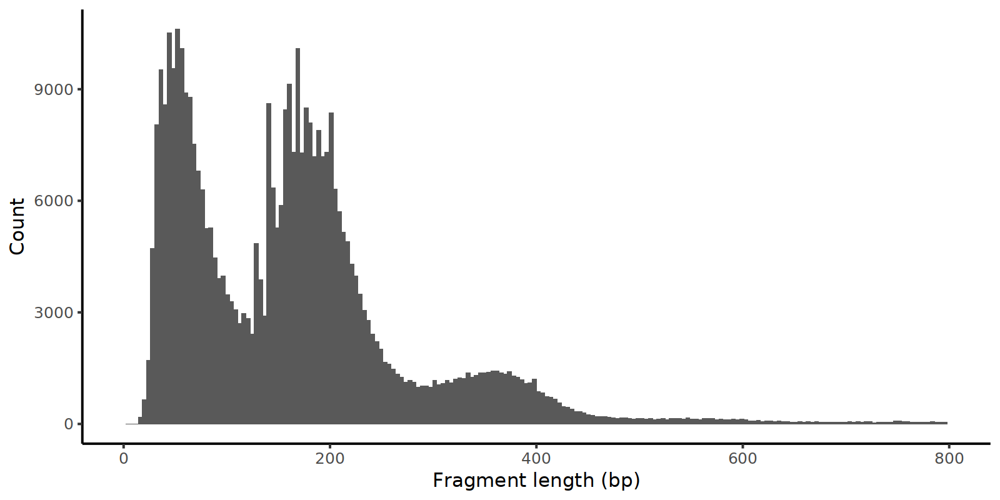

In [ ]:
options(repr.plot.width = 8, repr.plot.height = 4, repr.plot.res = 200)
merged$nucleosome_group <- ifelse(merged$nucleosome_signal > 2.0, 'NS > 2.0', 'NS < 2.0')

frag_hist <- FragmentHistogram(object = merged, group.by = 'nucleosome_group', region = 'chr1-1-10000000')

frag_hist

ggsave(file="noDBL_noDBL_Merged_frag_hist.svg", plot=frag_hist, width=8, height=4)

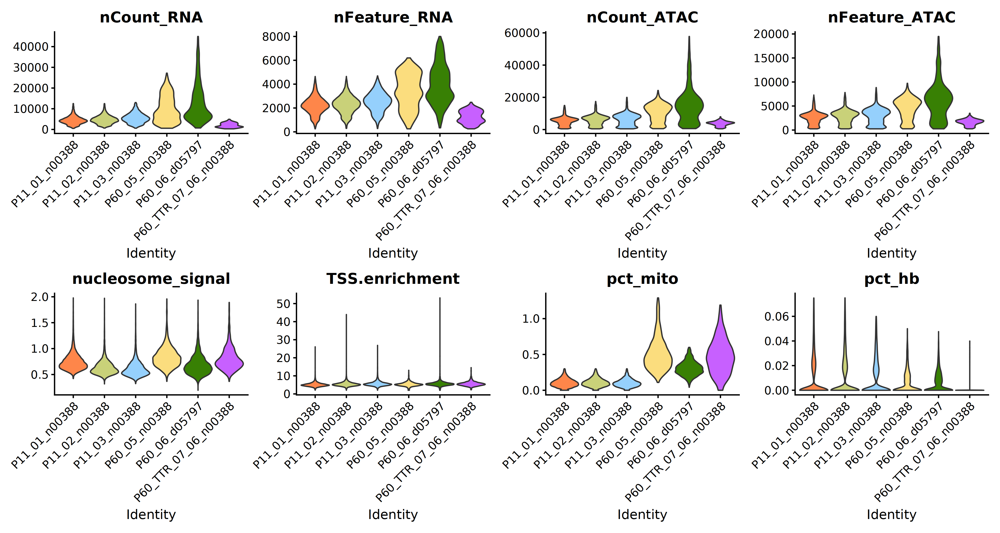

In [ ]:
options(repr.plot.width = 15, repr.plot.height = 8, repr.plot.res = 300)

vln <- VlnPlot(merged, features=c('nCount_RNA', 'nFeature_RNA', 'nCount_ATAC', 'nFeature_ATAC', 'nucleosome_signal', 'TSS.enrichment', 'pct_mito', 'pct_hb'), 
        ncol=4, pt.size=0, col = my_c) 

vln

ggsave(file="noDBL_noDBL_Merged_all_vln_prefilter.svg", plot=vln, width=15, height=8)


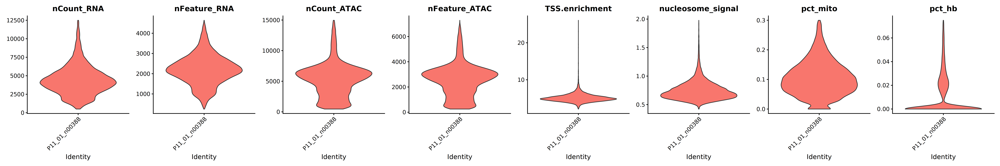

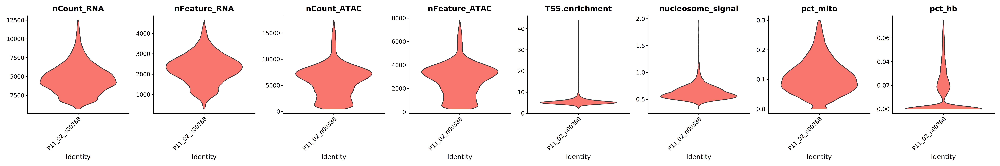

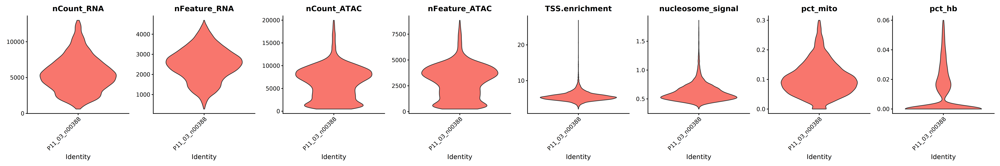

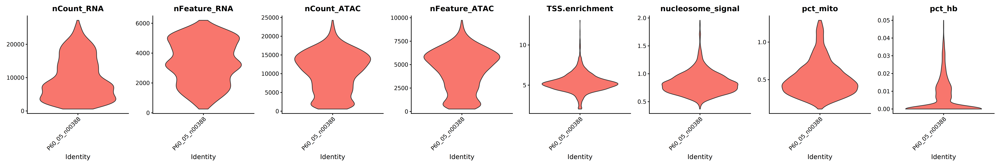

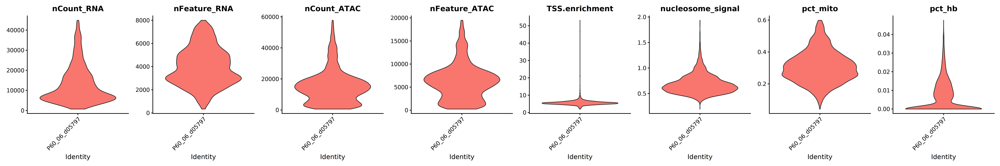

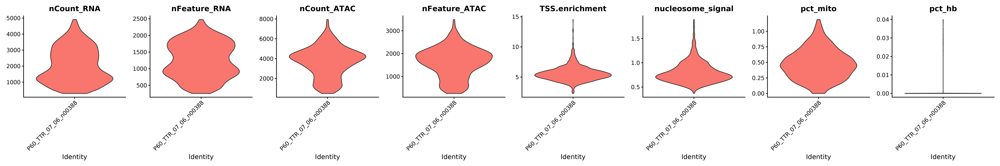

In [ ]:
options(repr.plot.width=30, repr.plot.height=5)
vlns_pre <- c()
for (sample in sample_names){
    s <- subset(merged, subset = Sample == sample)
    vln <- VlnPlot(object = s, features = c("nCount_RNA", "nFeature_RNA", "nCount_ATAC", "nFeature_ATAC", "TSS.enrichment", "nucleosome_signal", "pct_mito", "pct_hb"), 
                  ncol = 8, pt.size = 0)
    
    plot_name = paste("noDBL_noDBL_", sample, "_vln_prefilter.svg")
    #vlns_pre <- c(vlns_pre, vln)
    print(vln)
    
    ggsave(file=plot_name, plot=vln, width=30, height=5)
    
    
}

In [64]:
DefaultAssay(merged) <- 'RNA' 

In [65]:
vars_to_regress <- c('Sample')

In [66]:
merged <- merged %>% 
                            NormalizeData(normalization.method = "LogNormalize", scale.factor = 10000) %>%
                            FindVariableFeatures(selection.method = "vst", nfeatures=4000, ) %>%
                            ScaleData() %>%
                            RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  Enpp2, Ttr, Prlr, Psap, Bsg, Kl, Arl6ip1, Fth1, Cox8a, Ptgds 
	   Slc22a17, Atp1b1, Ctsd, Chchd10, Cst3, Clu, Pebp1, Ace, Mt3, Rdh5 
	   Cox4i1, Atp5g1, Ppp1r1b, Clic6, 2900040C04Rik, Ldhb, Ndufa13, Hemk1, Cox8b, Map1lc3a 
Negative:  Ebf1, Auts2, Prkg1, Dlc1, Rbpms, Adam12, Rbms3, Adamts9, Lsamp, Lama2 
	   Cped1, Cmip, Fosb, Col4a1, Dach1, Adgrl3, Clic4, Zeb2, Cp, Itga8 
	   Adamts12, Epb41l2, Emcn, Plpp3, Pde7b, Arhgap31, Ldb2, Vcl, Nid1, Zswim6 
PC_ 2 
Positive:  Syt1, Fgf14, Erbb4, Dach2, Rtl4, Adamtsl1, Ppargc1a, Immp2l, Spag16, Slc35f1 
	   Atp2b3, Ppp2r2b, Strip2, A830018L16Rik, Pip5k1b, Tmem72, Kcnd2, Cacna2d3, 2810403D21Rik, Cdh18 
	   Lrp1b, Car12, Tox, Col8a1, Negr1, Gm29266, Adamtsl3, Gm42047, Tll1, Slc4a5 
Negative:  Ebf1, Adam12, Lsamp, Lama2, Cped1, Igfbp7, Rbpms, Dlc1, Cp, Adgrl3 
	   Auts2, Itga8, Fosb, Adamts9, Cmip, Rbms3, Prkg1, Cemip, Zeb2, Emcn 
	   Clic4, Adamts12, Alpl, Fam155a, Nid1, Moxd1, Col4a1, Mgp, Plpp3

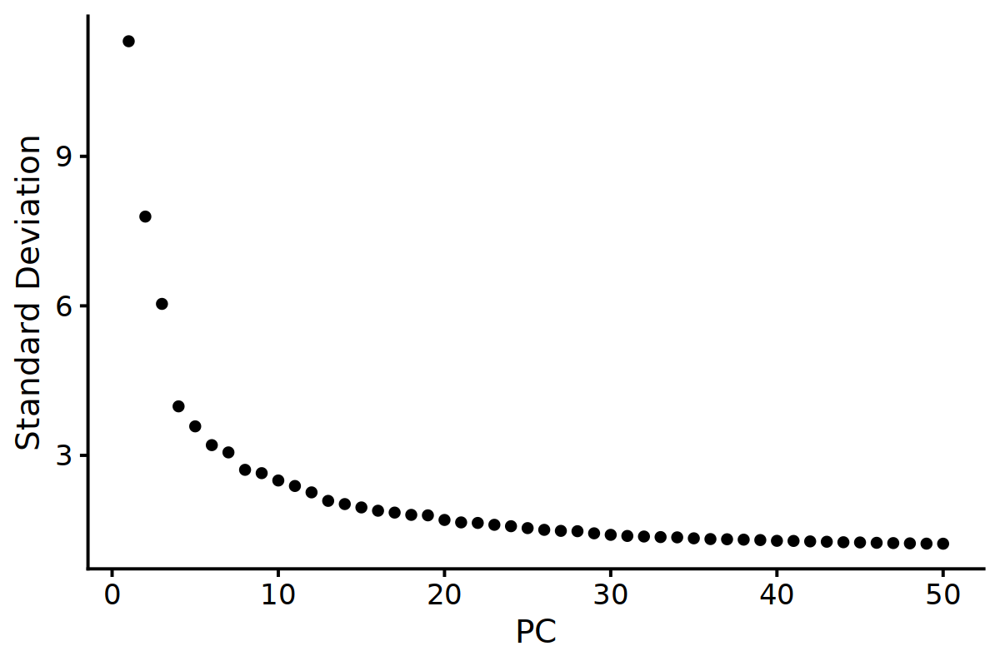

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
pca <- ElbowPlot(merged, ndims = 50)

pca

ggsave(file="noDBL_noDBL_merged_pca.svg", plot=pca, width=6, height=4)

In [68]:
merged <- RunUMAP(merged, dims = 1:22, reduction = 'pca', n.neighbors = 15)

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
10:05:58 UMAP embedding parameters a = 0.9922 b = 1.112

10:05:58 Read 37992 rows and found 22 numeric columns

10:05:58 Using Annoy for neighbor search, n_neighbors = 15

10:05:58 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

10:06:02 Writing NN index file to temp file /tmp/RtmpoVZTt9/filef8c2655ab6a87

10:06:02 Searching Annoy index using 1 thread, search_k = 1500

10:06:09 Annoy recall = 100%

10:06:12 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors

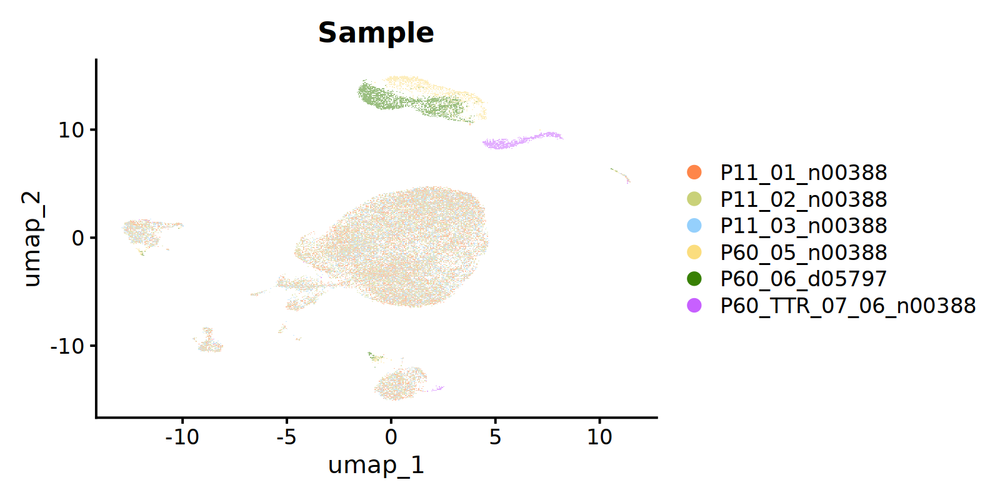

In [ ]:
options(repr.plot.width = 8, repr.plot.height = 4, repr.plot.res = 200)
dpl <- DimPlot(merged, reduction = 'umap', group.by = 'Sample', pt.size = 0.5, raster = TRUE, cols = my_c)

dpl

# Call peaks

In [70]:
merged

An object of class Seurat 
195169 features across 37992 samples within 2 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: ATAC
 2 dimensional reductions calculated: pca, umap

In [71]:
DefaultAssay(merged) <- 'ATAC'

In [72]:
# call peaks using MACS2
peaks <- CallPeaks(object=merged,, 
                outdir='callpeaks_noDBL', cleanup=FALSE)

In [73]:
# remove peaks on nonstandard chromosomes and in genomic blacklist regions
peaks <- keepStandardChromosomes(peaks, pruning.mode = "coarse")
peaks <- subsetByOverlaps(peaks, ranges = blacklist_mm10, invert = TRUE)

In [74]:
macs2_counts <- FeatureMatrix(fragments = Fragments(merged), features = peaks, cells = colnames(merged))

Extracting reads overlapping genomic regions

Extracting reads overlapping genomic regions

Extracting reads overlapping genomic regions

Extracting reads overlapping genomic regions

Extracting reads overlapping genomic regions

Extracting reads overlapping genomic regions



In [77]:
merged[['peaks']] <- CreateChromatinAssay(counts = macs2_counts, sep = c('-', '-'), fragments = Fragments(merged), annotation = annotation)

In [78]:
merged@assays

$RNA
Assay data with 32287 features for 37992 cells
Top 10 variable features:
 Nrxn3, Nkain2, Gm44196, Hgf, Cdc20b, Lsamp, Opcml, Prlr, CreERT2,
Tmeff2 

$ATAC
ChromatinAssay data with 162882 features for 37992 cells
Variable features: 0 
Genome: 
Annotation present: TRUE 
Motifs present: FALSE 
Fragment files: 6 

$peaks
ChromatinAssay data with 183223 features for 37992 cells
Variable features: 0 
Genome: 
Annotation present: TRUE 
Motifs present: FALSE 
Fragment files: 6 


In [ ]:
saveRDS(merged, 'noDBL_merged_peaks.rds')

# FRiP

In [80]:
merged <- FRiP(merged, assay = 'peaks', total.fragments = "nCount_ATAC", col.name = 'FRiP', verbose = TRUE)

Calculating fraction of reads in peaks per cell



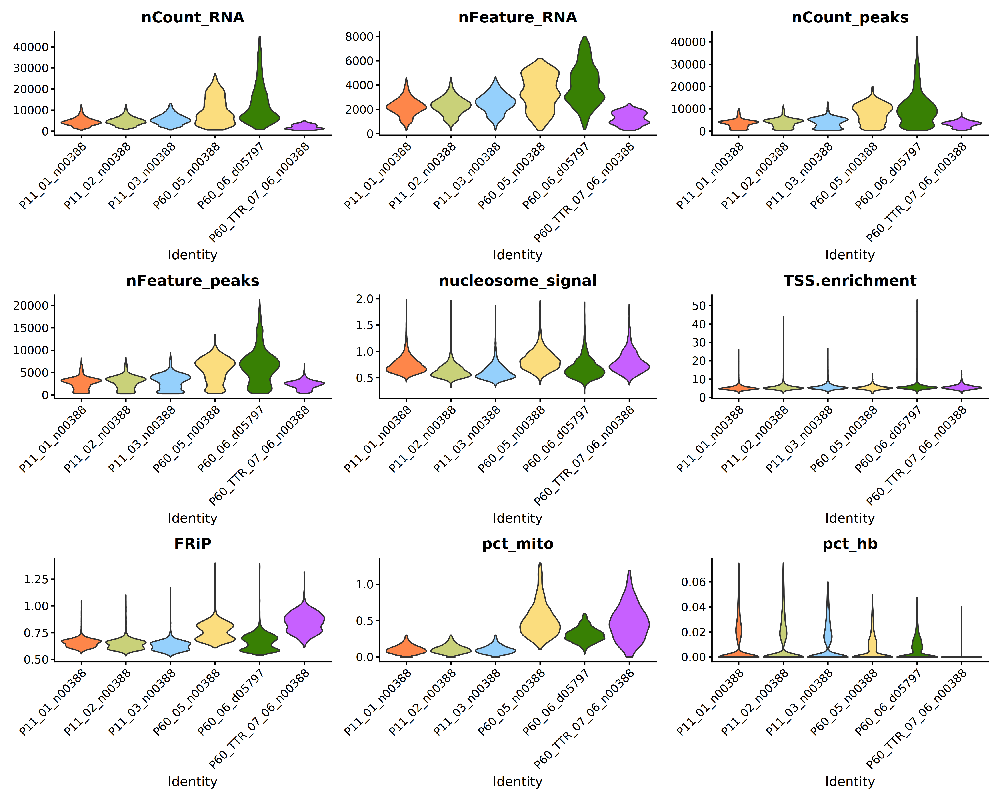

In [ ]:
options(repr.plot.width = 15, repr.plot.height = 12, repr.plot.res = 300)

vln <- VlnPlot(merged, features=c('nCount_RNA', 'nFeature_RNA', 'nCount_peaks', 'nFeature_peaks', 'nucleosome_signal', 'TSS.enrichment', 'FRiP', 'pct_mito', 'pct_hb'), 
        ncol=3, pt.size=0, col = my_c) 

vln

ggsave(file="noDBL_merged_vln_pre_filter_frip.svg", plot=vln, width=15, height=12)


In [ ]:
saveRDS(merged, 'noDBL_merged_peaks.rds')

# Integration and clustering

In [ ]:
merged <- readRDS('noDBL_merged_peaks.rds')

## RNA

In [83]:
table(merged$orig.ident)


       P11_01_n00388        P11_02_n00388        P11_03_n00388 
               11118                12665                 8728 
       P60_05_n00388        P60_06_d05797 P60_TTR_07_06_n00388 
                1590                 2784                 1107 

In [84]:
DefaultAssay(merged) <- 'RNA'

In [85]:
merged <- merged %>% 
                            NormalizeData() %>%
                            FindVariableFeatures(selection.method = "vst", nfeatures=4000, ) %>%
                            ScaleData() %>%
                            RunPCA() 

Centering and scaling data matrix

PC_ 1 
Positive:  Enpp2, Ttr, Prlr, Psap, Bsg, Kl, Arl6ip1, Fth1, Cox8a, Ptgds 
	   Slc22a17, Atp1b1, Ctsd, Chchd10, Cst3, Clu, Pebp1, Ace, Mt3, Rdh5 
	   Cox4i1, Atp5g1, Ppp1r1b, Clic6, 2900040C04Rik, Ldhb, Ndufa13, Hemk1, Cox8b, Map1lc3a 
Negative:  Ebf1, Auts2, Prkg1, Dlc1, Rbpms, Adam12, Rbms3, Adamts9, Lsamp, Lama2 
	   Cped1, Cmip, Fosb, Col4a1, Dach1, Adgrl3, Clic4, Zeb2, Cp, Itga8 
	   Adamts12, Epb41l2, Emcn, Plpp3, Pde7b, Arhgap31, Ldb2, Vcl, Nid1, Zswim6 
PC_ 2 
Positive:  Syt1, Fgf14, Erbb4, Dach2, Rtl4, Adamtsl1, Ppargc1a, Immp2l, Spag16, Slc35f1 
	   Atp2b3, Ppp2r2b, Strip2, A830018L16Rik, Pip5k1b, Tmem72, Kcnd2, Cacna2d3, 2810403D21Rik, Cdh18 
	   Lrp1b, Car12, Tox, Col8a1, Negr1, Gm29266, Adamtsl3, Gm42047, Tll1, Slc4a5 
Negative:  Ebf1, Adam12, Lsamp, Lama2, Cped1, Igfbp7, Rbpms, Dlc1, Cp, Adgrl3 
	   Auts2, Itga8, Fosb, Adamts9, Cmip, Rbms3, Prkg1, Cemip, Zeb2, Emcn 
	   Clic4, Adamts12, Alpl, Fam155a, Nid1, Moxd1, Col4a1, Mgp, Plpp3

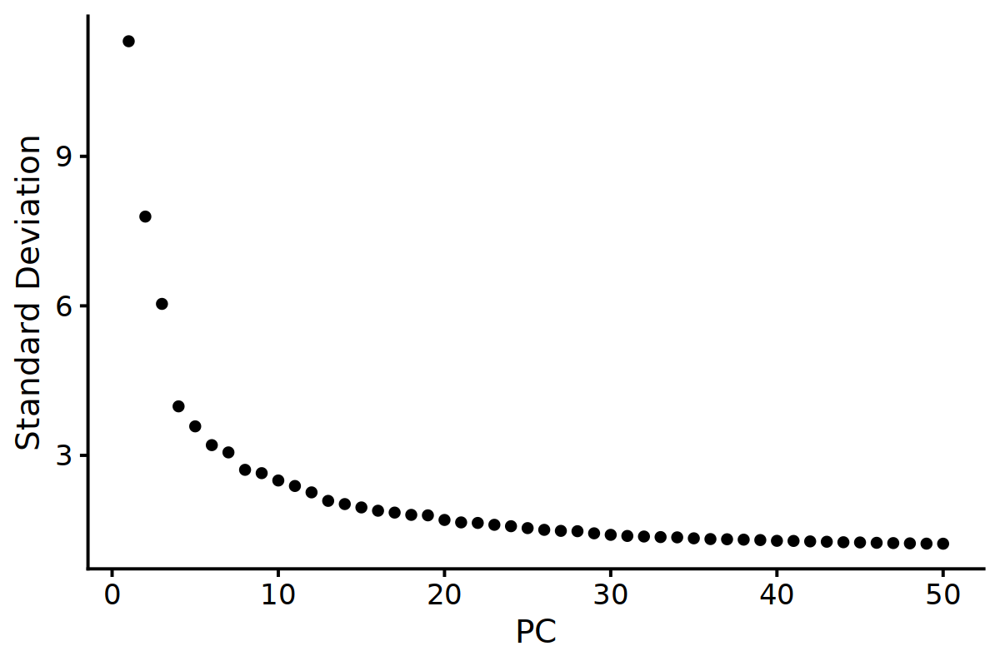

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
pca <- ElbowPlot(merged, ndims = 50)

pca

ggsave(file="noDBL_Merged_pca.svg", plot=pca, width=6, height=4)

In [87]:
merged <- RunUMAP(merged, dims = 1:22, reduction = 'pca', n.neighbors = 15, reduction.name="umapRNA")

11:37:04 UMAP embedding parameters a = 0.9922 b = 1.112

11:37:04 Read 37992 rows and found 22 numeric columns

11:37:04 Using Annoy for neighbor search, n_neighbors = 15

11:37:04 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

11:37:07 Writing NN index file to temp file /tmp/RtmpoVZTt9/filef8c2672502b36

11:37:07 Searching Annoy index using 1 thread, search_k = 1500

11:37:15 Annoy recall = 100%

11:37:18 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 15

11:37:22 Initializing from normalized Laplacian + noise (using RSpectra)

11:37:25 Commencing optimization for 200 epochs, with 828196 positive edges

11:37:39 Optimization finished



In [88]:
unique(merged$Age)

[1] "P11" "P60"

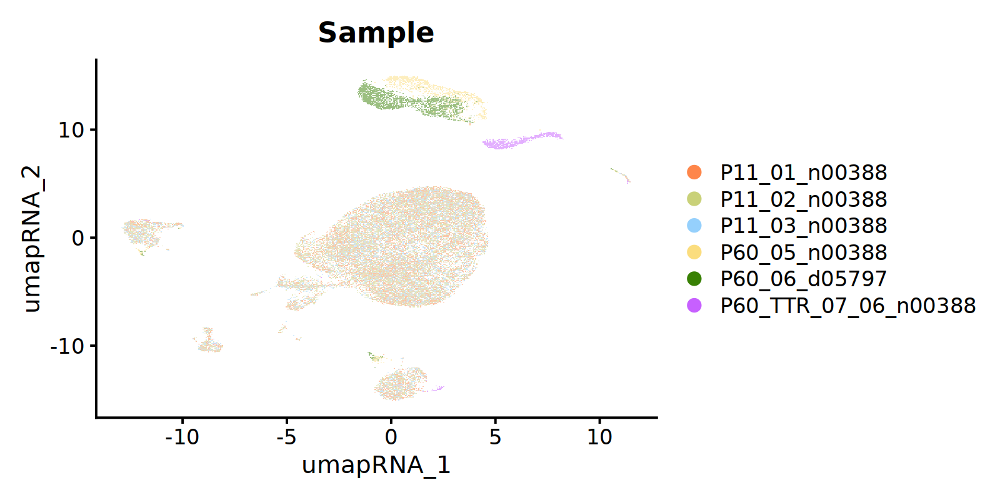

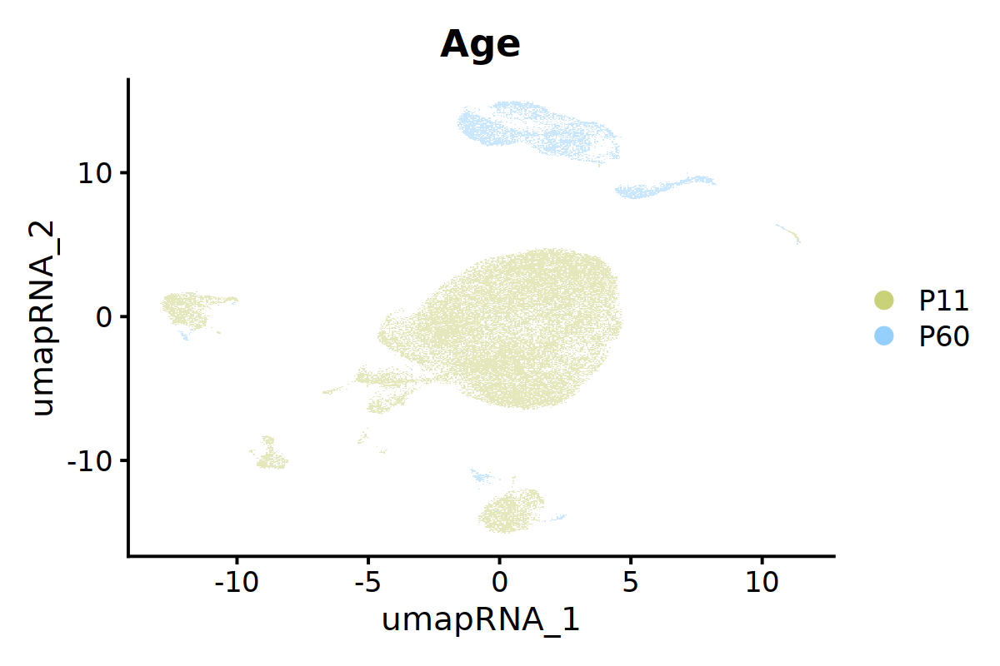

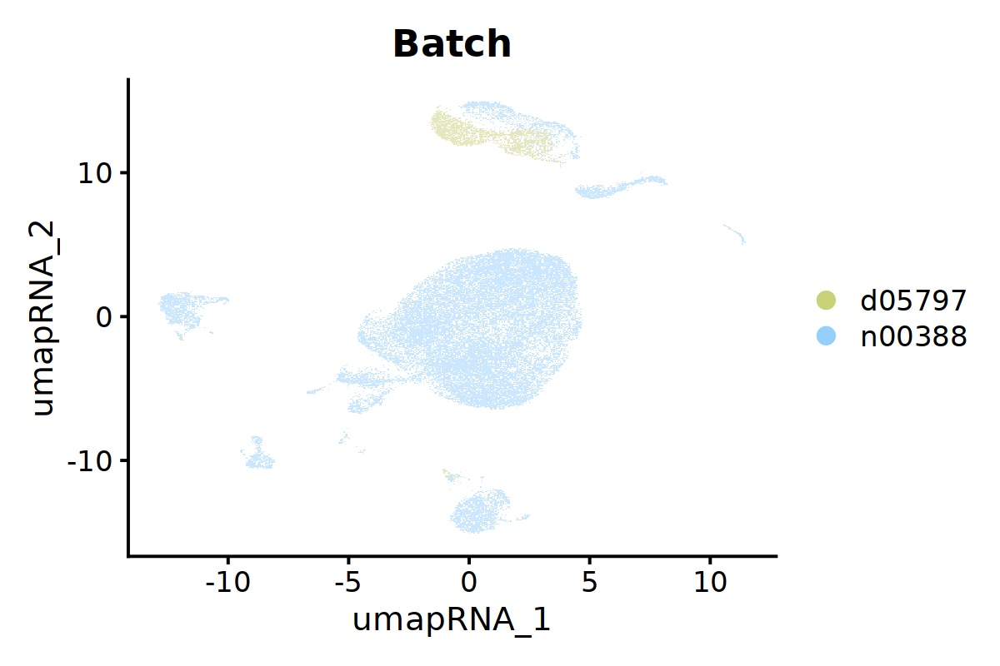

In [ ]:
options(repr.plot.width = 8, repr.plot.height = 4, repr.plot.res = 200)
before_umap_s <- DimPlot(merged, reduction = 'umapRNA', group.by = 'Sample', pt.size = 0.5, raster = TRUE, cols = my_c)

before_umap_s

ggsave(file="noDBL_Merged_Sample_UMAP.svg", plot=before_umap_s, width=8, height=4)


options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
before_umap_a <- DimPlot(merged, reduction = 'umapRNA', group.by = 'Age', pt.size = 0.5, raster = TRUE, cols = my_c[2:3])

before_umap_a

ggsave(file="noDBL_Merged_Age_UMAP.svg", plot=before_umap_a, width=6, height=4)

options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
before_umap_a <- DimPlot(merged, reduction = 'umapRNA', group.by = 'Batch', pt.size = 0.5, raster = TRUE, cols = my_c[2:3])

before_umap_a

ggsave(file="noDBL_Merged_Batch_UMAP.svg", plot=before_umap_a, width=6, height=4)

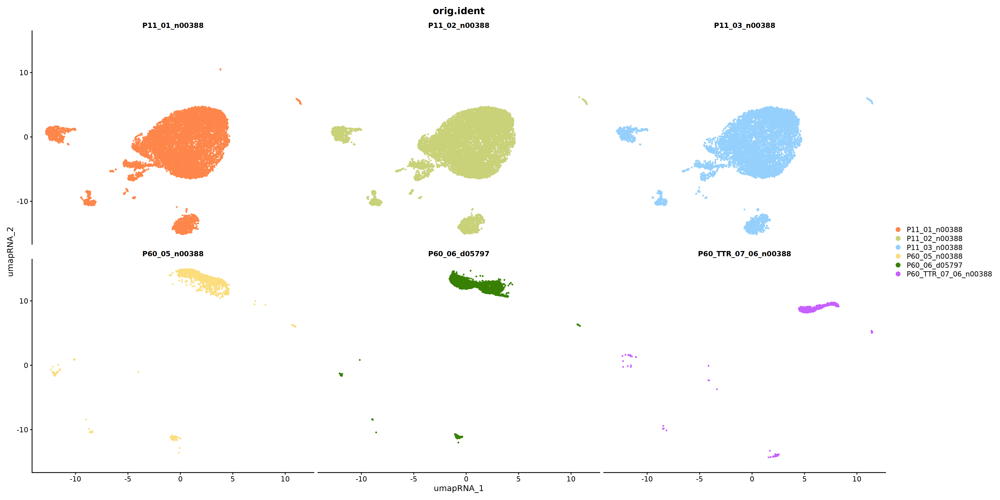

In [ ]:
options(repr.plot.width=24, repr.plot.height=12)
dpl <- DimPlot(merged, group.by="orig.ident", split.by="orig.ident", reduction="umapRNA", shuffle=TRUE, cols=my_c, ncol=3, pt.size=0.5, label=FALSE)

dpl


ggsave(file="noDBL_Merged_each_sample_UMAP.svg", plot=dpl, width=24, height=12)

### Integration with Harmony

In [9]:
library(harmony)

Warning message:
“package ‘harmony’ was built under R version 4.3.3”
Loading required package: Rcpp

Warning message:
“package ‘Rcpp’ was built under R version 4.3.3”


In [93]:
integrated <- RunHarmony(merged, group.by.vars = 'Sample', reduction.save = 'harmonyRNA')

Transposing data matrix

Initializing state using k-means centroids initialization

Harmony 1/10

Harmony 2/10

Harmony 3/10

Harmony 4/10

Harmony 5/10

Harmony 6/10

Harmony 7/10

Harmony 8/10

Harmony 9/10

Harmony 10/10



In [94]:
integrated

An object of class Seurat 
378392 features across 37992 samples within 3 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 2 other assays present: ATAC, peaks
 4 dimensional reductions calculated: pca, umap, umapRNA, harmonyRNA

In [95]:
integrated <- RunUMAP(integrated, reduction = 'harmonyRNA', dims = 1:22, n.neighbors = 15, reduction.name="harmony_RNA")

11:38:45 UMAP embedding parameters a = 0.9922 b = 1.112

11:38:45 Read 37992 rows and found 22 numeric columns

11:38:45 Using Annoy for neighbor search, n_neighbors = 15

11:38:45 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

11:38:48 Writing NN index file to temp file /tmp/RtmpoVZTt9/filef8c2643fb8e5c

11:38:48 Searching Annoy index using 1 thread, search_k = 1500

11:38:57 Annoy recall = 100%

11:38:59 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 15

11:39:03 Initializing from normalized Laplacian + noise (using RSpectra)

11:39:07 Commencing optimization for 200 epochs, with 843434 positive edges

11:39:21 Optimization finished

Warning message:
“Key ‘harmonyRNA_’ taken, using ‘harmonyrna_’ instead”


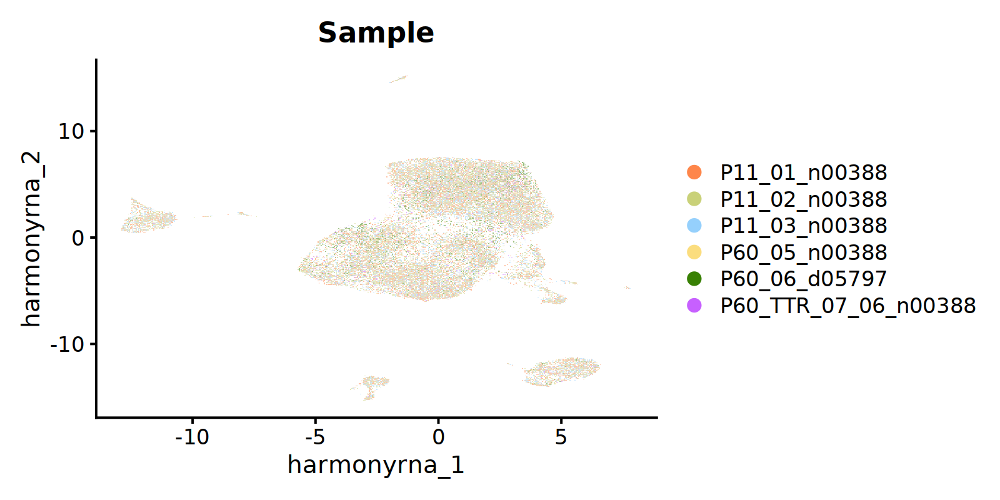

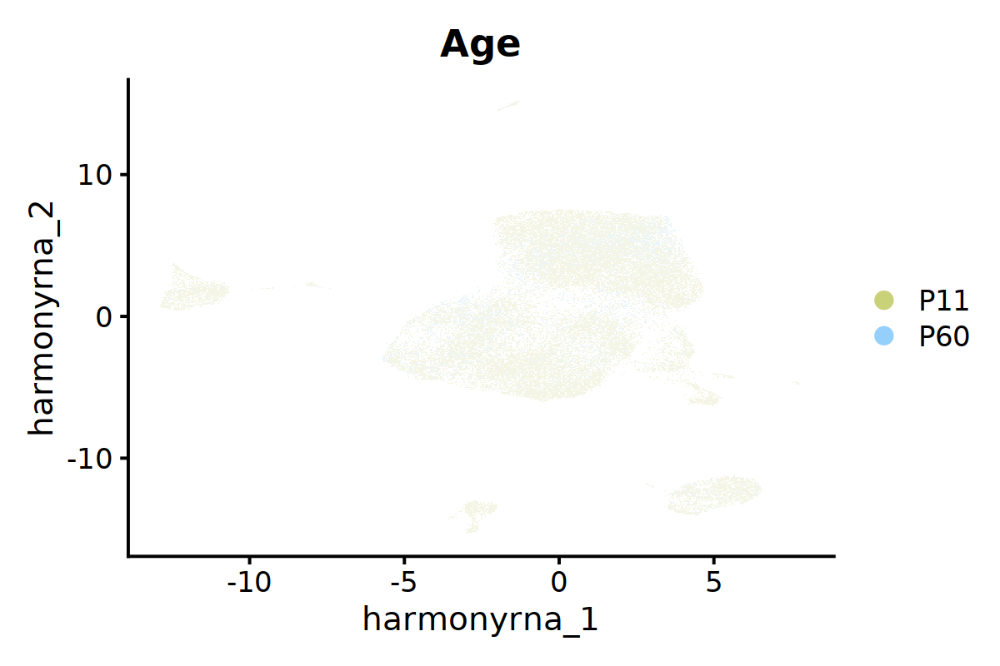

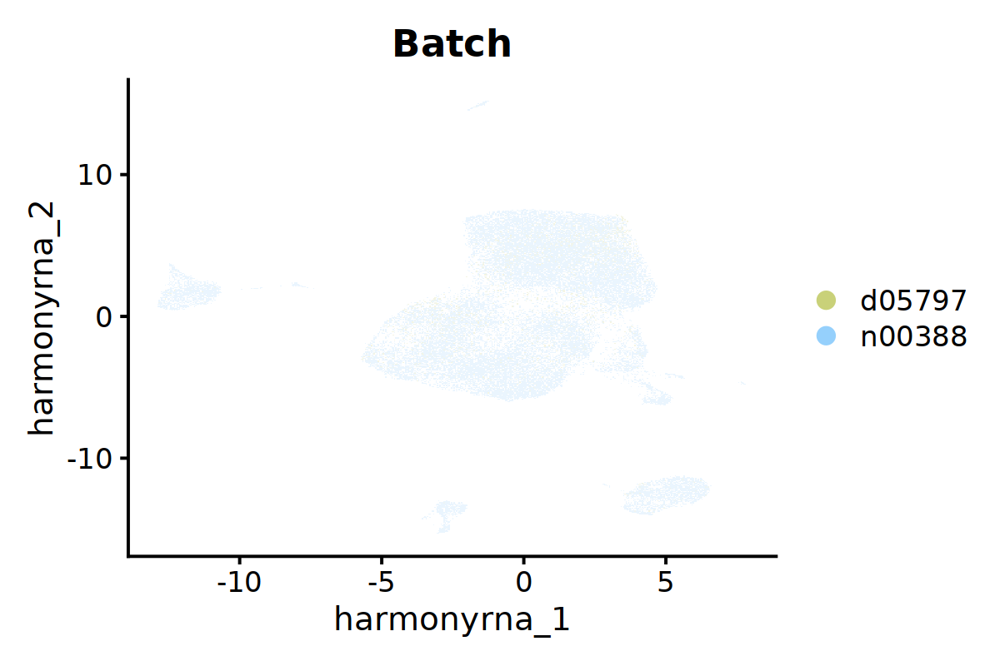

In [ ]:
options(repr.plot.width = 8, repr.plot.height = 4, repr.plot.res = 200)
after_umap_s <- DimPlot(integrated, reduction = 'harmony_RNA', group.by = 'Sample', pt.size = 0.5, raster = TRUE, cols = my_c)

after_umap_s

ggsave(file="noDBL_Harmony_RNA_sample_UMAP.svg", plot=after_umap_s, width=8, height=4)


options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
after_umap_a <- DimPlot(integrated, reduction = 'harmony_RNA', group.by = 'Age', pt.size = 0.2, raster = TRUE, cols = my_c[2:3])

after_umap_a

ggsave(file="noDBL_Harmony_RNA_Age_UMAP.svg", plot=after_umap_a, width=6, height=4)

options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
after_umap_b <- DimPlot(integrated, reduction = 'harmony_RNA', group.by = 'Batch', pt.size = 0.2, raster = TRUE, cols = my_c[2:3])

after_umap_b

ggsave(file="noDBL_Harmony_RNA_Batch_UMAP.svg", plot=after_umap_b, width=6, height=4)


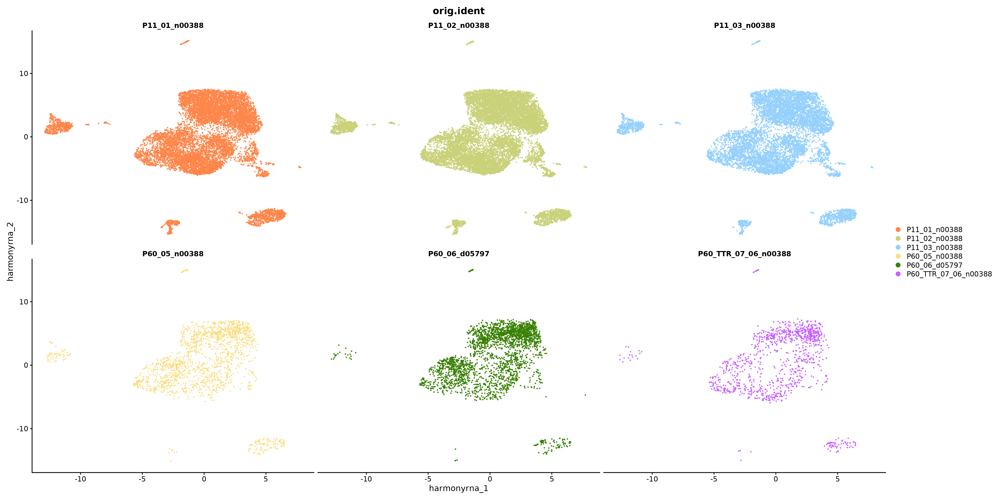

In [ ]:
options(repr.plot.width=24, repr.plot.height=12)
dpl <- DimPlot(integrated, group.by="orig.ident", split.by="orig.ident", reduction="harmony_RNA", shuffle=TRUE, 
               cols=my_c, ncol=3, pt.size=0.2, label=FALSE)

dpl

ggsave(file="noDBL_Harmony_each_sample_UMAP.svg", plot=dpl, width=24, height=12)

In [ ]:
saveRDS(integrated, 'noDBL_merged_peaks_clusters.rds')

# Peaks

In [ ]:
integrated <- readRDS('noDBL_merged_peaks_clusters.rds')

## Normalization and dimensional reduction

In [104]:
DefaultAssay(integrated)<-'peaks'
integrated<-FindTopFeatures(integrated,min.cutoff = NULL)
integrated<-RunTFIDF(integrated) #Run term frequency inverse document frequency (TF-IDF) normalization on a matrix.
integrated<-RunSVD(integrated)

Performing TF-IDF normalization

Running SVD

Scaling cell embeddings



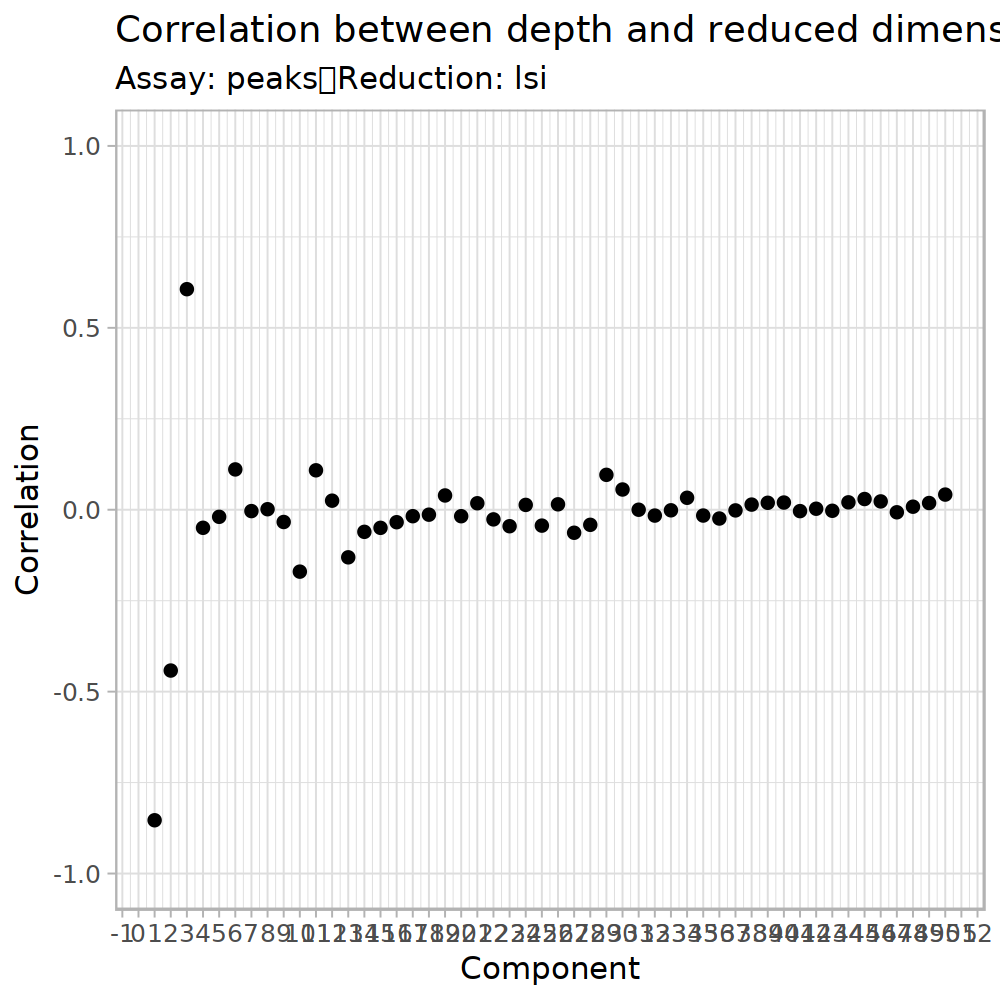

In [105]:
options(repr.plot.width = 5, repr.plot.height = 5, repr.plot.res = 200)
DepthCor(integrated,n=50,reduction = 'lsi')

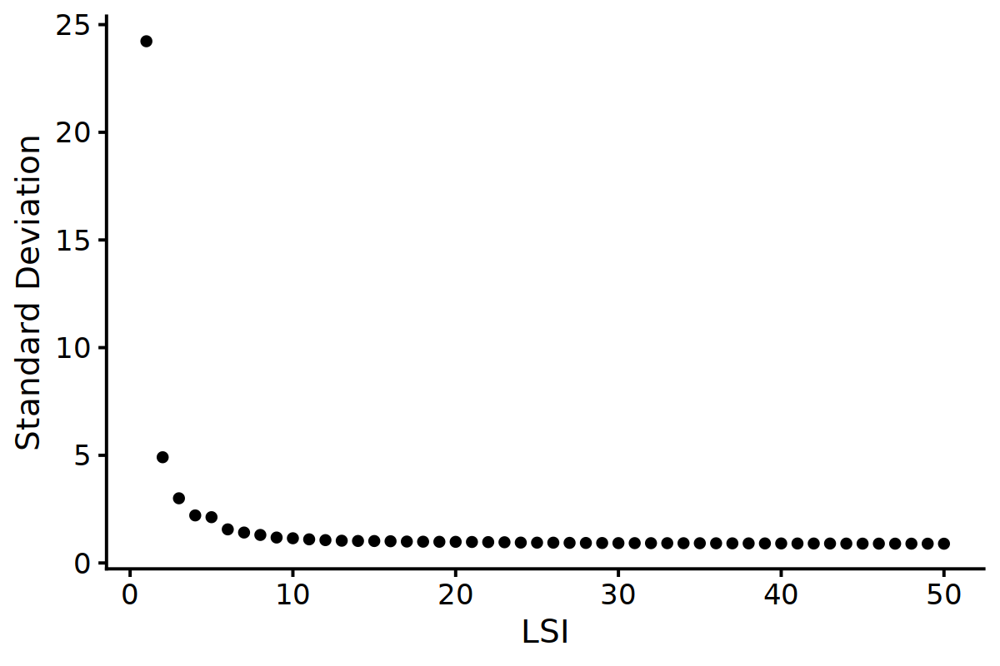

In [ ]:
options(repr.plot.width=6, repr.plot.height=4)
ebl <- ElbowPlot(integrated, reduction = "lsi", n=50)

ebl

ggsave(file="noDBL_Merged_depthCorr_ebl.svg", plot=ebl, width=6, height=4)

In [110]:
integrated <- RunUMAP(integrated,reduction = 'lsi',dims = 2:30,reduction.name = 'atac.umap')
integrated <- FindNeighbors(integrated,reduction = 'lsi',dims = 2:30)

11:55:53 UMAP embedding parameters a = 0.9922 b = 1.112

11:55:53 Read 37992 rows and found 29 numeric columns

11:55:53 Using Annoy for neighbor search, n_neighbors = 30

11:55:53 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

11:55:55 Writing NN index file to temp file /tmp/RtmpoVZTt9/filef8c2613345202

11:55:55 Searching Annoy index using 1 thread, search_k = 3000

11:56:10 Annoy recall = 100%

11:56:12 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

11:56:16 Initializing from normalized Laplacian + noise (using RSpectra)

11:56:17 Commencing optimization for 200 epochs, with 1618798 positive edges

11:56:35 Optimization finished

Computing nearest neighbor graph

Computing SNN



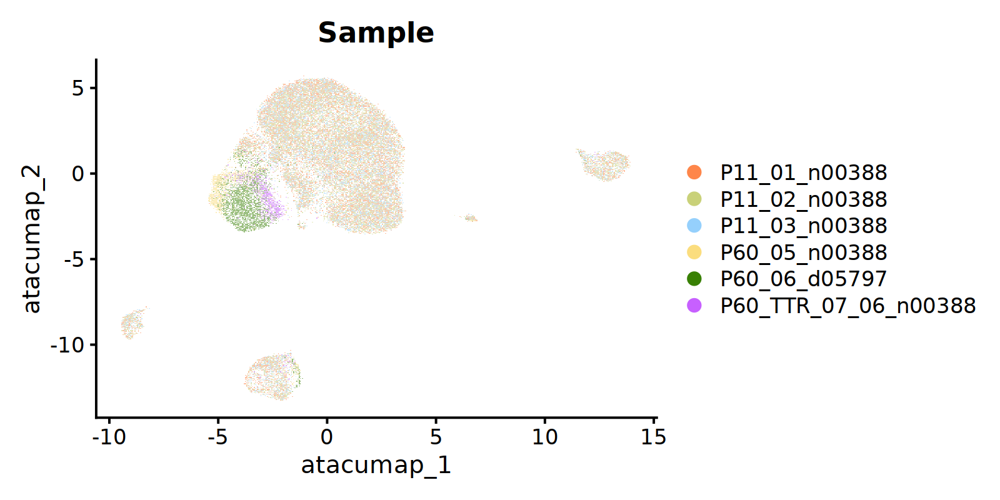

In [ ]:
options(repr.plot.width=8, repr.plot.height=4)
dpl <- DimPlot(integrated, group.by="Sample", reduction="atac.umap", pt.size = 0.5, raster = TRUE, cols = my_c, label=FALSE)

dpl 

ggsave(file="noDBL_integrated_Peaks_Sample_UMAP.svg", plot=dpl, width=8, height=4)

## Integration with Harmony

In [112]:
library(harmony)

In [113]:
integrated <- RunHarmony(integrated, group.by.vars = 'Sample', reduction = 'lsi', assay.use = 'peaks', reduction.save = 'harmonyPeaks', project.dim = FALSE)

Transposing data matrix

Initializing state using k-means centroids initialization

Warning message:
“did not converge in 25 iterations”
Harmony 1/10

Harmony 2/10

Harmony 3/10

Harmony 4/10

Harmony 5/10

Harmony 6/10

Harmony converged after 6 iterations



In [114]:
# re-compute the UMAP using corrected LSI embeddings
integrated <- RunUMAP(integrated, dims = 2:30, reduction = 'harmonyPeaks', reduction.name = 'harmony_Peaks')

11:57:31 UMAP embedding parameters a = 0.9922 b = 1.112

11:57:31 Read 37992 rows and found 29 numeric columns

11:57:31 Using Annoy for neighbor search, n_neighbors = 30

11:57:31 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

11:57:34 Writing NN index file to temp file /tmp/RtmpoVZTt9/filef8c262fedc25c

11:57:34 Searching Annoy index using 1 thread, search_k = 3000

11:57:46 Annoy recall = 100%

11:57:48 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

11:57:53 Initializing from normalized Laplacian + noise (using RSpectra)

11:57:53 Commencing optimization for 200 epochs, with 1644144 positive edges

11:58:11 Optimization finished

Warning message:
“Key ‘harmonyPeaks_’ taken, using ‘harmonypeaks_’ instead”


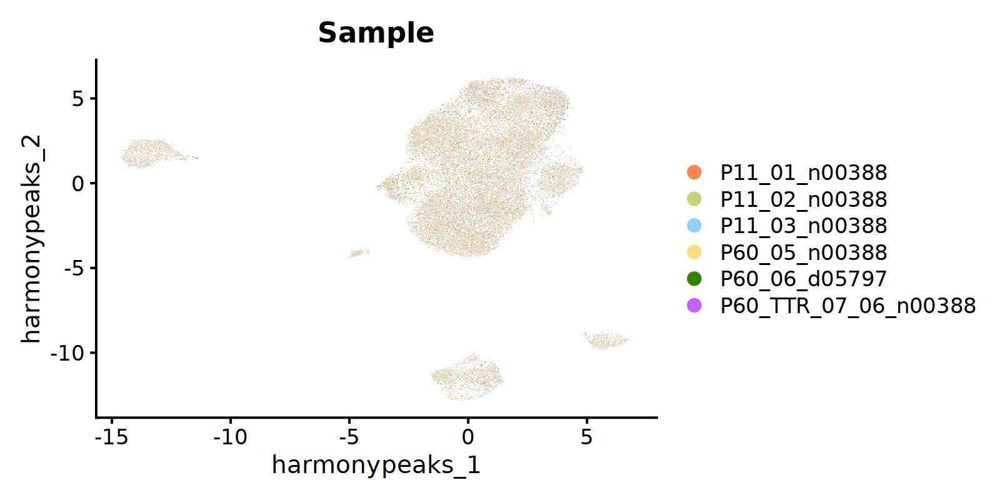

In [ ]:
options(repr.plot.width=8, repr.plot.height=4)
dpl <- DimPlot(integrated, group.by = 'Sample', pt.size = 0.5, raster=TRUE, cols=my_c, reduction = 'harmony_Peaks')

dpl

ggsave(file="noDBL_integrated_Peaks_Sample_UMAP.svg", plot=dpl, width=8, height=4)

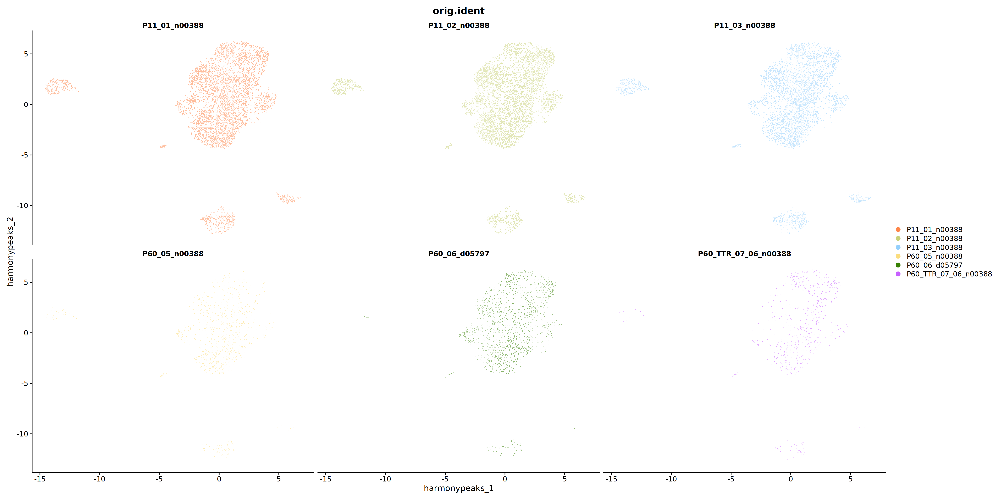

In [ ]:
options(repr.plot.width=24, repr.plot.height=12)
dpl <- DimPlot(integrated, group.by="orig.ident", split.by="orig.ident", reduction="harmony_Peaks", shuffle=TRUE, cols=my_c, ncol=3, pt.size=0.5, raster = TRUE, label=FALSE)

dpl

ggsave(file="noDBL_integrated_Peaks_each_Sample_UMAP.svg", plot=dpl, width=24, height=12)

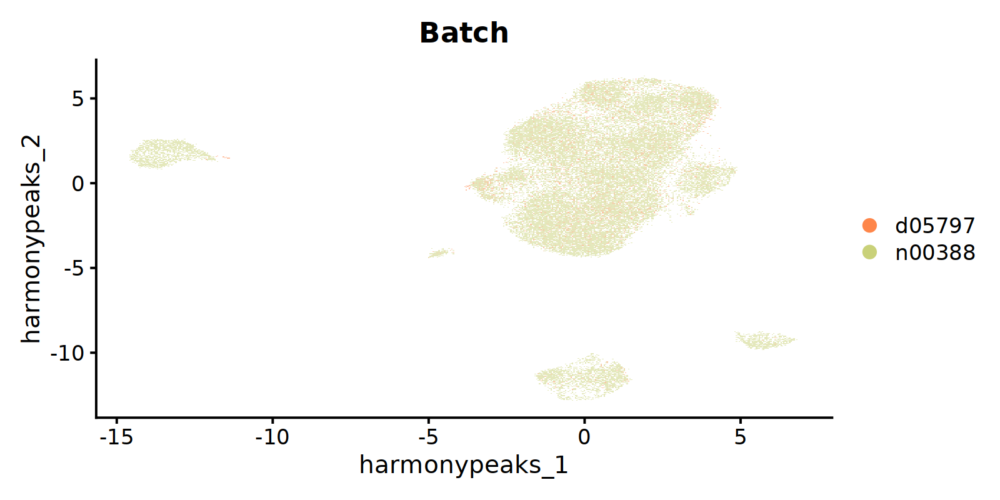

In [ ]:
options(repr.plot.width=8, repr.plot.height=4)
dpl <- DimPlot(integrated, group.by="Batch", reduction="harmony_Peaks", pt.size = 0.5, raster = TRUE, cols = my_c, label=FALSE)

dpl

ggsave(file="noDBL_integrated_Peaks_Batch_UMAP.svg", plot=dpl, width=8, height=4)

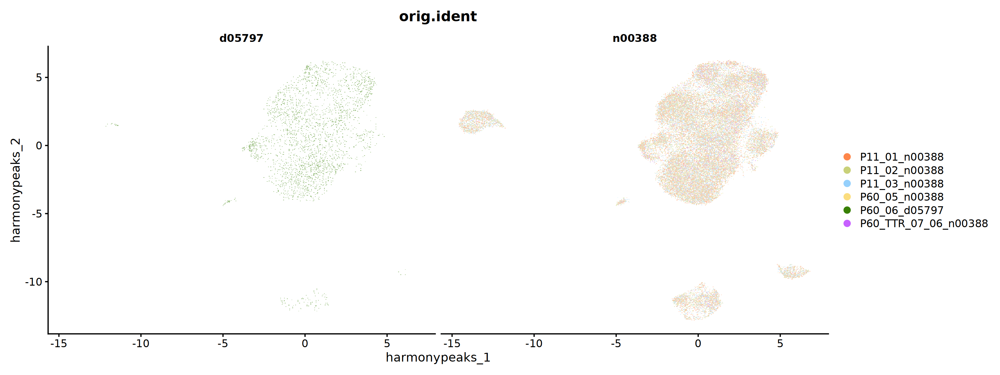

In [ ]:
options(repr.plot.width=16, repr.plot.height=6)
dpl <- DimPlot(integrated, group.by="orig.ident", split.by="Batch", reduction="harmony_Peaks", shuffle=TRUE, cols=my_c, ncol=5, pt.size=0.5, raster = TRUE, label=FALSE)

dpl

ggsave(file="noDBL_integrated_Peaks_each_batch_UMAP.svg", plot=dpl, width=16, height=6)

In [ ]:
saveRDS(integrated, 'noDBL_merged_peaks_clusters.rds')

# Joint vizualization

In [ ]:
integrated <- readRDS('noDBL_merged_peaks_clusters.rds')

In [120]:
integrated@reductions

$pca
A dimensional reduction object with key PC_ 
 Number of dimensions: 50 
 Number of cells: 37992 
 Projected dimensional reduction calculated:  FALSE 
 Jackstraw run: FALSE 
 Computed using assay: RNA 

$umap
A dimensional reduction object with key umap_ 
 Number of dimensions: 2 
 Number of cells: 37992 
 Projected dimensional reduction calculated:  FALSE 
 Jackstraw run: FALSE 
 Computed using assay: RNA 

$umapRNA
A dimensional reduction object with key umapRNA_ 
 Number of dimensions: 2 
 Number of cells: 37992 
 Projected dimensional reduction calculated:  FALSE 
 Jackstraw run: FALSE 
 Computed using assay: RNA 

$harmonyRNA
A dimensional reduction object with key harmonyRNA_ 
 Number of dimensions: 50 
 Number of cells: 37992 
 Projected dimensional reduction calculated:  TRUE 
 Jackstraw run: FALSE 
 Computed using assay: RNA 

$harmony_RNA
A dimensional reduction object with key harmonyrna_ 
 Number of dimensions: 2 
 Number of cells: 37992 
 Projected dimensional reductio

In [121]:
integrated

An object of class Seurat 
378392 features across 37992 samples within 3 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 2 other assays present: ATAC, peaks
 9 dimensional reductions calculated: pca, umap, umapRNA, harmonyRNA, harmony_RNA, lsi, atac.umap, harmonyPeaks, harmony_Peaks

In [122]:
integrated <- FindMultiModalNeighbors(integrated, reduction.list = c('harmonyRNA', 'harmonyPeaks'),
                                       dims.list = list(1:22,2:30), verbose=TRUE)

Calculating cell-specific modality weights

Finding 20 nearest neighbors for each modality.

Calculating kernel bandwidths

Finding multimodal neighbors

Constructing multimodal KNN graph

Constructing multimodal SNN graph



In [123]:
integrated <- RunUMAP(integrated, nn.name = "weighted.nn", assay = "RNA", reduction.name = 'multiome.umap',  verbose = TRUE)

12:07:33 UMAP embedding parameters a = 0.9922 b = 1.112

12:07:36 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 20

12:07:42 Initializing from normalized Laplacian + noise (using RSpectra)

12:07:44 Commencing optimization for 200 epochs, with 1236766 positive edges

12:08:04 Optimization finished



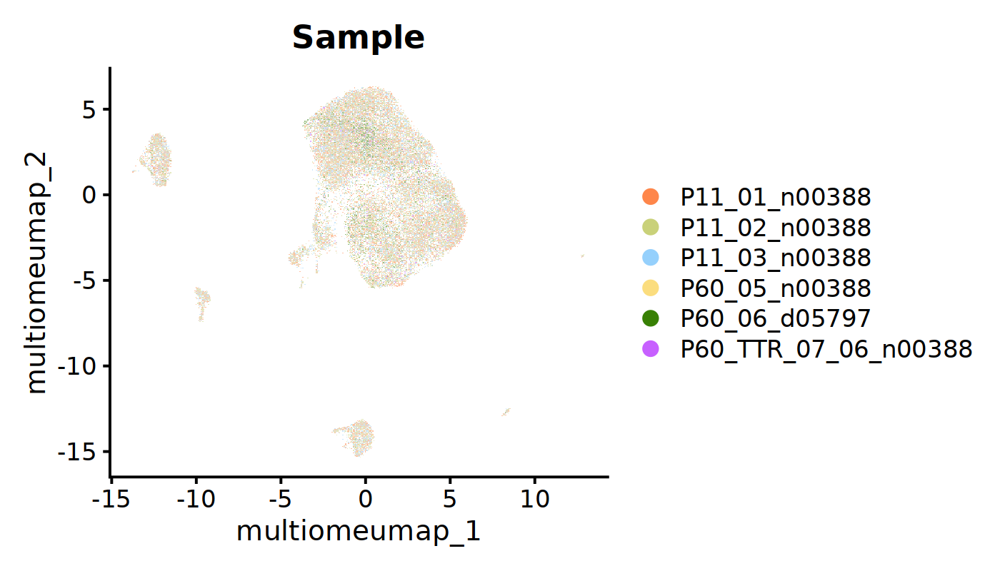

In [ ]:
options(repr.plot.width = 7, repr.plot.height = 4, repr.plot.res = 200)
dpt <- DimPlot(integrated, group.by = "Sample", pt.size=0.5, raster = TRUE, cols = my_c, label = FALSE, repel = TRUE, reduction = 'multiome.umap')

dpt

ggsave(file="noDBL_integrated_clusters_Sample_Multiome.svg", plot=dpt, width=7, height=5)

In [127]:
DefaultAssay(integrated) <- 'RNA'

In [ ]:
saveRDS(integrated, 'noDBL_merged_peaks_clusters_joint.rds')

# Cell types

In [ ]:
integrated <- readRDS('noDBL_merged_peaks_clusters_joint.rds')

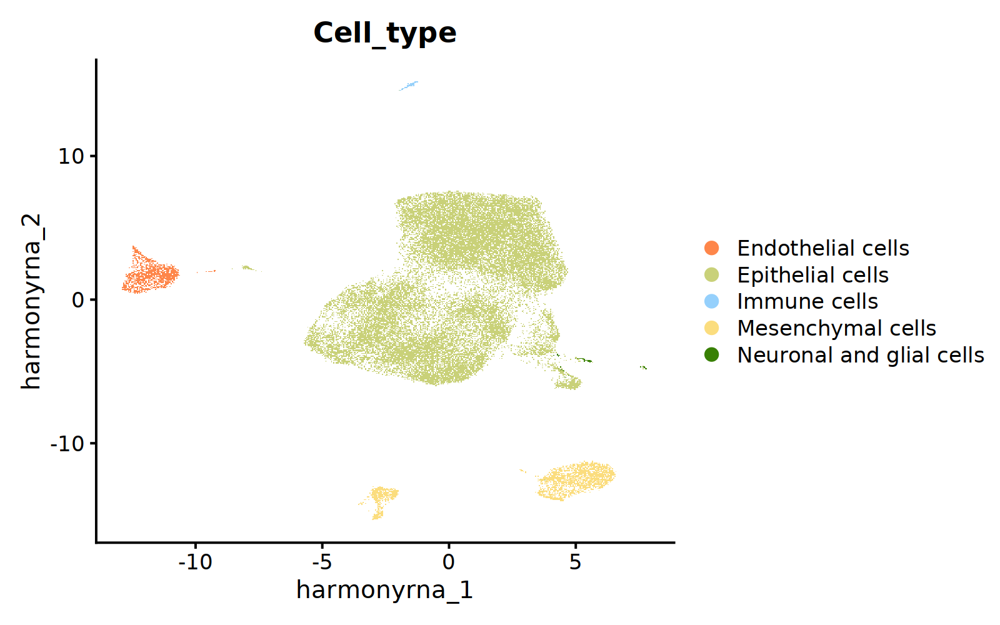

In [ ]:
options(repr.plot.width = 8, repr.plot.height = 5, repr.plot.res = 200)
dmp <- DimPlot(object = integrated, label = FALSE,group.by='Cell_type', cols = my_c, 
               reduction = 'harmony_RNA', raster = TRUE, pt.size = 1.0)

dmp

ggsave(file="noDBL_Harmony_noDBL_Cell_type_RNA_umap.svg", plot=dmp, width=8, height=5)

In [36]:
integrated <- SetIdent(integrated, value = 'Cell_type')

In [14]:
integrated_predicted.markers <- FindAllMarkers(integrated, test.use="wilcox", only.pos=TRUE, max.cells.per.ident=15)

Calculating cluster Epithelial cells

Calculating cluster Mesenchymal cells

Calculating cluster Endothelial cells

Calculating cluster Neuronal and glial cells

Calculating cluster Immune cells



In [15]:
write.csv(integrated_predicted.markers, 'noDBL_Markers_RNA_All.csv', row.names = TRUE)

In [16]:
integrated_predicted.markers %>% group_by(cluster) %>%
                                slice_head(n = 10) %>%
                                ungroup() -> top10_predicted

In [17]:
top10_predicted <- top10_predicted[!duplicated(top10_predicted$gene), ]

Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.


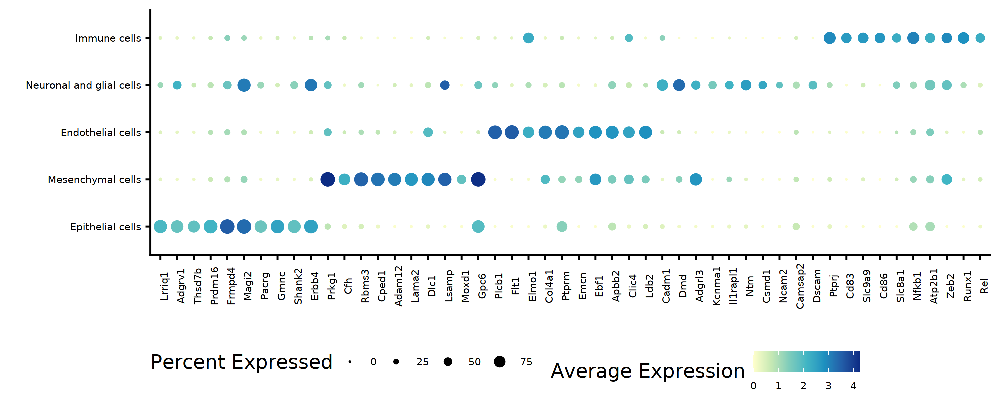

In [ ]:
options(repr.plot.width = 10, repr.plot.height = 4, repr.plot.res = 300)
dtp <- DotPlot(integrated, features = top10_predicted$gene, col.min = 0, col.max = 4, dot.scale = 4, scale=FALSE) + theme(axis.text.x=element_text(size=7, angle = 90),axis.text.y=element_text(size=7), 
                                                                                                 legend.position = 'bottom', legend.direction = 'horizontal', 
                                                                                                  legend.text = element_text(size=7)) + xlab('') + ylab('') & scale_color_distiller(palette = "YlGnBu", direction = 1)

dtp

ggsave(file="noDBL_All_integrated_dotplot_Cell_type.svg", plot=dtp, width=10, height=6)

# Marker genes on different umaps assays

## RNA

In [ ]:
DefaultAssay(integrated) <- 'RNA'

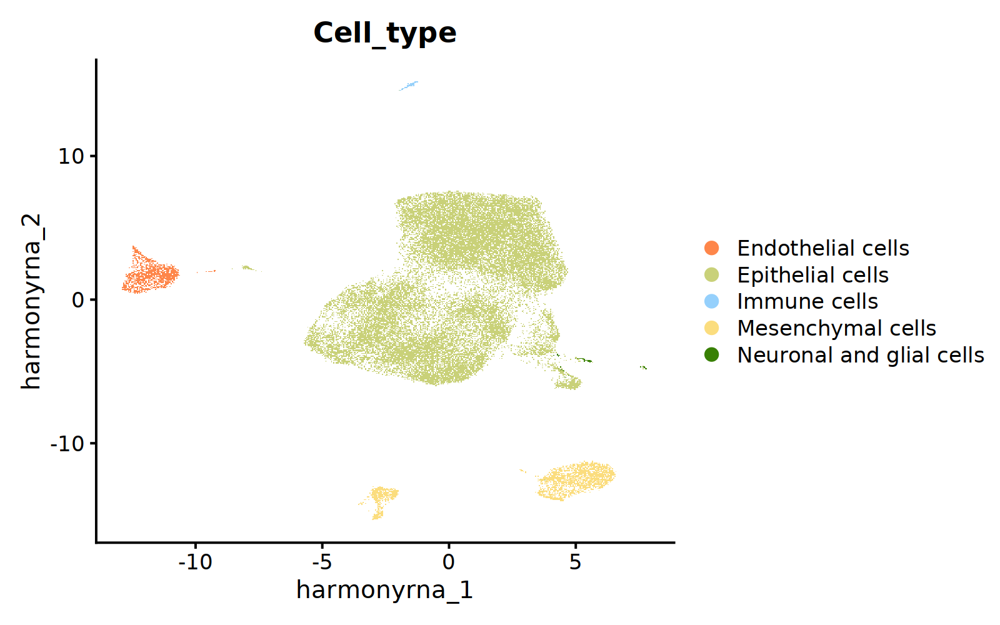

In [ ]:
options(repr.plot.width = 8, repr.plot.height = 5, repr.plot.res = 200)
dmp <- DimPlot(object = integrated, label = FALSE,group.by='Cell_type', cols = my_c, 
               reduction = 'harmony_RNA', raster = TRUE, pt.size = 1.0)

dmp

ggsave(file="noDBL_Harmony_noDBL_Cell_type_RNA_umap.svg", plot=dmp, width=8, height=5)

Warning message:
“Could not find Folr1 in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find Clic6 in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find Krt18 in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find Ttr in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find Dcn in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find Lama2 in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find Adam12 in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find Cfh in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find Plvap in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find Pecam1 in the default search locations, found in ‘RNA’

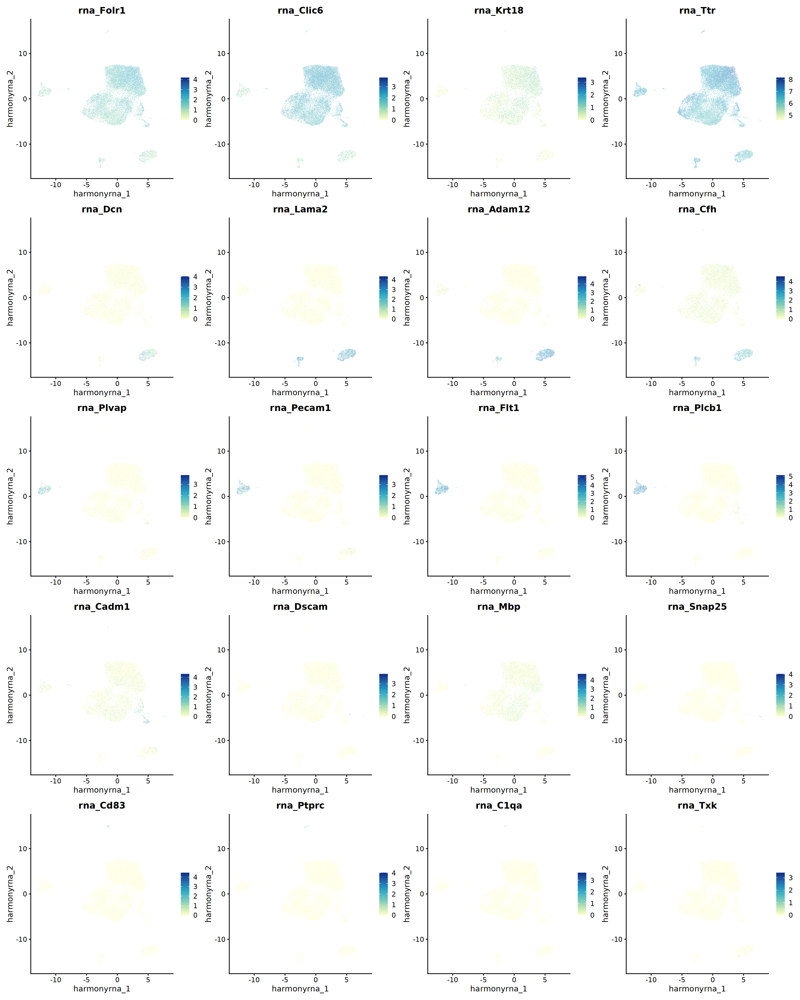

In [ ]:
options(repr.plot.width = 20, repr.plot.height = 25, repr.plot.res = 200)
ftp <- FeaturePlot(integrated, reduction = 'harmony_RNA', features = markers, 
             min.cutoff = 0, label.size = 2, ncol = 4, pt.size = 0.5, raster=TRUE) & scale_color_distiller(palette = "YlGnBu", direction = 1)
ftp 


ggsave(file="noDBL_harmonyRNA_geneExpression.svg", plot=ftp, width=20, height=35)

## Peaks

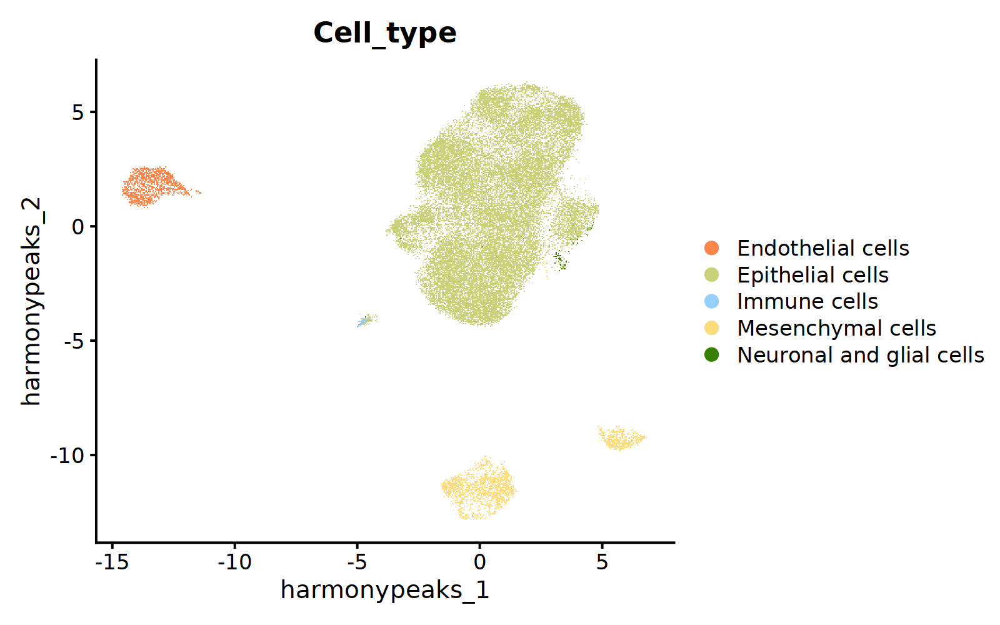

In [ ]:
options(repr.plot.width = 8, repr.plot.height = 5, repr.plot.res = 200)
dmp <- DimPlot(object = integrated, label = FALSE,group.by='Cell_type', cols = my_c, 
               reduction = 'harmony_Peaks', raster = TRUE, pt.size = 1.0)

dmp

ggsave(file="noDBL_Harmony_noDBL_Cell_type_peaks_umap.svg", plot=dmp, width=8, height=5)

Warning message:
“Could not find Folr1 in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find Clic6 in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find Krt18 in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find Ttr in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find Dcn in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find Lama2 in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find Adam12 in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find Cfh in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find Plvap in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find Pecam1 in the default search locations, found in ‘RNA’

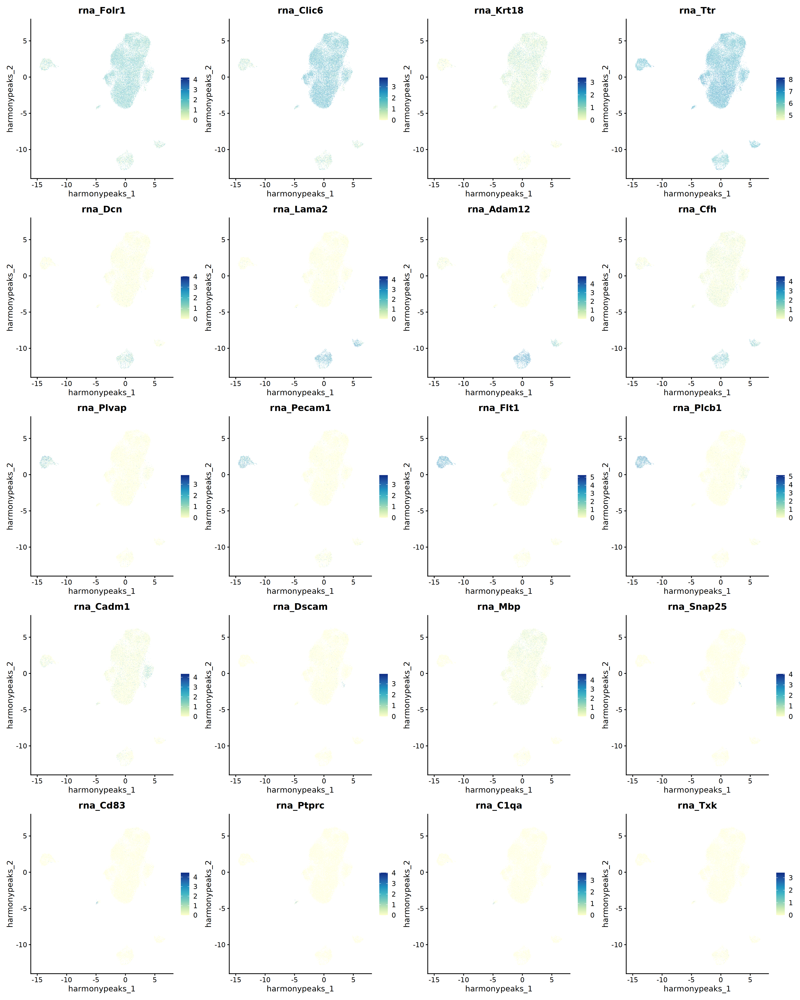

In [ ]:
options(repr.plot.width = 20, repr.plot.height = 25, repr.plot.res = 200)
ftp <- FeaturePlot(integrated, reduction = 'harmony_Peaks', features = markers, 
             min.cutoff = 0, label.size = 2, ncol = 4, pt.size = 0.5, raster=TRUE) & scale_color_distiller(palette = "YlGnBu", direction = 1)
ftp 


ggsave(file="noDBL_harmonyPeaks_geneExpression.svg", plot=ftp, width=20, height=35)

## Joint

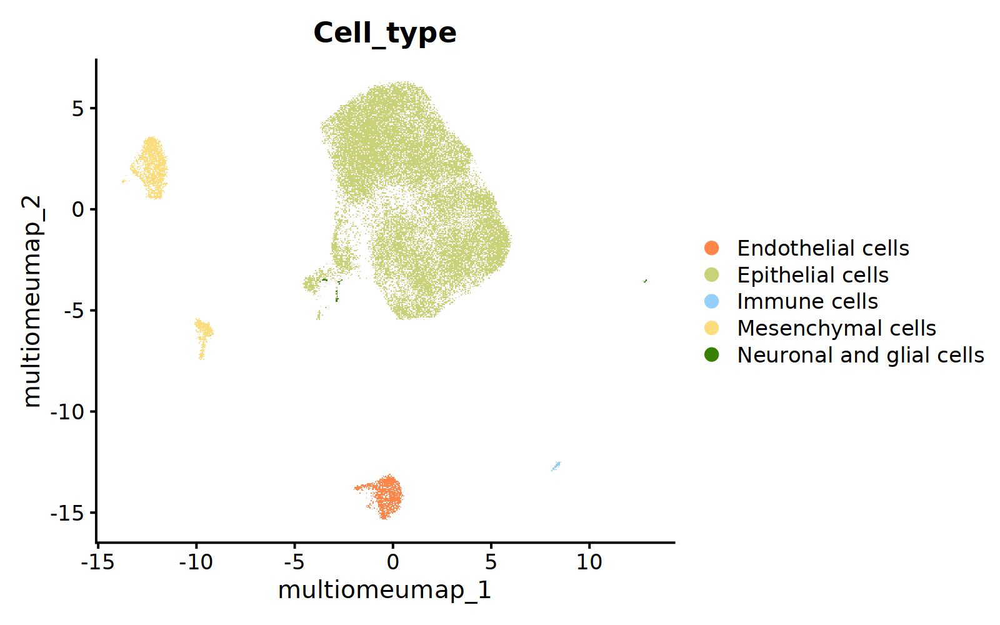

In [ ]:
options(repr.plot.width = 8, repr.plot.height = 5, repr.plot.res = 200)
dmp <- DimPlot(object = integrated, label = FALSE,group.by='Cell_type', cols = my_c, 
               reduction = 'multiome.umap', raster = TRUE, pt.size = 1.0)

dmp

ggsave(file="noDBL_Harmony_noDBL_Cell_type_joint_umap.svg", plot=dmp, width=8, height=5)

Warning message:
“Could not find Folr1 in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find Clic6 in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find Krt18 in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find Ttr in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find Dcn in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find Lama2 in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find Adam12 in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find Cfh in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find Plvap in the default search locations, found in ‘RNA’ assay instead”
Warning message:
“Could not find Pecam1 in the default search locations, found in ‘RNA’

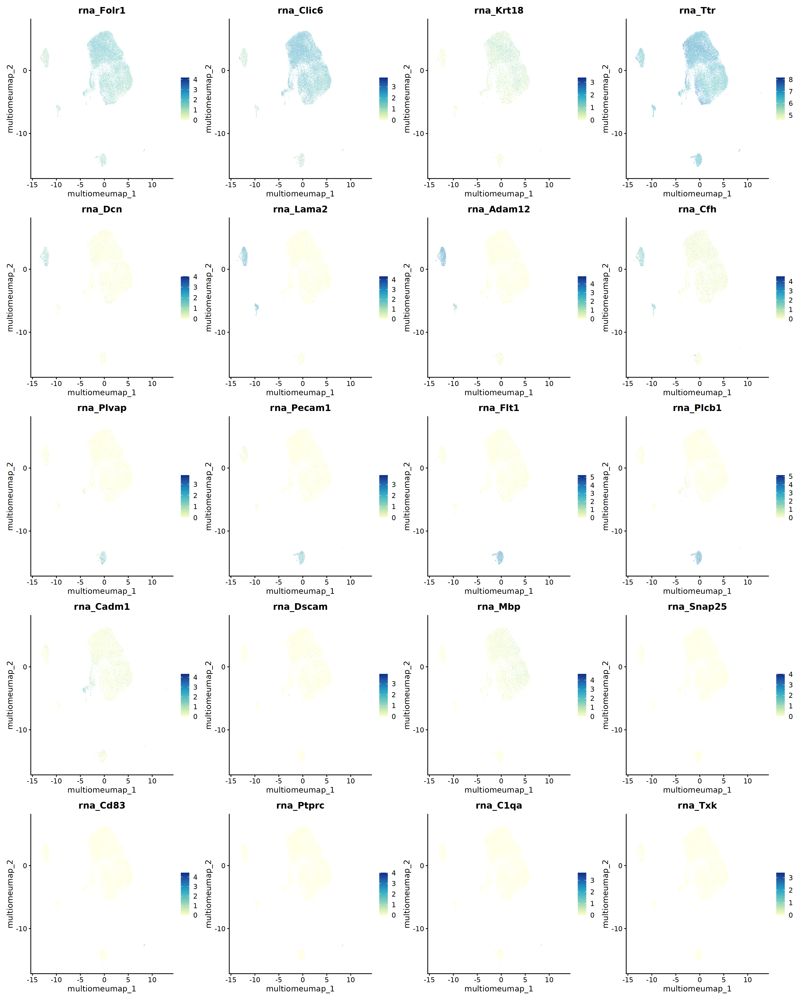

In [ ]:
options(repr.plot.width = 20, repr.plot.height = 25, repr.plot.res = 200)
ftp <- FeaturePlot(integrated, reduction = 'multiome.umap', features = markers, 
             min.cutoff = 0, label.size = 2, ncol = 4, pt.size = 0.5, raster=TRUE) & scale_color_distiller(palette = "YlGnBu", direction = 1)
ftp 


ggsave(file="noDBL_joint_geneExpression.svg", plot=ftp, width=20, height=35)

In [ ]:
integrated <- readRDS('noDBL_merged_peaks_clusters_joint.rds')

# Link peaks to genes

In [ ]:
integrated <- readRDS('noDBL_merged_peaks_clusters_joint.rds')

In [10]:
library(BSgenome.Mmusculus.UCSC.mm10)

Loading required package: BSgenome

Warning message:
“package ‘BSgenome’ was built under R version 4.3.2”
Loading required package: Biostrings

Warning message:
“package ‘Biostrings’ was built under R version 4.3.3”
Loading required package: XVector

Warning message:
“package ‘XVector’ was built under R version 4.3.3”

Attaching package: ‘Biostrings’


The following object is masked from ‘package:base’:

    strsplit


Loading required package: BiocIO

Warning message:
“package ‘BiocIO’ was built under R version 4.3.2”

Attaching package: ‘BiocIO’


The following object is masked from ‘package:rtracklayer’:

    FileForFormat




In [41]:
DefaultAssay(integrated) <- 'peaks'

In [42]:
# first compute the GC content for each peak
integrated <- RegionStats(integrated, genome = BSgenome.Mmusculus.UCSC.mm10)

In [43]:
integrated[['ATAC']] <- NULL

In [44]:
integrated

An object of class Seurat 
215510 features across 37992 samples within 2 assays 
Active assay: peaks (183223 features, 183223 variable features)
 2 layers present: counts, data
 1 other assay present: RNA
 10 dimensional reductions calculated: pca, umap, umapRNA, harmonyRNA, harmony_RNA, lsi, atac.umap, harmonyPeaks, harmony_Peaks, multiome.umap

In [45]:
integrated <- LinkPeaks(integrated, peak.assay = "peaks", expression.assay = "RNA")

Testing 22172 genes and 183188 peaks



In [46]:
integrated

An object of class Seurat 
215510 features across 37992 samples within 2 assays 
Active assay: peaks (183223 features, 183223 variable features)
 2 layers present: counts, data
 1 other assay present: RNA
 10 dimensional reductions calculated: pca, umap, umapRNA, harmonyRNA, harmony_RNA, lsi, atac.umap, harmonyPeaks, harmony_Peaks, multiome.umap

In [ ]:
saveRDS(integrated, 'noDBL_merged_peaks_clusters_joint_linked.rds')

# Peaks for marker genes

In [ ]:
integrated <- readRDS('noDBL_merged_peaks_clusters_joint_linked.rds')

In [110]:
integrated

An object of class Seurat 
215510 features across 37992 samples within 2 assays 
Active assay: peaks (183223 features, 183223 variable features)
 2 layers present: counts, data
 1 other assay present: RNA
 10 dimensional reductions calculated: pca, umap, umapRNA, harmonyRNA, harmony_RNA, lsi, atac.umap, harmonyPeaks, harmony_Peaks, multiome.umap

In [111]:
DefaultAssay(integrated) <- 'peaks'

In [112]:
Annotation(integrated) <- annotation

In [113]:
integrated$splitby <- paste0(integrated$Age, "-", integrated$Cell_type)

In [114]:
markers <- c('Folr1', 'Clic6', 'Krt18', 'Ttr', 
             'Dcn', 'Lama2', 'Adam12', 'Cfh', 
             'Plvap', 'Pecam1', 'Flt1', 'Plcb1', 
             'Cadm1', 'Dscam', 'Mbp','Snap25',
             'Cd83', 'Ptprc', 'C1qa', 'Txk')

In [115]:
epi <- c('Folr1', 'Clic6', 'Krt18', 'Ttr')

In [116]:
options(repr.plot.width = 15, repr.plot.height = 5, repr.plot.res = 200)

Warning message:
“Removed 66 rows containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 66 rows containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_segment()`).”


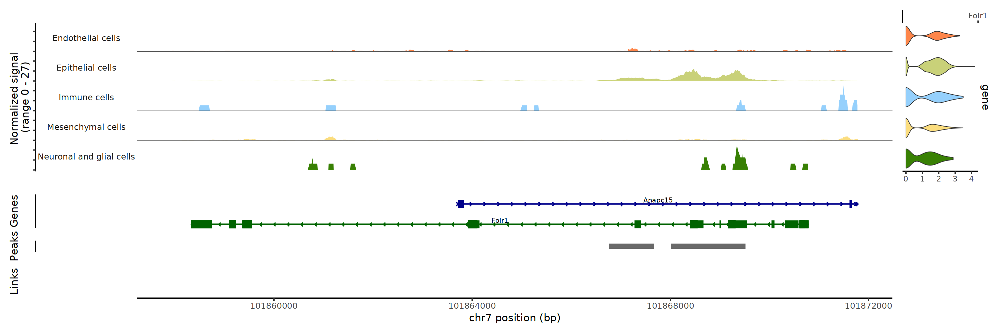

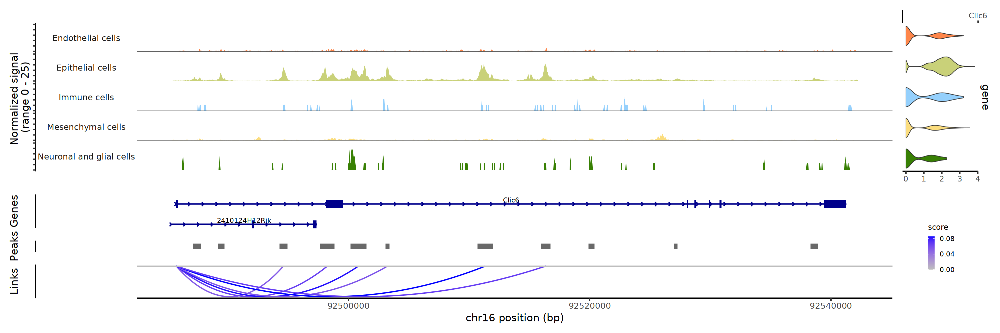

Warning message:
“Removed 3 rows containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 3 rows containing missing values or values outside the scale range (`geom_segment()`).”


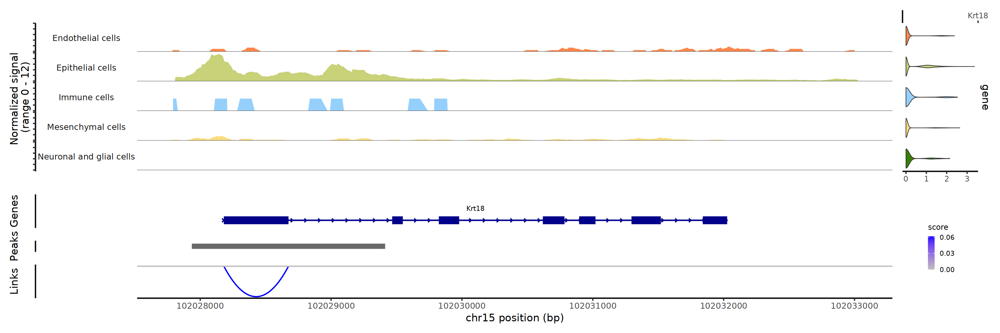

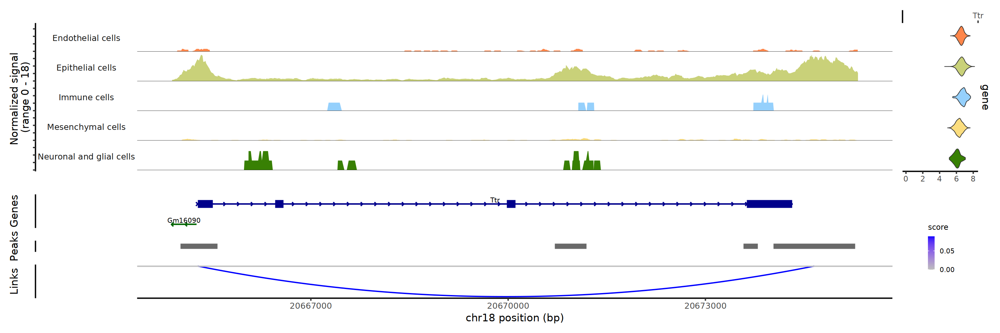

In [ ]:
for (gene in epi){
    cvp <- CoveragePlot(integrated, region = gene, features = gene, group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 1000, 
                        extend.downstream = 1000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("noDBL_", gene, "_igv_tracks_epi.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)
    
}

In [122]:
mesen <- c('Dcn', 'Lama2', 'Adam12', 'Cfh')

Warning message:
“Removed 2 rows containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range (`geom_segment()`).”


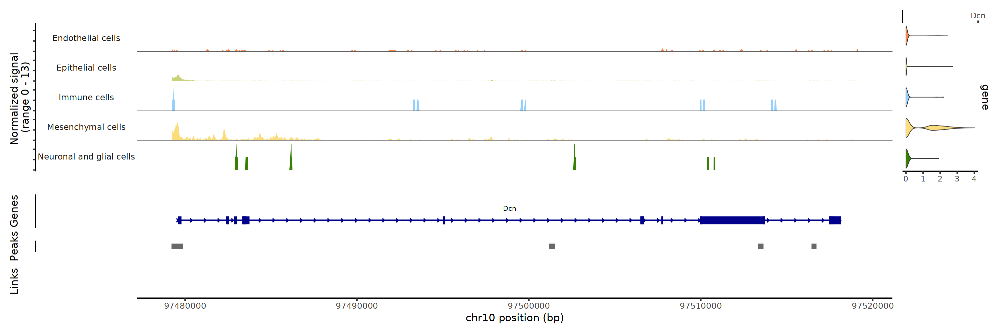

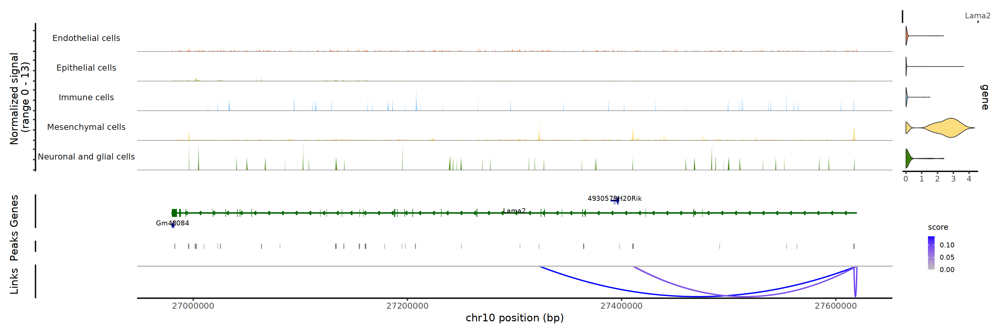

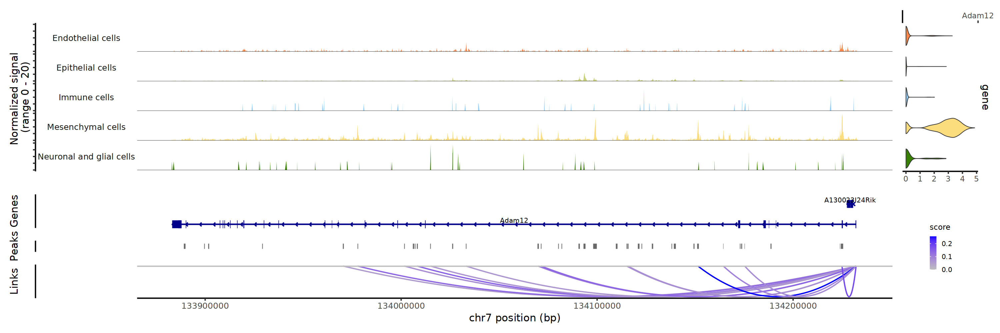

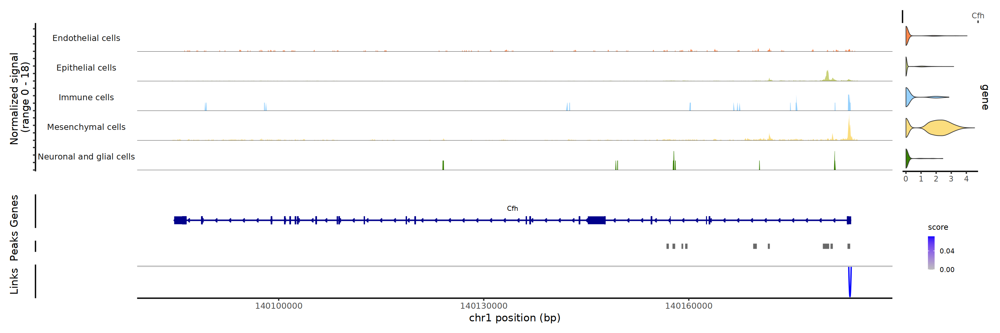

In [ ]:
for (gene in mesen){
    cvp <- CoveragePlot(integrated, region = gene, features = gene, group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 1000, 
                        extend.downstream = 1000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("noDBL_", gene, "_igv_tracks_mesen.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)
    
}

In [125]:
endo <- c('Plvap', 'Pecam1', 'Flt1', 'Plcb1')

Warning message:
“Removed 56 rows containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 56 rows containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 51 rows containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 51 rows containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_segment()`).”


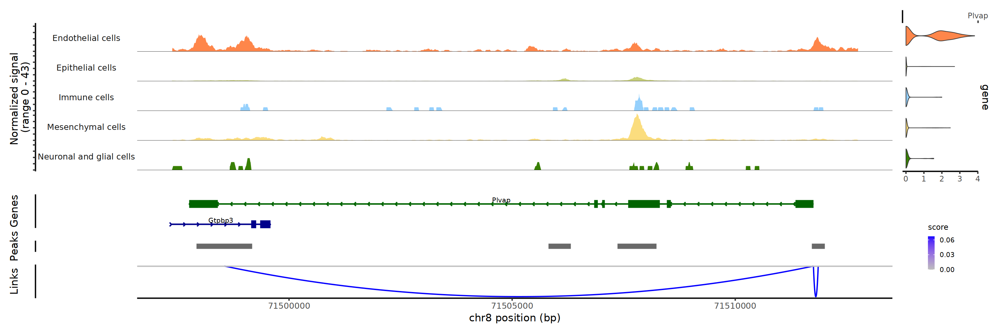

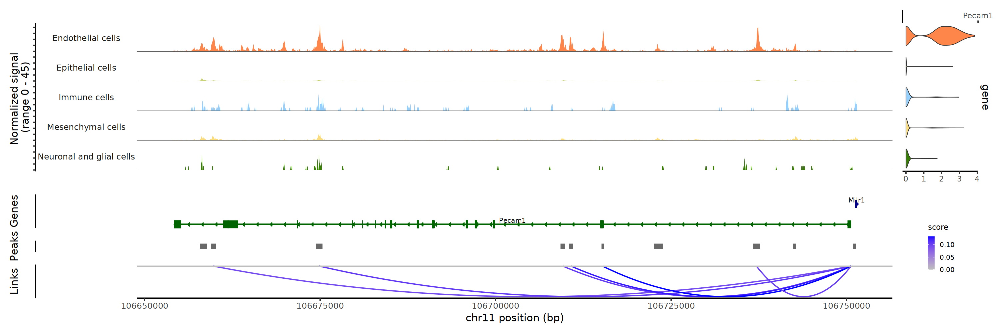

Warning message:
“Removed 3 rows containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 3 rows containing missing values or values outside the scale range (`geom_segment()`).”


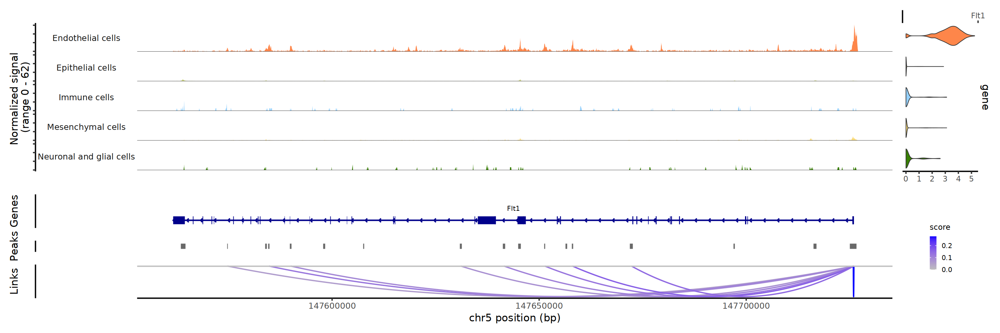

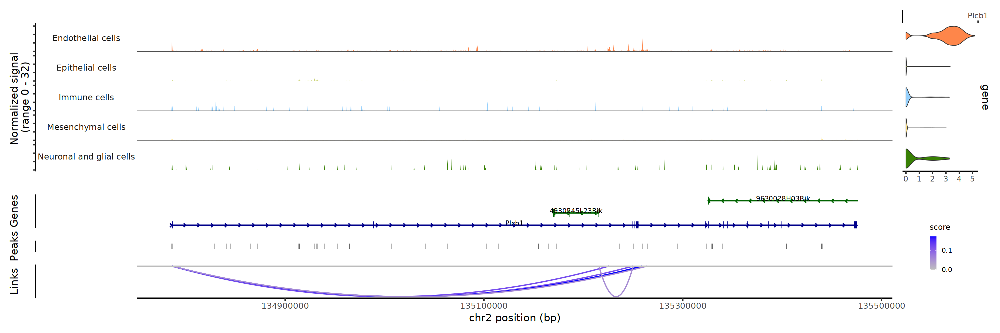

In [ ]:
for (gene in endo){
    cvp <- CoveragePlot(integrated, region = gene, features = gene, group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 1000, 
                        extend.downstream = 1000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("noDBL_", gene, "_igv_tracks_endo.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)
    
}

In [127]:
neugli <- c('Cadm1', 'Dscam', 'Mbp','Snap25')

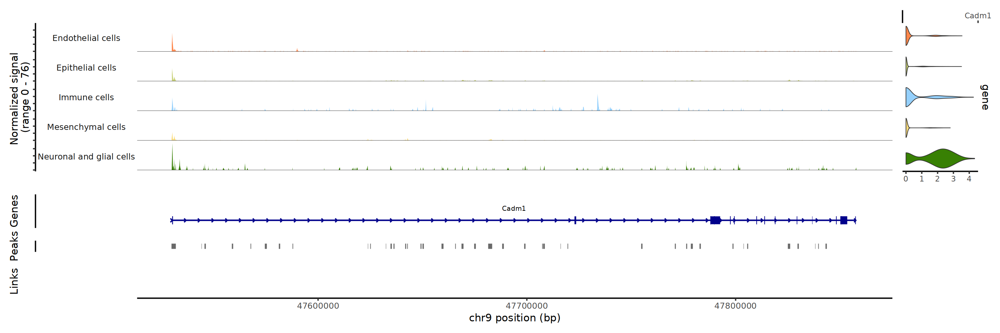

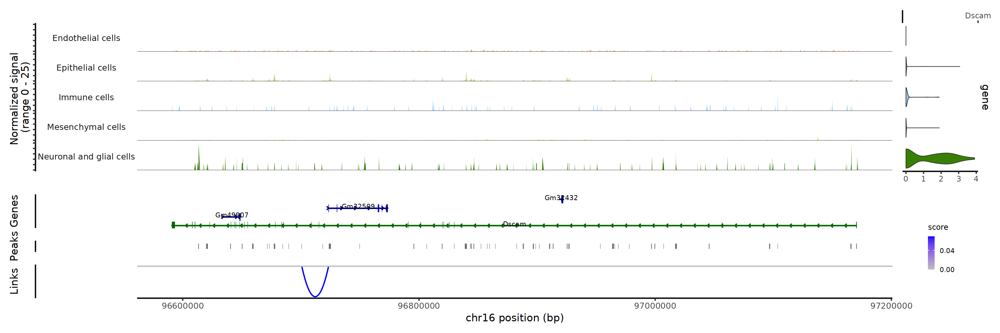

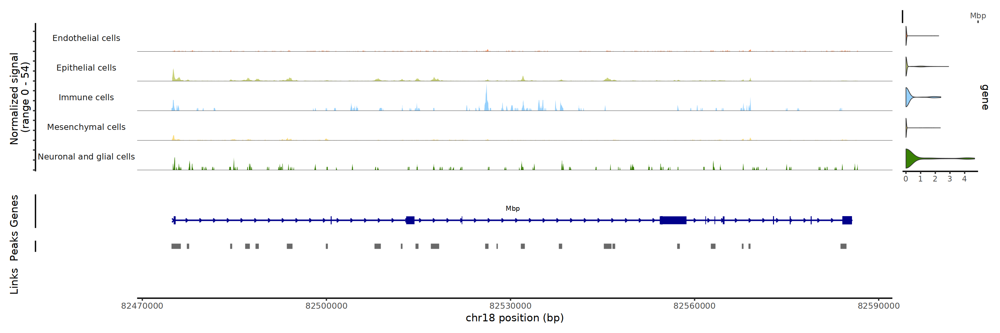

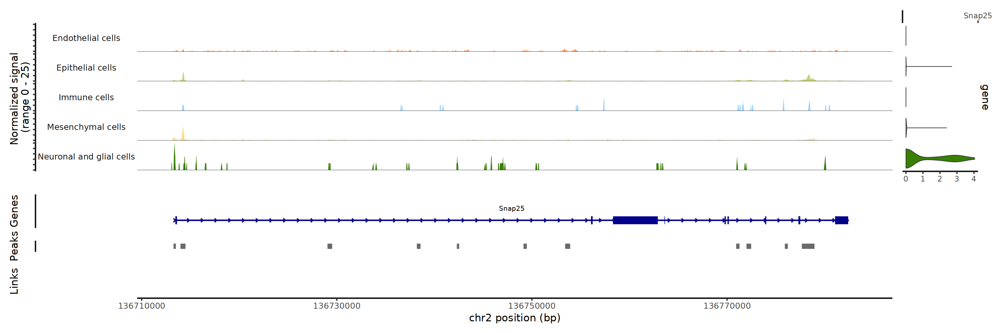

In [ ]:
for (gene in neugli){
    cvp <- CoveragePlot(integrated, region = gene, features = gene, group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 1000, 
                        extend.downstream = 1000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("noDBL_", gene, "_igv_tracks_neugli.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)
    
}

In [129]:
immune <- c('Cd83', 'Ptprc', 'C1qa', 'Cd86', 'Cd74')

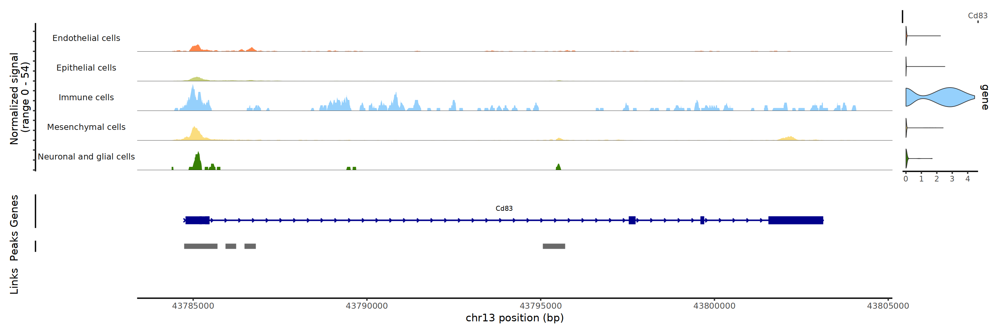

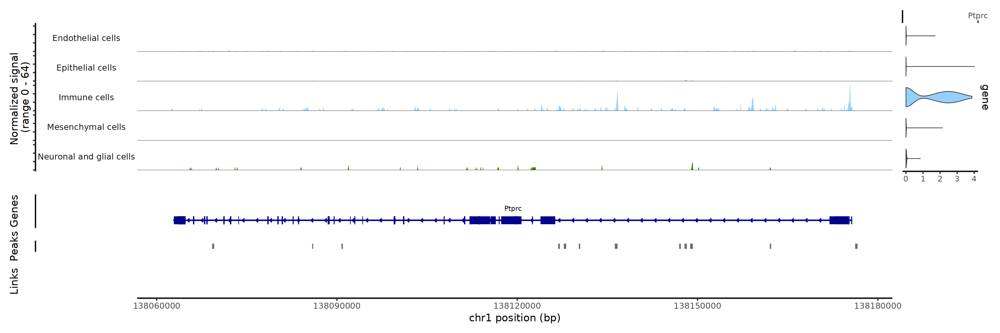

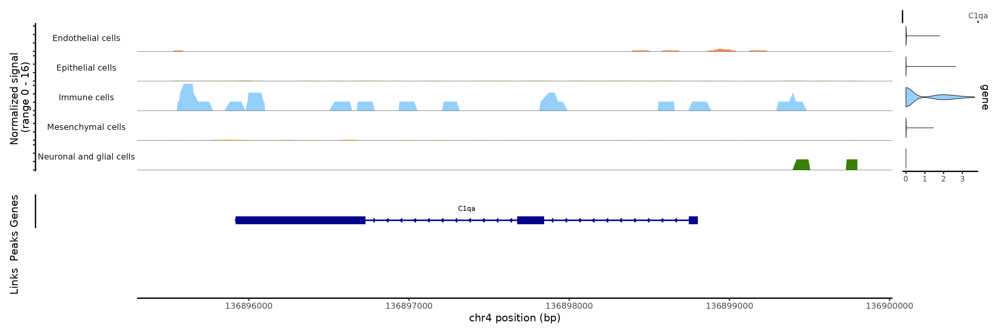

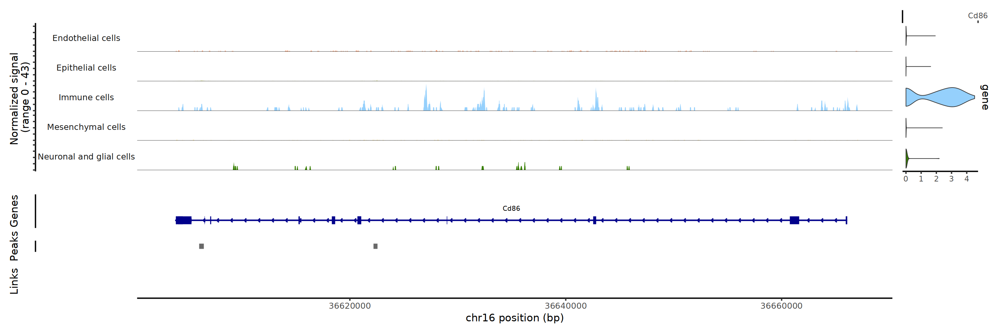

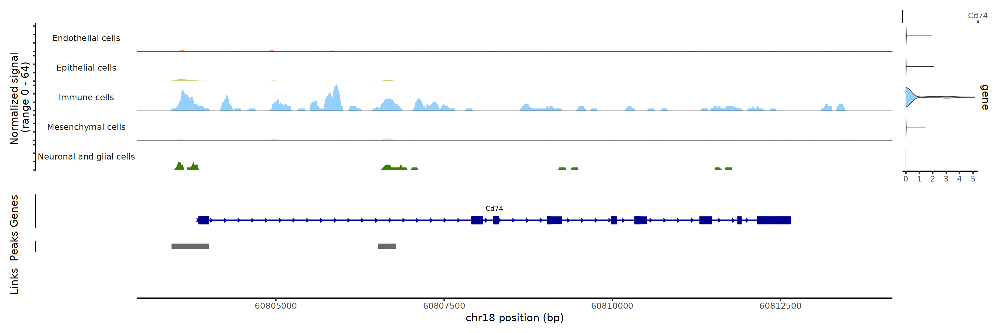

In [ ]:
for (gene in immune){
    cvp <- CoveragePlot(integrated, region = gene, features = gene, group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 1000, 
                        extend.downstream = 1000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("noDBL_", gene, "_igv_tracks_immune.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)
    
}

# Call peaks on clusters

In [ ]:
integrated <- readRDS('noDBL_merged_peaks_clusters_joint_linked.rds')

In [16]:
integrated

An object of class Seurat 
215510 features across 37992 samples within 2 assays 
Active assay: peaks (183223 features, 183223 variable features)
 2 layers present: counts, data
 1 other assay present: RNA
 10 dimensional reductions calculated: pca, umap, umapRNA, harmonyRNA, harmony_RNA, lsi, atac.umap, harmonyPeaks, harmony_Peaks, multiome.umap

In [33]:
DefaultAssay(integrated) <- 'peaks'

In [42]:
# call peaks using MACS2
peaks <- CallPeaks(object=integrated, group.by='Cell_type', 
                outdir='callpeaks_noDBL_ct', cleanup=FALSE)

Processing file /projects/F202408336CPCAA0/Analysis/Mouse/Last_multiome/Last_multiome_data/raw_data/P11_01_n00388/atac_fragments.tsv.gz




Processing file /projects/F202408336CPCAA0/Analysis/Mouse/Last_multiome/Last_multiome_data/raw_data/P11_02_n00388/atac_fragments.tsv.gz




Processing file /projects/F202408336CPCAA0/Analysis/Mouse/Last_multiome/Last_multiome_data/raw_data/P11_03_n00388/atac_fragments.tsv.gz




Processing file /projects/F202408336CPCAA0/Analysis/Mouse/Last_multiome/Last_multiome_data/raw_data/P60_05_n00388/atac_fragments.tsv.gz




Processing file /projects/F202408336CPCAA0/Analysis/Mouse/Last_multiome/Last_multiome_data/raw_data/P60_06_d05797/atac_fragments.tsv.gz




Processing file /projects/F202408336CPCAA0/Analysis/Mouse/Last_multiome/Last_multiome_data/raw_data/P60_TTR_07_06_n00388/atac_fragments.tsv.gz






In [45]:
peaks_df <- as.data.frame(peaks)

In [46]:
head(peaks_df)

,seqnames,start,end,width,strand,peak_called_in
,<fct>,<int>,<int>,<int>,<fct>,<chr>
1,chr1,3007101,3007821,721,*,Epithelial_cells
2,chr1,3119877,3120159,283,*,Mesenchymal_cells
3,chr1,3121283,3121572,290,*,Mesenchymal_cells
4,chr1,3319036,3319289,254,*,Epithelial_cells
5,chr1,3360842,3361246,405,*,"Mesenchymal_cells,Epithelial_cells"
6,chr1,3399550,3400508,959,*,Epithelial_cells


In [47]:
write.csv(peaks_df, file = "peaks.csv", row.names = FALSE)

In [48]:
write.table(peaks_df, file = "peaks.tsv", sep = "\t", row.names = FALSE, quote = FALSE)

# Find DA peaks 

In [ ]:
integrated <- readRDS('noDBL_merged_peaks_clusters_joint_linked.rds')

## Load HOMER annotation

In [ ]:
homer_anno <- read.delim('hommer_anno_all.txt')

In [11]:
homer_anno$Peaks <- paste0(homer_anno$Chr, '-', homer_anno$Start, "-", homer_anno$End)

In [12]:
homer_anno$Annotation <- sapply(strsplit(homer_anno$Annotation, " "), `[`, 1)

**The cell below creats the function to find the overlaps between da peaks and the ones annotated using homer and then plots them on a donut plot**

In [13]:
library(GenomicRanges)
library(ggplot2)

create_peak_overlap_plot <- function(df_peaks, homer_anno, my_c, plot_name) {
  
  # Create GRanges objects
  marker_gr <- GRanges(seqnames = sub("-.*", "", df_peaks$gene),
                       ranges = IRanges(start = as.integer(sub(".*-(\\d+)-.*", "\\1", df_peaks$gene)),
                                        end = as.integer(sub(".*-", "", df_peaks$gene))))
  
  peak_gr <- GRanges(seqnames = sub("-.*", "", homer_anno$Peaks),
                     ranges = IRanges(start = as.integer(sub(".*-(\\d+)-.*", "\\1", homer_anno$Peaks)),
                                      end = as.integer(sub(".*-", "", homer_anno$Peaks))))
  
  # Find overlaps
  overlaps <- findOverlaps(marker_gr, peak_gr)
  epi_valid_markers <- homer_anno[queryHits(overlaps), ]
  
  # Get peaks info
  peaks_info <- table(unlist(epi_valid_markers$Annotation))
  df_info <- data.frame(peaks_info)
  colnames(df_info) <- c('Type', 'Frequency')
  
  # Compute percentages and cumulative sums
  df_info$fraction <- df_info$Frequency / sum(df_info$Frequency)
  df_info$ymax <- cumsum(df_info$fraction)
  df_info$ymin <- c(0, head(df_info$ymax, n=-1))
  df_info$labelPosition <- (df_info$ymax + df_info$ymin) / 2
  df_info$label <- paste0(df_info$Type, "\n", df_info$Frequency)
  
  # Create the plot
  p <- ggplot(df_info, aes(ymax=ymax, ymin=ymin, xmax=3, xmin=2, fill=Type)) +
    geom_rect() +
    scale_fill_manual(values=my_c[9:24]) +
    geom_text(x=3.8, aes(y=labelPosition, label=label, color=Type), size=6, angle=45) +
    scale_colour_manual(values=my_c[9:24]) +
    coord_polar(theta="y") +
    xlim(c(-1, 4)) +
    theme_void() +
    theme(legend.position = "right")

  ggsave(file=plot_name, plot=p)
  
  return(p)
}


## Cell types

In [15]:
da_peaks <- FindAllMarkers(
  object = integrated,
  test.use = 'LR',
  min.pct = 0.1)

Calculating cluster Epithelial cells

Calculating cluster Mesenchymal cells

Calculating cluster Endothelial cells

Calculating cluster Neuronal and glial cells

Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 o

In [ ]:
da_peaks <- da_peaks[da_peaks$p_val < 0.05, ]

In [ ]:
write.csv(da_peaks, 'DA_peaks_all.csv')

In [ ]:
da_peaks <- read.csv('DA_peaks_all.csv', row.names = 1)

In [15]:
head(da_peaks)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
chrM-9436-9758,0,1.235342,0.618,0.267,0,Epithelial cells,chrM-9436-9758
chr13-9011599-9012218,0,-1.761347,0.151,0.392,0,Epithelial cells,chr13-9011599-9012218
chr2-25467284-25470228,0,3.691733,0.242,0.016,0,Epithelial cells,chr2-25467284-25470228
chr7-70623860-70626580,0,2.842931,0.256,0.032,0,Epithelial cells,chr7-70623860-70626580
chr8-125909425-125911430,0,3.732516,0.234,0.015,0,Epithelial cells,chr8-125909425-125911430
chr19-45578949-45580752,0,4.328495,0.225,0.009,0,Epithelial cells,chr19-45578949-45580752


### Epithelial cells

In [16]:
epi_peaks <- subset(da_peaks, cluster == 'Epithelial cells')

In [17]:
dim(epi_peaks)

[1] 7111    7

In [31]:
options(repr.plot.width = 20, repr.plot.height = 10, repr.plot.res = 300)

Saving 6.67 x 6.67 in image


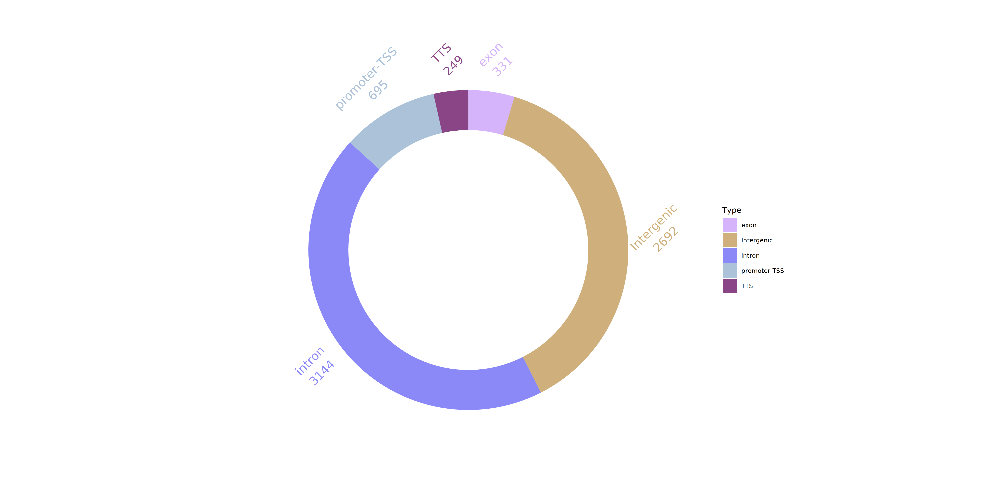

In [ ]:
plot <- create_peak_overlap_plot(epi_peaks, homer_anno, my_c, plot_name='Donut_epi.svg')

plot

### Endothelial cells

In [33]:
integrated_Peaks <- subset(da_peaks, cluster == 'Endothelial cells')

In [34]:
dim(integrated_Peaks)

[1] 5523    7

#### Donut plots por types of peaks

Saving 6.67 x 6.67 in image


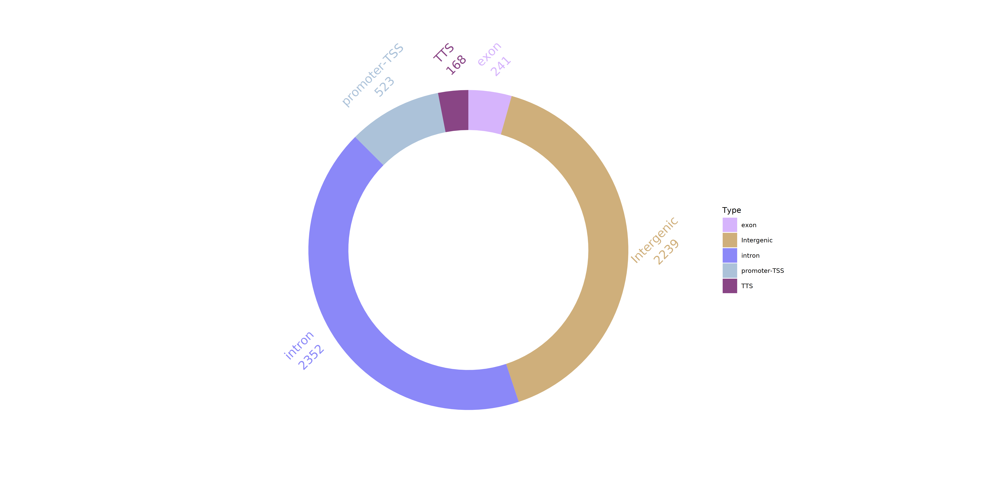

In [ ]:
plot <- create_peak_overlap_plot(integrated_Peaks, homer_anno, my_c, plot_name='Donut_endo.svg')

plot

### Mesenchymal cells

In [36]:
mesen_peaks <- subset(da_peaks, cluster == 'Mesenchymal cells')

In [37]:
dim(mesen_peaks)

[1] 7506    7

In [38]:
dim(mesen_peaks)

[1] 7506    7

#### Donut plots por types of peaks

Saving 6.67 x 6.67 in image


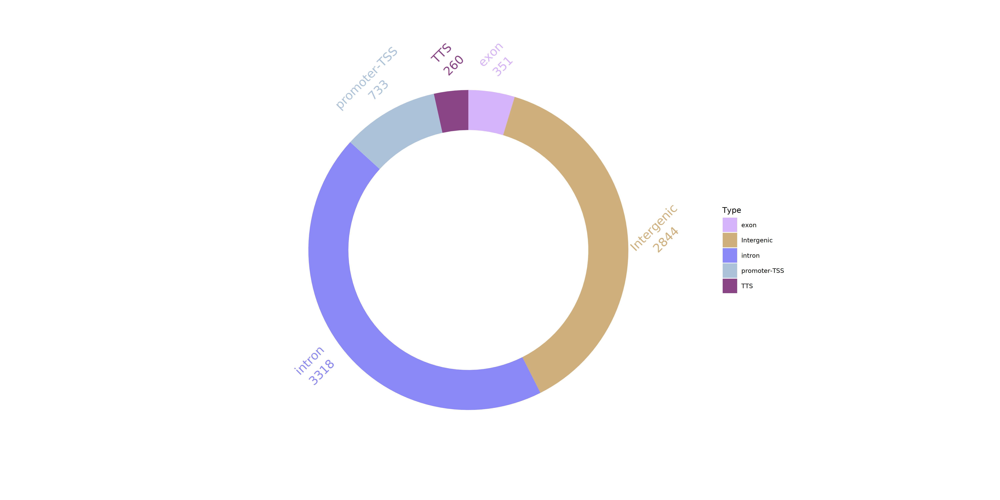

In [ ]:
plot <- create_peak_overlap_plot(mesen_peaks, homer_anno, my_c, plot_name='Donut_mesen.svg')

plot

### Immune cells

In [40]:
immune_peaks <- subset(da_peaks, cluster == 'Immune cells')

In [41]:
dim(immune_peaks)

[1] 3119    7

In [42]:
dim(immune_peaks)

[1] 3119    7

#### Donut plots por types of peaks

Saving 6.67 x 6.67 in image


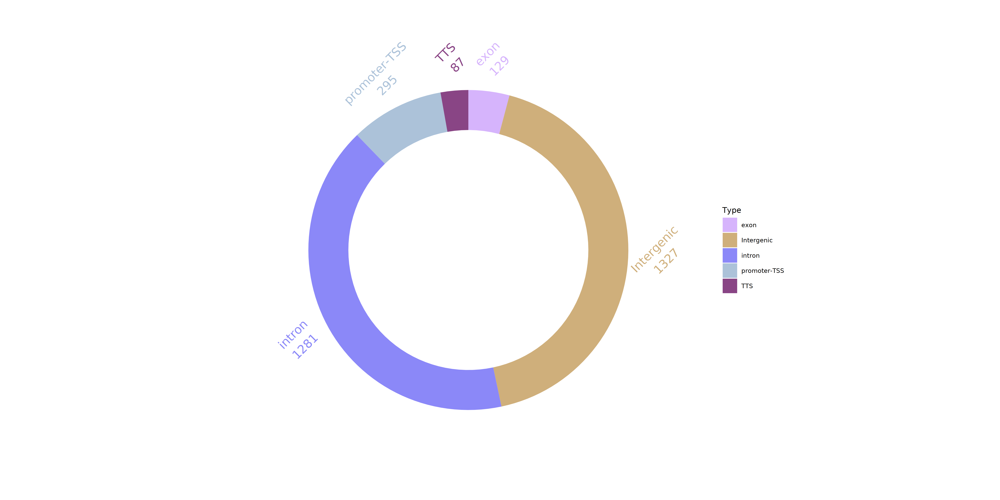

In [ ]:
plot <- create_peak_overlap_plot(immune_peaks, homer_anno, my_c, plot_name='Donut_immune.svg')

plot

### Neuronal and Glial cells

In [44]:
neugli_peaks <- subset(da_peaks, cluster == 'Neuronal and glial cells')

In [45]:
dim(neugli_peaks)

[1] 1125    7

In [46]:
dim(neugli_peaks)

[1] 1125    7

#### Donut plots por types of peaks

Saving 6.67 x 6.67 in image


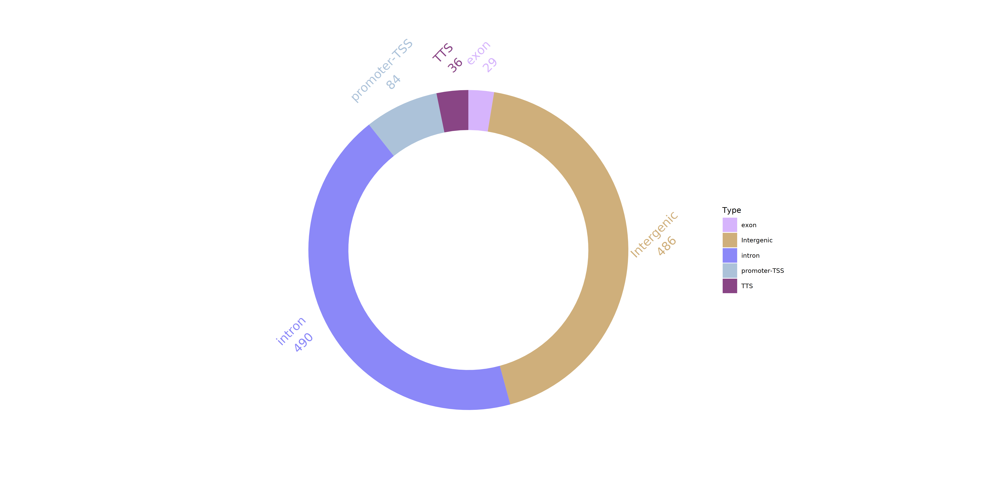

In [ ]:
plot <- create_peak_overlap_plot(neugli_peaks, homer_anno, my_c, plot_name='Donut_neugli.svg')

plot

## Condition

In [22]:
Idents(integrated) <- "Age"

In [23]:
da_peaks_age <- FindAllMarkers(
  object = integrated,
  assay = 'peaks',
  test.use = 'wilcox',
  min.pct = 0.01
)

Calculating cluster P11

Calculating cluster P60



In [24]:
dim(da_peaks_age)

[1] 162764      7

In [25]:
da_peaks_age <- da_peaks_age[da_peaks_age$p_val < 0.05, ]

In [ ]:
write.csv(da_peaks_age, 'DA_peaks_all_age.csv')

In [27]:
dim(da_peaks_age)

[1] 162764      7

In [28]:
p11_peaks <- subset(da_peaks_age, cluster == 'P11')

In [29]:
dim(p11_peaks)

[1] 81382     7

In [30]:
p60_peaks <- subset(da_peaks_age, cluster == 'P60')

In [31]:
dim(p60_peaks)

[1] 81382     7

# Plots for figures

In [86]:
integrated$log10_ngenes <- log10(integrated$nFeature_RNA)

In [10]:
Idents(integrated) <- "Cell_type"

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


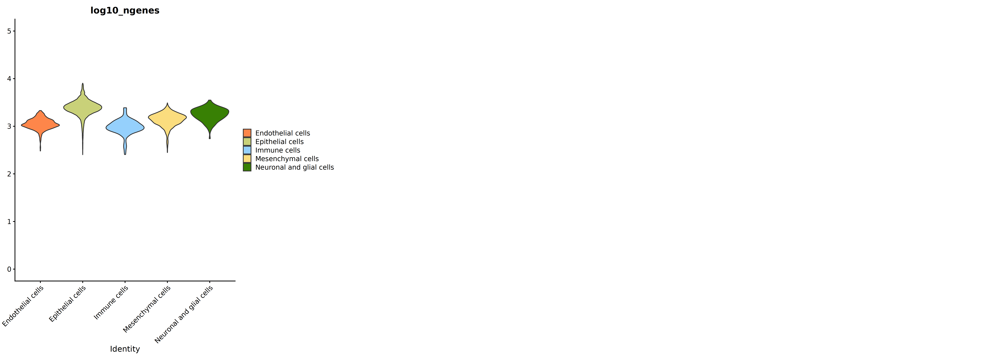

In [ ]:
options(repr.plot.width = 25, repr.plot.height = 9, repr.plot.res = 300)

vln <- VlnPlot(integrated, features=c('log10_ngenes'), group.by = 'Cell_type',
        ncol=4, pt.size=0, col = my_c)  + scale_y_continuous(limits = c(0,5))

vln

ggsave(file="noDBL_noDBL_integrated_all_vln_log10genes_Cell_Types.svg", plot=vln, width=25, height=9)


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Warning message:
“Removed 521 rows containing non-finite outside the scale range (`stat_ydensity()`).”
Warning message:
“Removed 521 rows containing non-finite outside the scale range (`stat_ydensity()`).”


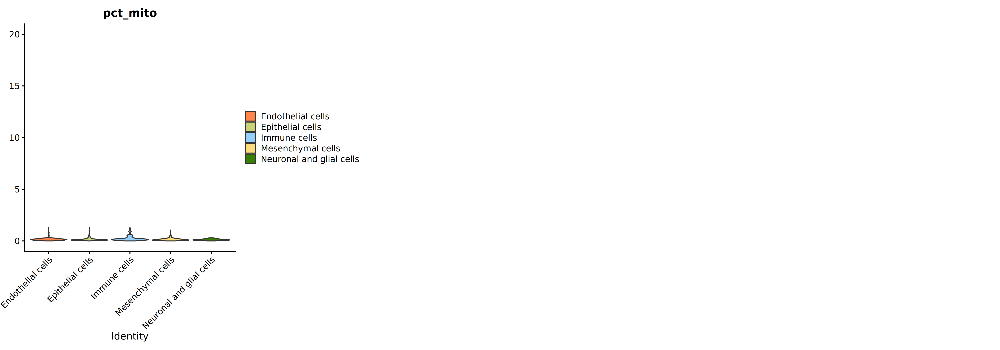

In [ ]:
options(repr.plot.width = 20, repr.plot.height = 7, repr.plot.res = 300)

vln <- VlnPlot(integrated, features=c('pct_mito'), group.by = 'Cell_type',
        ncol=4, pt.size=0, col = my_c) + scale_y_continuous(limits = c(0,20))

vln

ggsave(file="noDBL_noDBL_integrated_all_vln_pctmito_Cell_Types.svg", plot=vln, width=20, height=7)


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


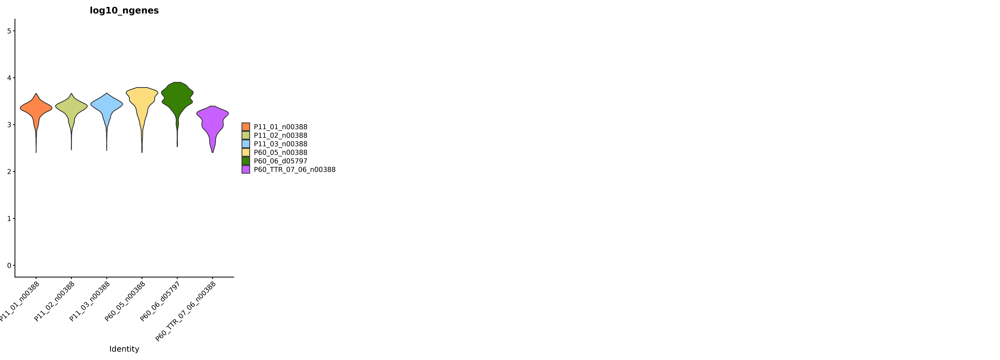

In [ ]:
options(repr.plot.width = 25, repr.plot.height = 9, repr.plot.res = 300)

vln <- VlnPlot(integrated, features=c('log10_ngenes'), group.by = 'Sample',
        ncol=4, pt.size=0, col = my_c)  + scale_y_continuous(limits = c(0,5))

vln

ggsave(file="noDBL_noDBL_integrated_all_vln_log10genes_Sample.svg", plot=vln, width=25, height=9)


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Warning message:
“Removed 521 rows containing non-finite outside the scale range (`stat_ydensity()`).”
Warning message:
“Removed 521 rows containing non-finite outside the scale range (`stat_ydensity()`).”


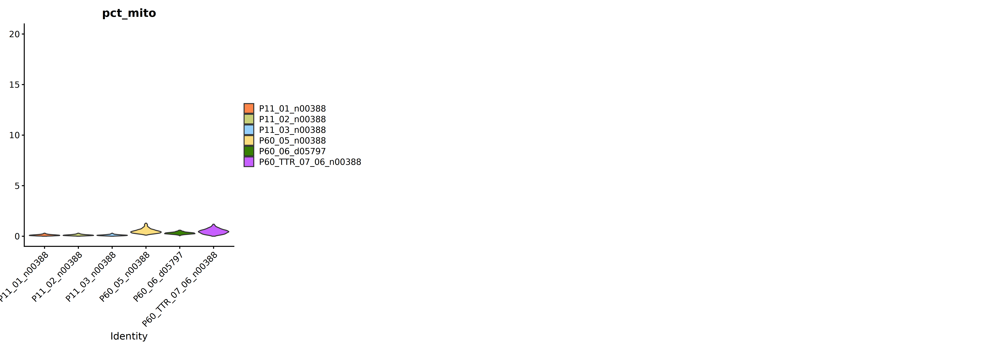

In [ ]:
options(repr.plot.width = 20, repr.plot.height = 7, repr.plot.res = 300)

vln <- VlnPlot(integrated, features=c('pct_mito'), group.by = 'Sample',
        ncol=4, pt.size=0, col = my_c) + scale_y_continuous(limits = c(0,20))

vln

ggsave(file="noDBL_noDBL_integrated_all_vln_pctmito_Sample.svg", plot=vln, width=20, height=7)


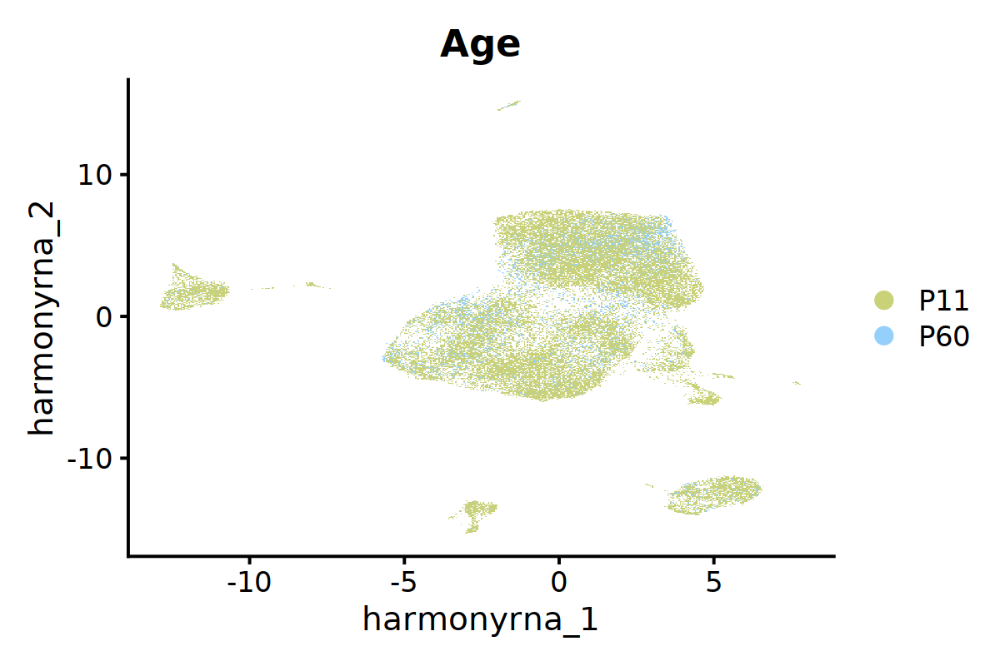

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
dmp <- DimPlot(object = integrated, label = FALSE,group.by='Age', cols = my_c[2:3], 
               reduction = 'harmony_RNA', raster = TRUE, pt.size = 1)

dmp

ggsave(file="noDBL_Harmony_noDBL_Age_RNA_umap.svg", plot=dmp, width=6, height=4)

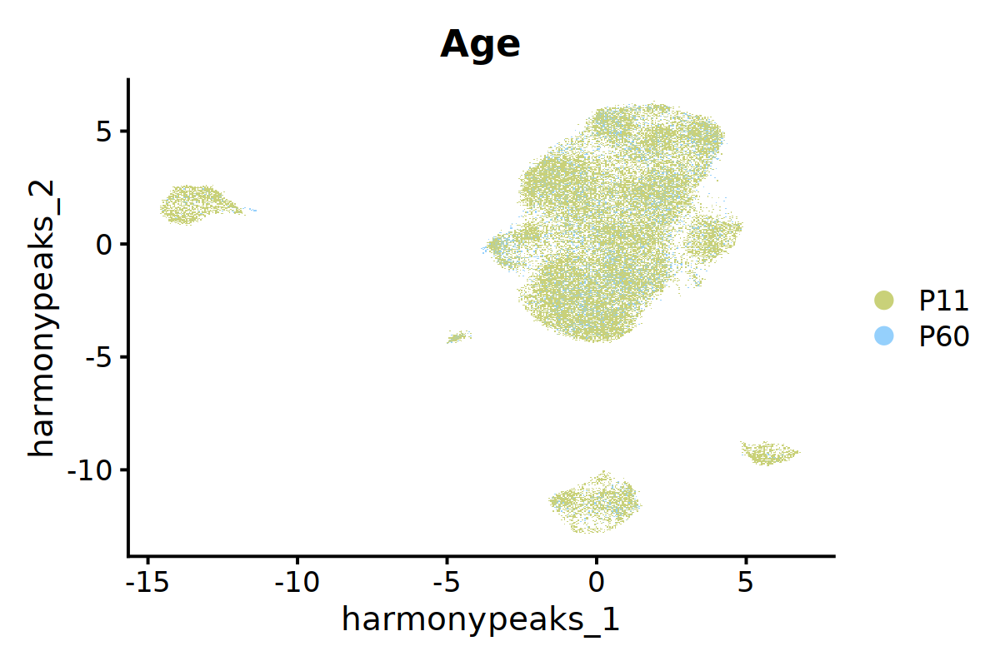

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
dmp <- DimPlot(object = integrated, label = FALSE,group.by='Age', cols = my_c[2:3], 
               reduction = 'harmony_Peaks', raster = TRUE, pt.size = 1)

dmp

ggsave(file="noDBL_Harmony_noDBL_Age_peaks_umap.svg", plot=dmp, width=6, height=4)

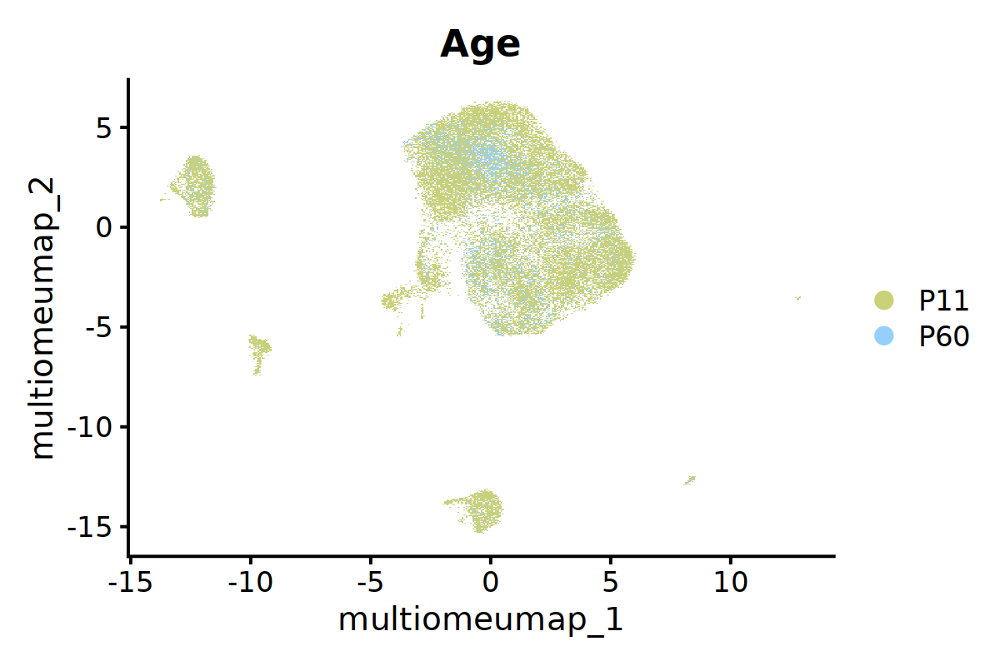

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
dmp <- DimPlot(object = integrated, label = FALSE,group.by='Age', cols = my_c[2:3], 
               reduction = 'multiome.umap', raster = TRUE, pt.size = 1)

dmp

ggsave(file="noDBL_Harmony_noDBL_Age_joint_umap.svg", plot=dmp, width=6, height=4)

In [77]:
DefaultAssay(integrated) <- 'RNA'

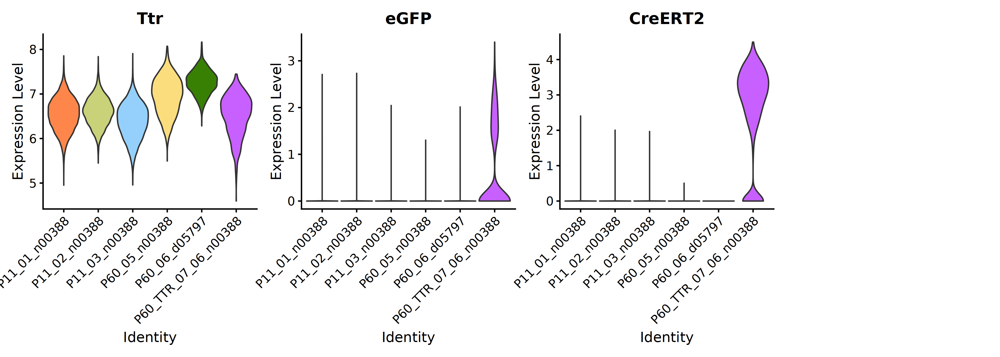

In [ ]:
options(repr.plot.width = 14, repr.plot.height = 5, repr.plot.res = 300)

vln <- VlnPlot(integrated, features=c('Ttr', 'eGFP', 'CreERT2'), group.by = 'Sample',
        ncol=4, pt.size=0, col = my_c) 

vln

ggsave(file="noDBL_vln_TTR_eGFP_CreERT2_all_samples.svg", plot=vln, width=14, height=5)

In [ ]:
TTR_mouse <- subset(integrated, subset = Sample == 'P60_TTR_sample3')

In [52]:
TTR_mouse

An object of class Seurat 
215510 features across 1107 samples within 2 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: peaks
 10 dimensional reductions calculated: pca, umap, umapRNA, harmonyRNA, harmony_RNA, lsi, atac.umap, harmonyPeaks, harmony_Peaks, multiome.umap

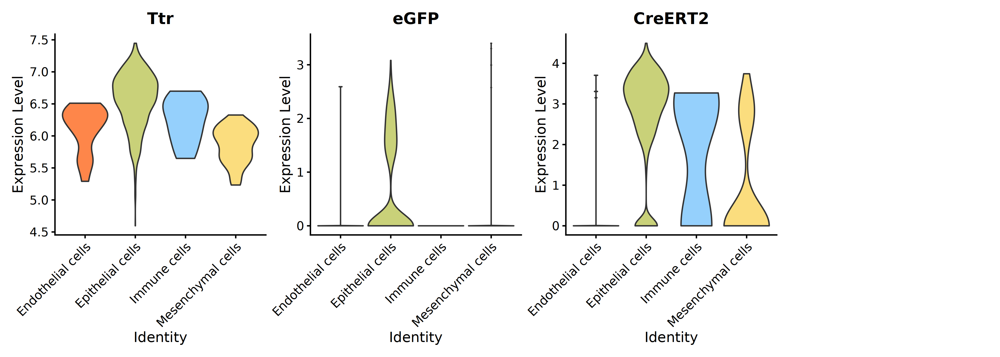

In [ ]:
options(repr.plot.width = 14, repr.plot.height = 5, repr.plot.res = 300)

vln <- VlnPlot(TTR_mouse, features=c('Ttr', 'eGFP', 'CreERT2'), group.by = c('Cell_type'),
        ncol=4, pt.size=0, col = my_c) 

vln
ggsave(file="noDBL_vln_TTR_eGFP_CreERT2_TTR_mouse.svg", plot=vln, width=14, height=5)

## IGV tracks

In [ ]:
integrated <- readRDS('noDBL_merged_peaks_clusters_joint_linked_motif.rds')

In [31]:
integrated

An object of class Seurat 
216256 features across 37992 samples within 3 assays 
Active assay: chromvar (746 features, 0 variable features)
 1 layer present: data
 2 other assays present: RNA, peaks
 10 dimensional reductions calculated: pca, umap, umapRNA, harmonyRNA, harmony_RNA, lsi, atac.umap, harmonyPeaks, harmony_Peaks, multiome.umap

In [32]:
DefaultAssay(integrated) <- 'peaks'

In [33]:
Annotation(integrated) <- annotation

In [23]:
options(repr.plot.width = 15, repr.plot.height = 10, repr.plot.res = 200)

#### Ttr

In [18]:
regions <- c('chr18-20674033-20675277', 'chr18-20662176-20663114')

Warning message:
“Removed 2 rows containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range (`geom_segment()`).”


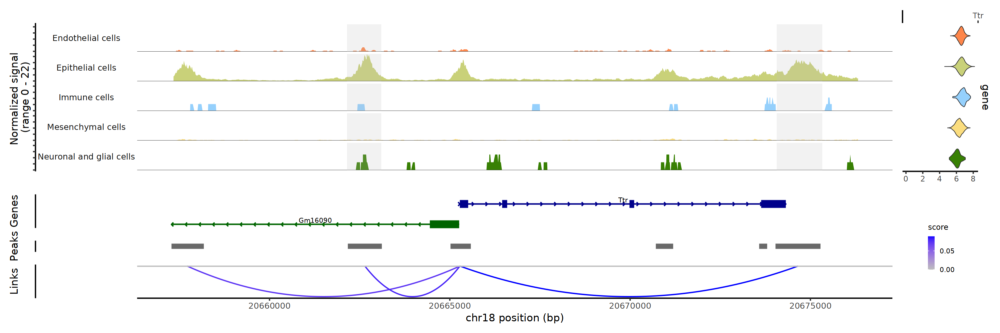

In [ ]:
ranges.show <- StringToGRanges(regions)

cvp <- CoveragePlot(integrated, region = 'Ttr', feature = 'Ttr', region.highlight = ranges.show, group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 8000, 
                        extend.downstream = 2000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("highlight_noDBL_", 'Ttr', "_igv_tracks.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

Warning message:
“Removed 2 rows containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range (`geom_segment()`).”


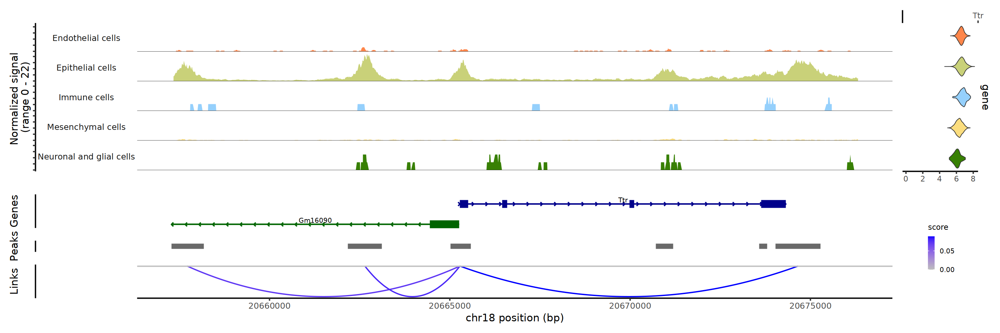

In [ ]:
ranges.show <- StringToGRanges(regions)

cvp <- CoveragePlot(integrated, region = 'Ttr', feature = 'Ttr', group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 8000, 
                        extend.downstream = 2000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("no_highlight_noDBL_", 'Ttr', "_igv_tracks.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

#### Pcam1

In [30]:
regions <- c('chr11-106674418-106675320')

Warning message:
“Removed 44 rows containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 44 rows containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_segment()`).”


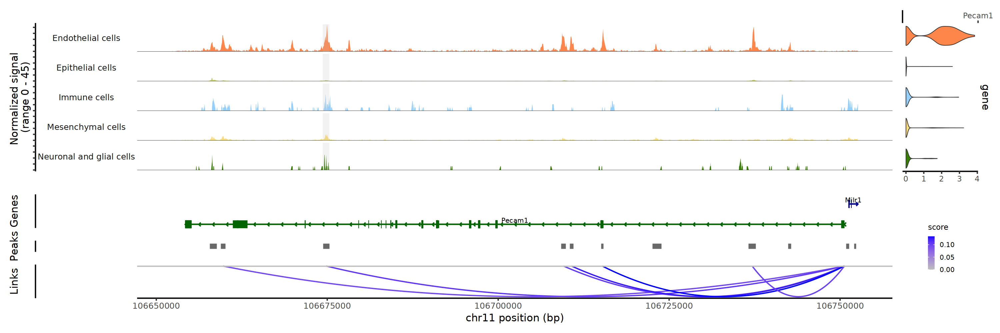

In [ ]:
ranges.show <- StringToGRanges(regions)

cvp <- CoveragePlot(integrated,
                        region = 'Pecam1', features = 'Pecam1', region.highlight = ranges.show, group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 2000, 
                        extend.downstream = 2000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("highlight_noDBL_", 'Pcam1', "_igv_tracks.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

Warning message:
“Removed 44 rows containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 44 rows containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_segment()`).”


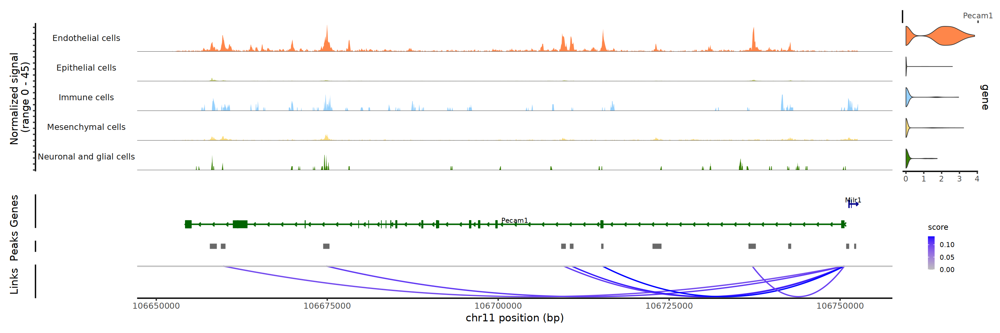

In [ ]:
cvp <- CoveragePlot(integrated,
                        region = 'Pecam1', features = 'Pecam1', group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 2000, 
                        extend.downstream = 2000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("no_highlight_noDBL_", 'Pcam1', "_igv_tracks.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

#### Clic6

In [35]:
regions <- c('chr16-92510704-92511998', 'chr16-92500163-92501512')

Warning message:
“Removed 2 rows containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range (`geom_segment()`).”


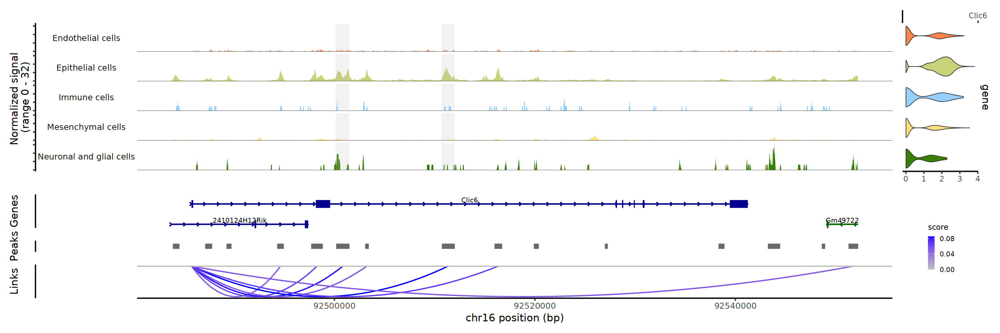

In [ ]:
ranges.show <- StringToGRanges(regions)

cvp <- CoveragePlot(integrated,
                        region = 'Clic6', features = 'Clic6', region.highlight = ranges.show, group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 2000, 
                        extend.downstream = 11000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("highlight_noDBL_", 'Clic6', "_igv_tracks.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

Warning message:
“Removed 2 rows containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range (`geom_segment()`).”


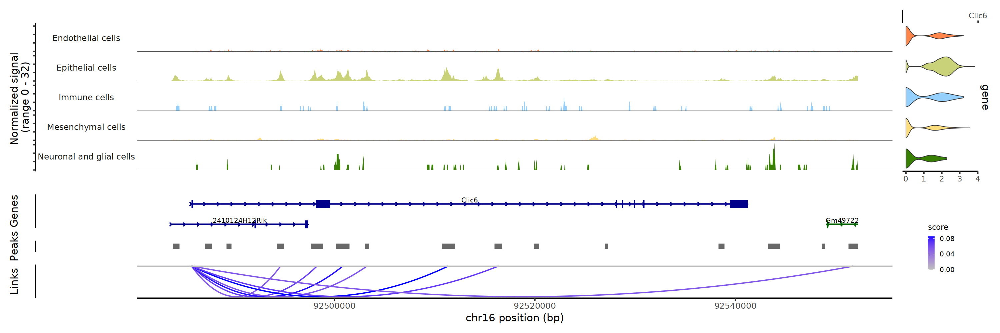

In [ ]:


cvp <- CoveragePlot(integrated,
                        region = 'Clic6', features = 'Clic6', group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 2000, 
                        extend.downstream = 11000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("no_highlight_noDBL_", 'Clic6', "_igv_tracks.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

#### Ptprc

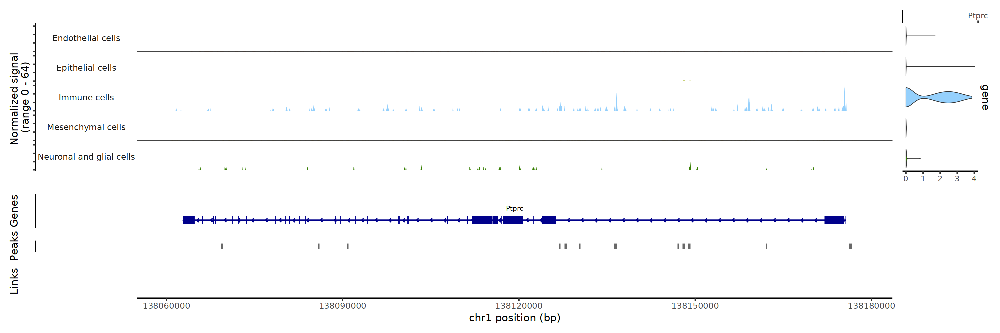

In [ ]:
cvp <- CoveragePlot(integrated,
                        region = 'Ptprc', features = 'Ptprc', group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 2000, 
                        extend.downstream = 2000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("highlight_noDBL_", 'Ptprc', "_igv_tracks.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

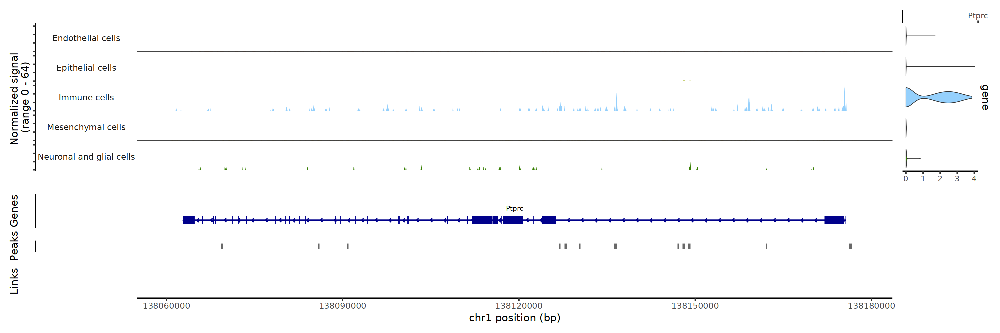

In [ ]:
cvp <- CoveragePlot(integrated,
                        region = 'Ptprc', features = 'Ptprc', group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 2000, 
                        extend.downstream = 2000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("no_highlight_noDBL_", 'Ptprc', "_igv_tracks.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

#### Dcn

In [54]:
#regions <- c()

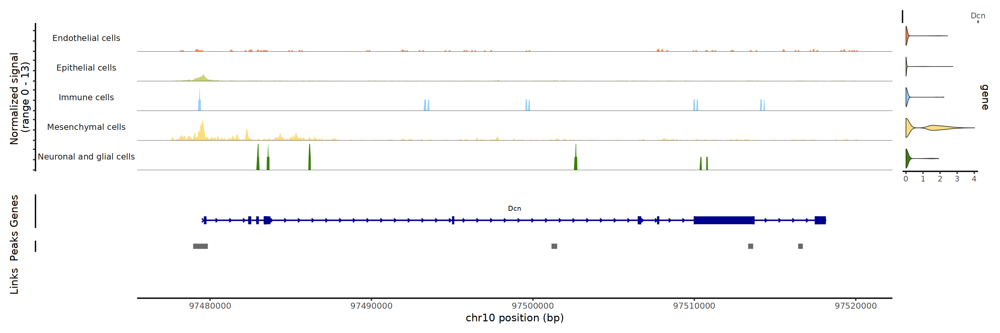

In [ ]:
#ranges.show <- StringToGRanges(regions)

cvp <- CoveragePlot(integrated,
                        region = 'Dcn', features = 'Dcn', group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 2000, 
                        extend.downstream = 2000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("highlight_noDBL_", 'Dcn', "_igv_tracks.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

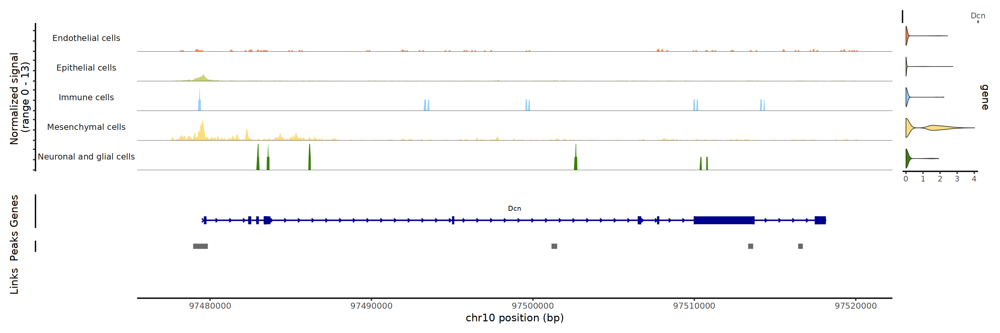

In [ ]:
cvp <- CoveragePlot(integrated,
                        region = 'Dcn', features = 'Dcn', group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 2000, 
                        extend.downstream = 2000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("no_highlight_noDBL_", 'Dcn', "_igv_tracks.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

#### Ccl2

In [ ]:
# regions <- c()

Warning message:
“Removed 5 rows containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range (`geom_segment()`).”


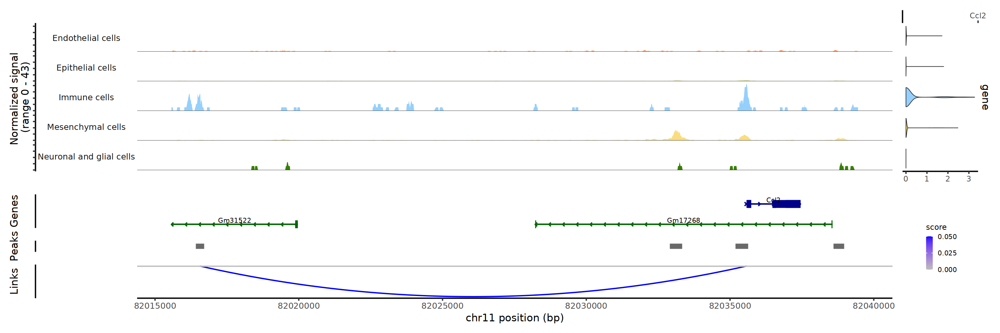

In [ ]:
# ranges.show <- StringToGRanges(regions)

cvp <- CoveragePlot(integrated,
                        region = 'Ccl2', features = 'Ccl2', group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 20000, 
                        extend.downstream = 2000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("highlight_noDBL_", 'Ccl2', "_igv_tracks.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

Warning message:
“Removed 5 rows containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range (`geom_segment()`).”


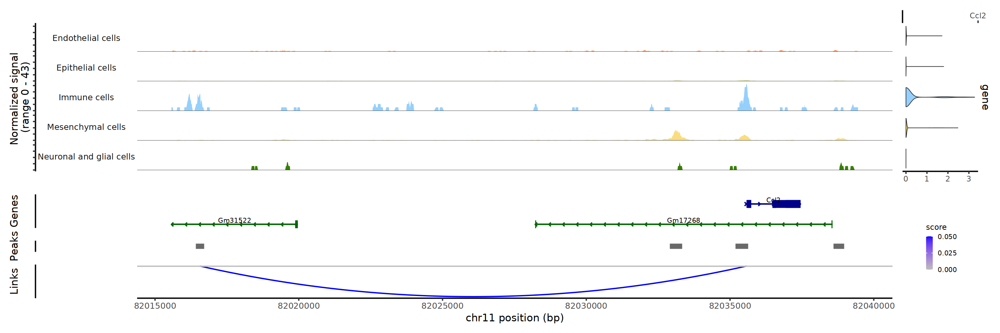

In [ ]:
cvp <- CoveragePlot(integrated,
                        region = 'Ccl2', features = 'Ccl2', group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 20000, 
                        extend.downstream = 2000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("no_highlight_noDBL_", 'Ccl2', "_igv_tracks.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

#### Csf1

In [74]:
regions <- c('chr3-107759465-107760957')

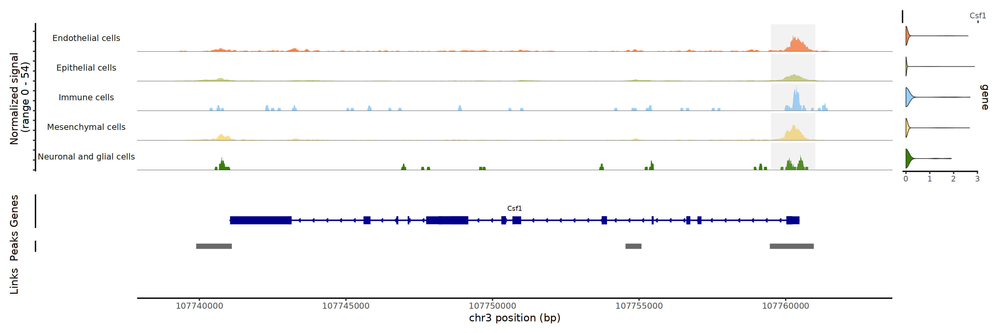

In [ ]:
ranges.show <- StringToGRanges(regions)

cvp <- CoveragePlot(integrated,
                        region = 'Csf1', features = 'Csf1', region.highlight = ranges.show, group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 2000, 
                        extend.downstream = 2000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("highlight_noDBL_", 'Csf1', "_igv_tracks.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

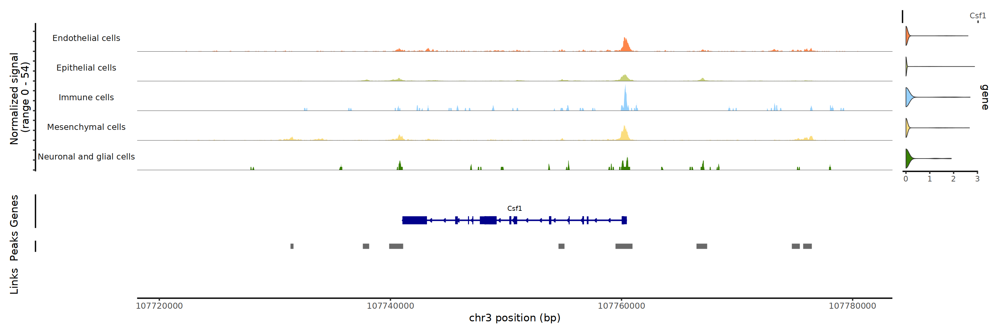

In [ ]:
cvp <- CoveragePlot(integrated,
                        region = 'Csf1', features = 'Csf1', group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 20000, 
                        extend.downstream = 20000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("no_highlight_noDBL_", 'Csf1', "_igv_tracks.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

#### Cxcl1

In [82]:
# regions <- c()

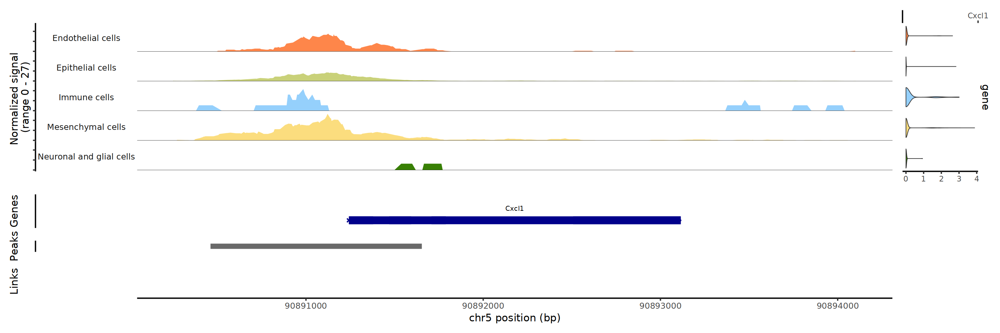

In [ ]:
# ranges.show <- StringToGRanges(regions)

cvp <- CoveragePlot(integrated,
                        region = 'Cxcl1', features = 'Cxcl1', group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 1000, 
                        extend.downstream = 1000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("highlight_noDBL_", 'Cxcl1', "_igv_tracks.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

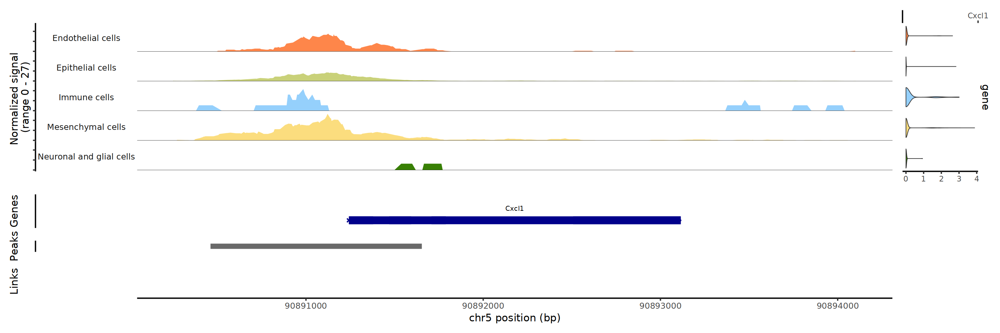

In [ ]:
cvp <- CoveragePlot(integrated,
                        region = 'Cxcl1', features = 'Cxcl1', group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 1000, 
                        extend.downstream = 1000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("no_highlight_noDBL_", 'Cxcl1', "_igv_tracks.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

#### Cebpd

In [89]:
regions <- c('chr16-15886577-15888202')

Warning message:
“Removed 36 rows containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 36 rows containing missing values or values outside the scale range (`geom_segment()`).”


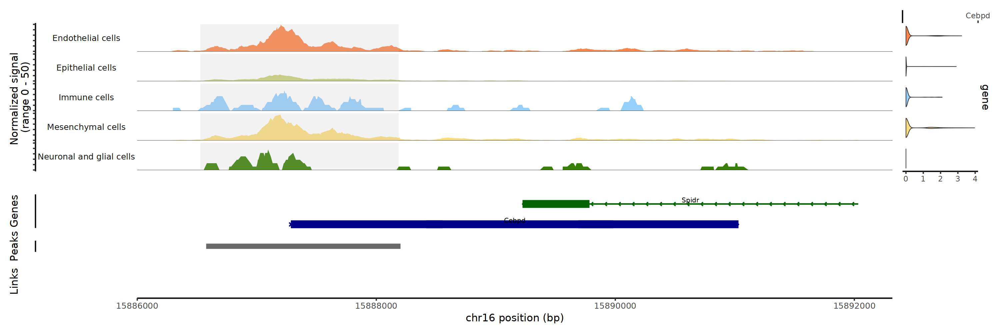

In [ ]:
ranges.show <- StringToGRanges(regions)

cvp <- CoveragePlot(integrated,
                        region = 'Cebpd', features = 'Cebpd', region.highlight = ranges.show, group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 1000, 
                        extend.downstream = 1000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("highlight_noDBL_", 'Cebpd', "_igv_tracks.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

Warning message:
“Removed 36 rows containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 36 rows containing missing values or values outside the scale range (`geom_segment()`).”


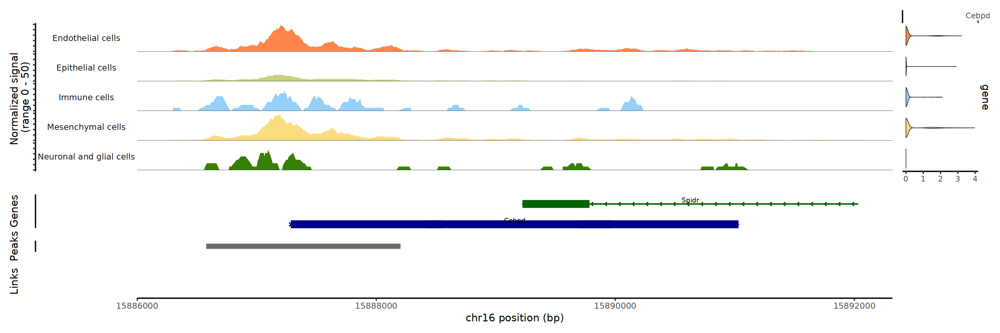

In [ ]:
cvp <- CoveragePlot(integrated,
                        region = 'Cebpd', features = 'Cebpd', group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 1000, 
                        extend.downstream = 1000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("no_highlight_noDBL_", 'Cebpd', "_igv_tracks.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

#### Il6

In [ ]:
# regions <- c()

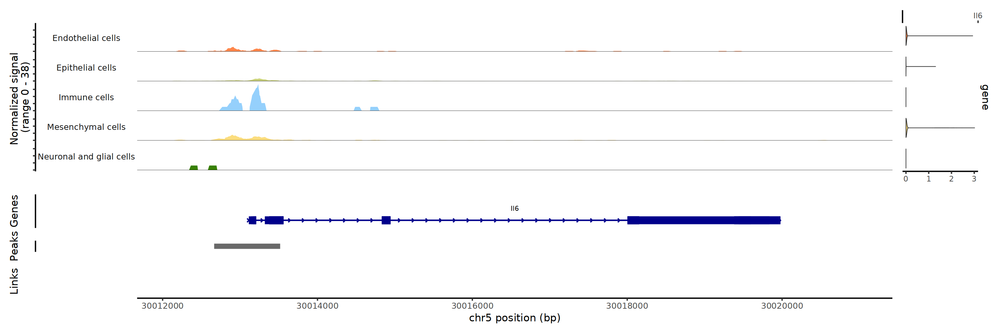

In [ ]:
# ranges.show <- StringToGRanges(regions)

cvp <- CoveragePlot(integrated,
                        region = 'Il6', features = 'Il6', group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 1000, 
                        extend.downstream = 1000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("highlight_noDBL_", 'Il6', "_igv_tracks.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

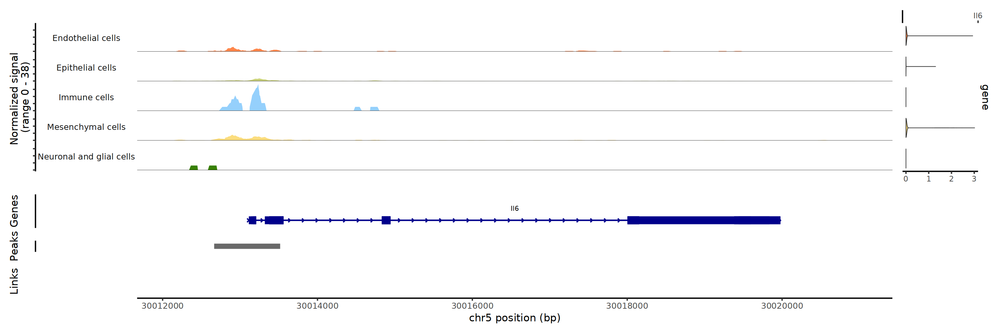

In [ ]:
cvp <- CoveragePlot(integrated,
                        region = 'Il6', features = 'Il6', group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 1000, 
                        extend.downstream = 1000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("no_highlight_noDBL_", 'Il6', "_igv_tracks.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

#### Steap4

In [102]:
# regions <- c()

Warning message:
“Removed 5 rows containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range (`geom_segment()`).”


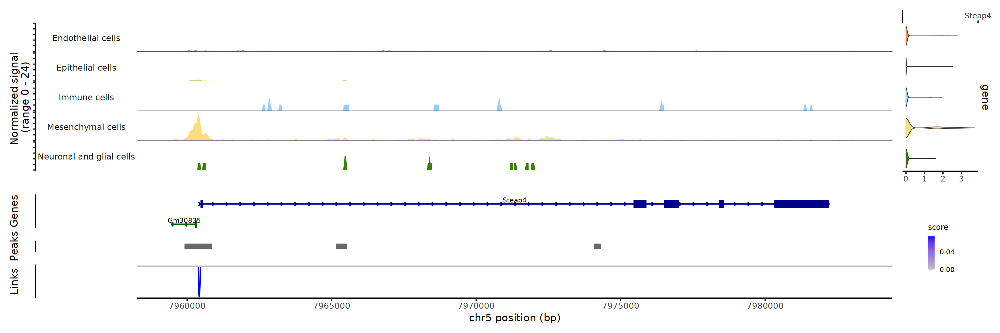

In [ ]:
# ranges.show <- StringToGRanges(regions)

cvp <- CoveragePlot(integrated,
                        region = 'Steap4', features = 'Steap4', group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 1000, 
                        extend.downstream = 1000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("highlight_noDBL_", 'Steap4', "_igv_tracks.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

Warning message:
“Removed 5 rows containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 5 rows containing missing values or values outside the scale range (`geom_segment()`).”


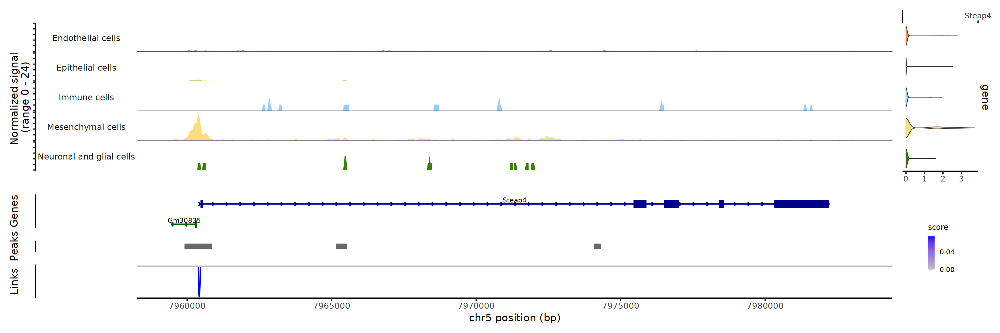

In [ ]:
cvp <- CoveragePlot(integrated,
                        region = 'Steap4', features = 'Steap4', group.by = 'Cell_type',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 1000, 
                        extend.downstream = 1000, ncol=1) & scale_fill_manual(values = my_c)
    
    print(cvp)
    
    plot_name = paste0("no_highlight_noDBL_", 'Steap4', "_igv_tracks.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

## IGV tracks splited by age

In [17]:
options(repr.plot.width = 15, repr.plot.height = 5, repr.plot.res = 200)

### Epithelial cells

#### H2-Eb1

In [ ]:
regions <- c('chr17-34309331-34310181', 'chr17-34305625-34306003', 'chr17-34313278-34313756')

Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_segment()`).”


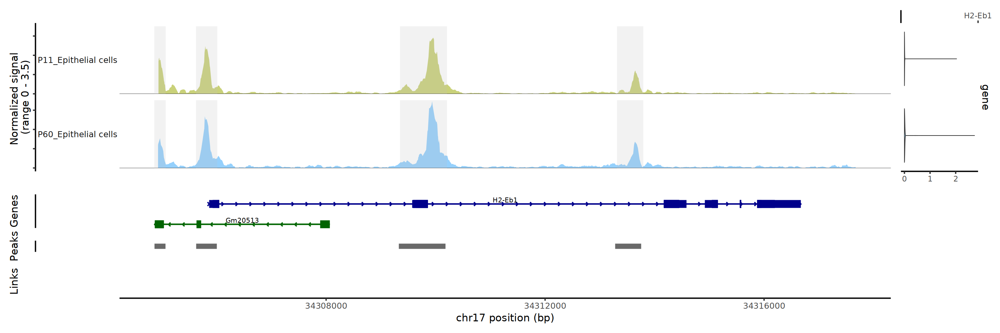

In [ ]:
ranges.show <- StringToGRanges(regions)

cvp <- CoveragePlot(integrated,
                        region = 'H2-Eb1', features = 'H2-Eb1', region.highlight = ranges.show, idents = c('Epithelial cells'),
                    split.by = 'Age',
                    group.by = 'Cell_type', annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 1000, 
                        extend.downstream = 1000, ncol=1) & scale_fill_manual(values = c(my_c[2], my_c[3]))
    
    print(cvp)
    
    plot_name = paste0("Epi_Age_highlight_noDBL_", 'H2-Eb1', "_igv_tracks_all_cells.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

#### H2-Aa

In [36]:
regions <- c('chr17-34287543-34288079')

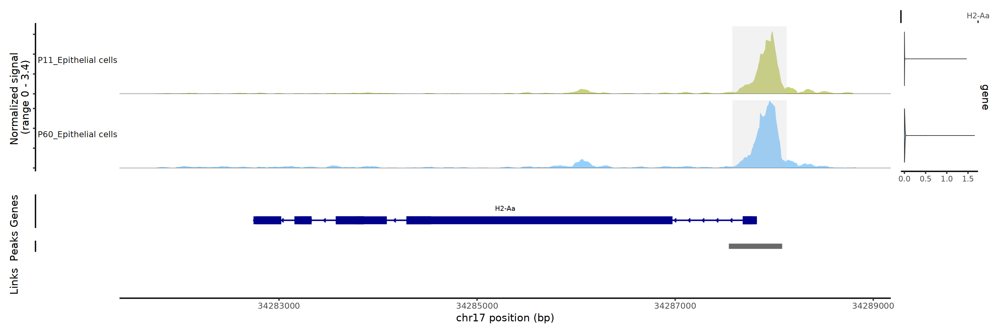

In [ ]:
ranges.show <- StringToGRanges(regions)

cvp <- CoveragePlot(integrated,
                        region = 'H2-Aa', features = 'H2-Aa', region.highlight = ranges.show, idents = c('Epithelial cells'),
                    split.by = 'Age',
                    group.by = 'Cell_type', annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 1000, 
                        extend.downstream = 1000, ncol=1) & scale_fill_manual(values = c(my_c[2], my_c[3]))
    
    print(cvp)
    
    plot_name = paste0("Epi_Age_highlight_noDBL_", 'H2-Aa', "_igv_tracks_all_cells.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

### Endothelial cells

#### H2-K1

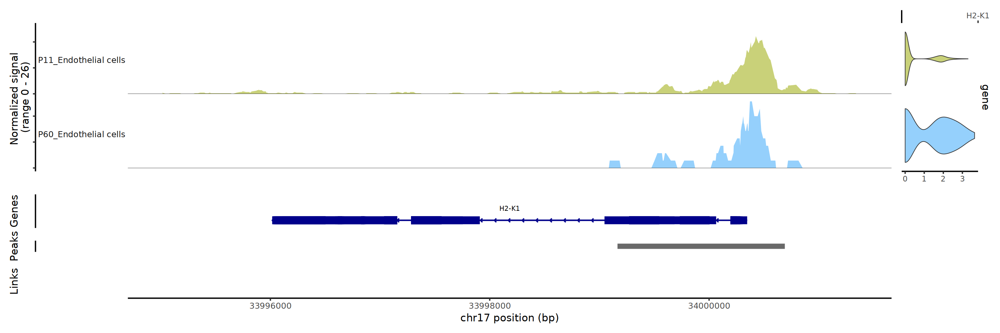

In [ ]:
cvp <- CoveragePlot(integrated,
                        region = 'H2-K1', features = 'H2-K1', idents = c('Endothelial cells'),
                    group.by = 'Cell_type', annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 1000, 
                    split.by = 'Age',
                        extend.downstream = 1000, ncol=1) & scale_fill_manual(values = c(my_c[2], my_c[3]))
    
    print(cvp)
    
    plot_name = paste0("Endo_Age_no_highlight_noDBL_", 'H2-K1', "_igv_tracks_all_cells.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

#### H2-D1

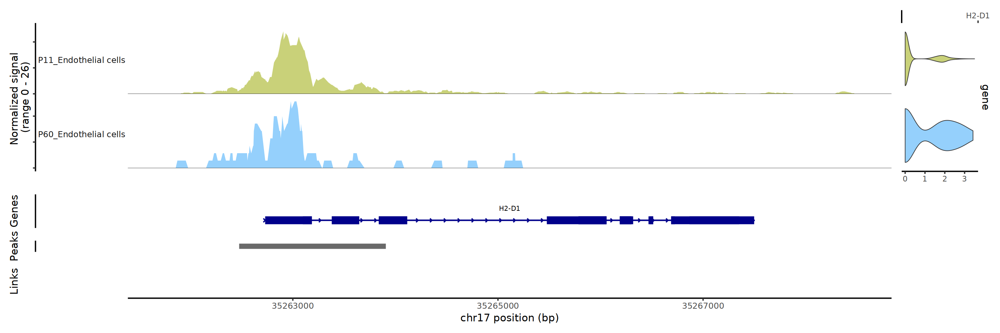

In [ ]:
cvp <- CoveragePlot(integrated,
                        region = 'H2-D1', features = 'H2-D1', idents = c('Endothelial cells'), split.by = 'Age',
                    group.by = 'Cell_type', annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 1000, 
                        extend.downstream = 1000, ncol=1) & scale_fill_manual(values = c(my_c[2], my_c[3]))
    
    print(cvp)
    
    plot_name = paste0("Endo_Age_no_highlight_noDBL_", 'H2-D1', "_igv_tracks_all_cells.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

### Mesenchymal cells

#### H2-K1

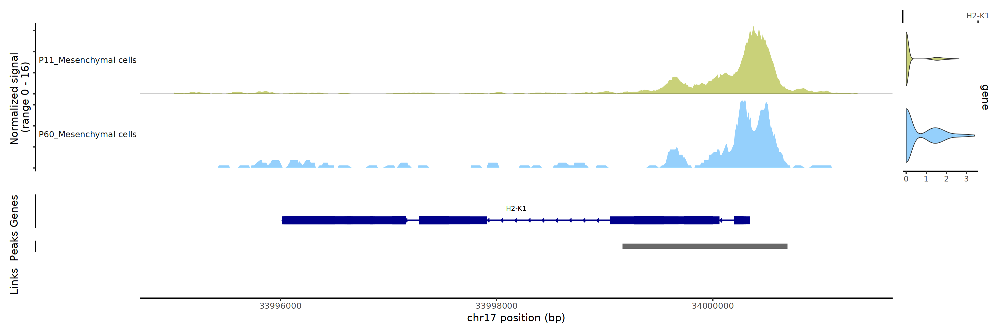

In [ ]:
cvp <- CoveragePlot(integrated,
                        region = 'H2-K1', features = 'H2-K1', idents = c('Mesenchymal cells'), split.by = 'Age',
                    group.by = 'Cell_type', annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 1000, 
                        extend.downstream = 1000, ncol=1) & scale_fill_manual(values = c(my_c[2], my_c[3]))
    
    print(cvp)
    
    plot_name = paste0("Mesen_Age_no_highlight_noDBL_", 'H2-K1', "_igv_tracks_all_cells.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

#### H2-D1

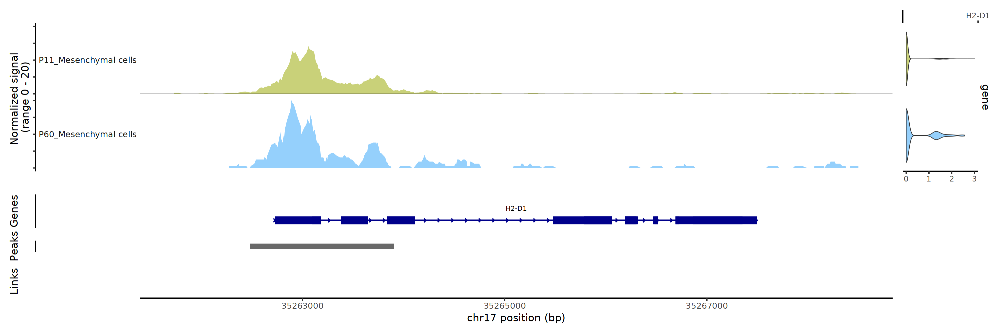

In [ ]:
cvp <- CoveragePlot(integrated,
                        region = 'H2-D1', features = 'H2-D1', idents = c('Mesenchymal cells'), split.by = 'Age',
                    group.by = 'Cell_type', annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 1000, 
                        extend.downstream = 1000, ncol=1) & scale_fill_manual(values = c(my_c[2], my_c[3]))
    
    print(cvp)
    
    plot_name = paste0("Mesen_Age_no_highlight_noDBL_", 'H2-D1', "_igv_tracks_all_cells.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

### Immune cells

#### H2-Eb1

Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_segment()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_segment()`).”


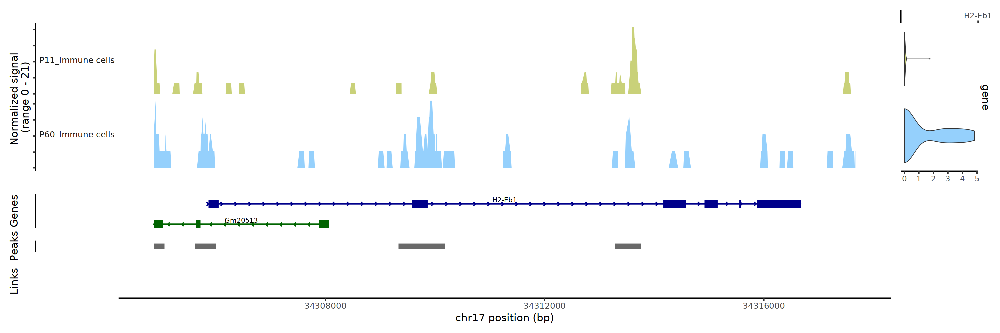

In [ ]:
cvp <- CoveragePlot(integrated,
                        region = 'H2-Eb1', features = 'H2-Eb1', idents = c('Immune cells'), group.by = 'Cell_type',
                    split.by = 'Age',
                        annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 1000, 
                        extend.downstream = 1000, ncol=1) & scale_fill_manual(values = c(my_c[2], my_c[3]))
    
    print(cvp)
    
    plot_name = paste0("Immune_Age_no_highlight_noDBL_", 'H2-Eb1', "_igv_tracks_all_cells.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

#### H2-Aa

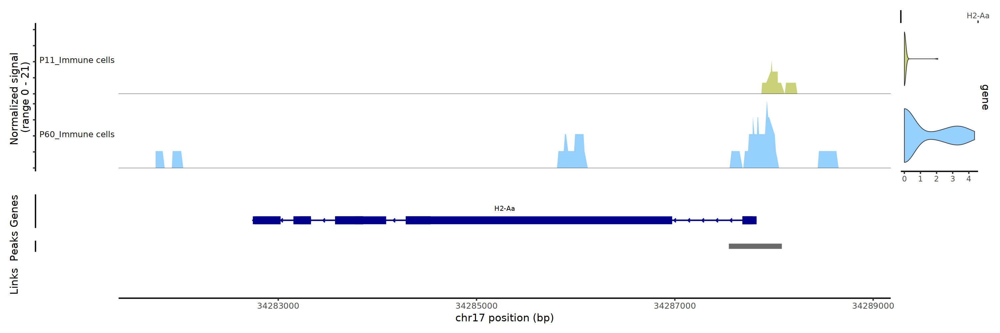

In [ ]:
ranges.show <- StringToGRanges(regions)

cvp <- CoveragePlot(integrated,
                        region = 'H2-Aa', features = 'H2-Aa', idents = c('Immune cells'), group.by = 'Cell_type', 
                    split.by = 'Age',
                    annotation = TRUE, peaks = TRUE, links = TRUE, extend.upstream = 1000, 
                        extend.downstream = 1000, ncol=1) & scale_fill_manual(values = c(my_c[2], my_c[3]))
    
    print(cvp)
    
    plot_name = paste0("Immune_Age_no_highlight_noDBL_", 'H2-Aa', "_igv_tracks_all_cells.svg")
    
    ggsave(file=plot_name, plot=cvp, width=15, height=5)

# Xist counts to try to separate male and female cells 

In [ ]:
integrated <- readRDS('noDBL_merged_peaks_clusters_joint_linked_motif.rds')

In [11]:
DefaultAssay(integrated) <- 'RNA'

In [12]:
integrated

An object of class Seurat 
216256 features across 37992 samples within 3 assays 
Active assay: RNA (32287 features, 4000 variable features)
 3 layers present: counts, data, scale.data
 2 other assays present: peaks, chromvar
 10 dimensional reductions calculated: pca, umap, umapRNA, harmonyRNA, harmony_RNA, lsi, atac.umap, harmonyPeaks, harmony_Peaks, multiome.umap

In [14]:
xist_counts <- GetAssayData(integrated, assay = "RNA", layer = "counts")[ "Xist",]

In [15]:
integrated$'Xist-counts' <- xist_counts

In [18]:
integrated$'Female' <- integrated$`Xist-counts` > 0

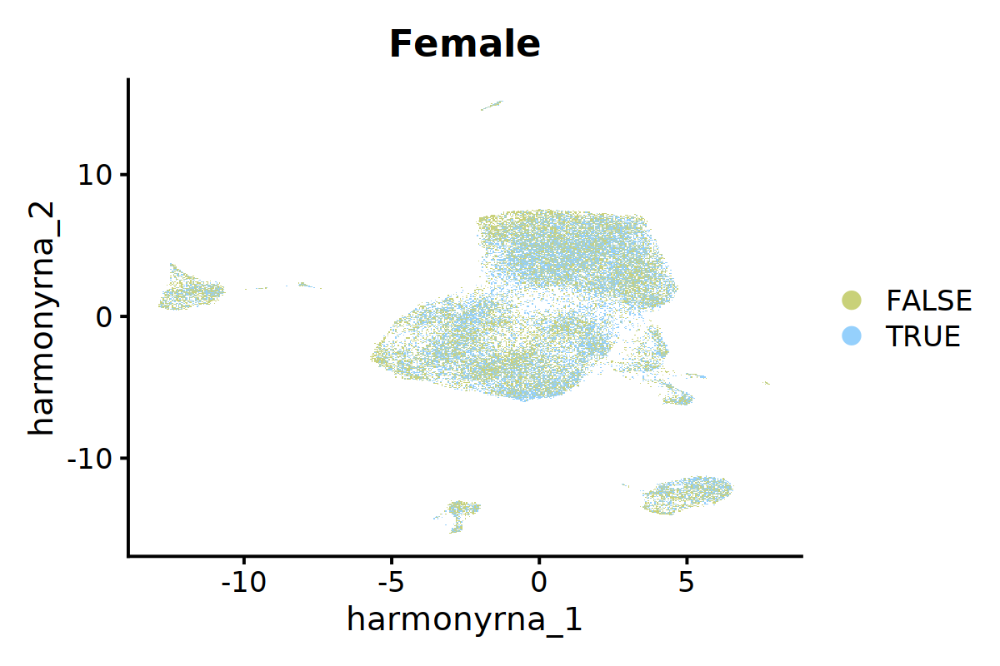

In [21]:
options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
dmp <- DimPlot(object = integrated, label = FALSE,group.by='Female', cols = my_c[2:3], 
               reduction = 'harmony_RNA', raster = TRUE, pt.size = 1)

dmp

ggsave(file="Plots/Gender_inference_Harmony_noDBL_RNA_umap_all_cells.svg", plot=dmp, width=6, height=4)

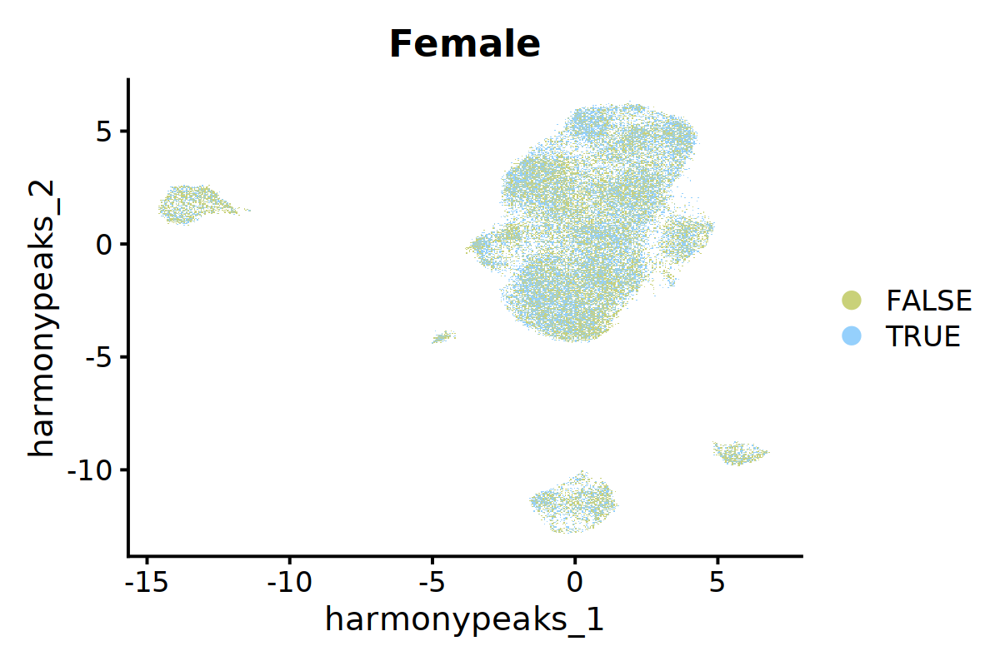

In [22]:
options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
dmp <- DimPlot(object = integrated, label = FALSE,group.by='Female', cols = my_c[2:3], 
               reduction = 'harmony_Peaks', raster = TRUE, pt.size = 1)

dmp

ggsave(file="Plots/Gender_inference_Harmony_noDBL_peaks_umap_all_cells.svg", plot=dmp, width=6, height=4)

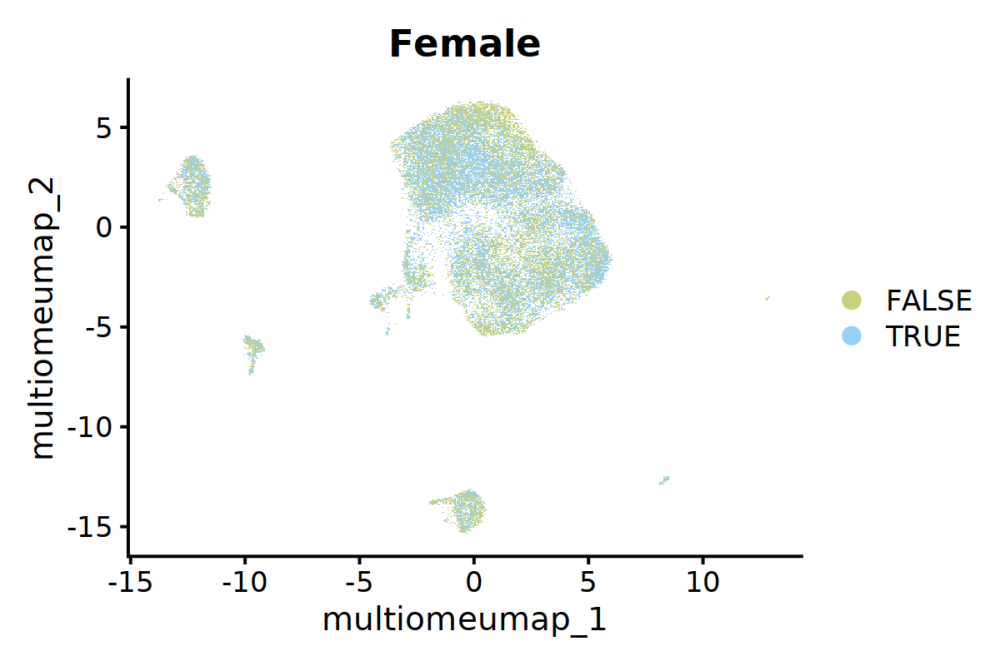

In [23]:
options(repr.plot.width = 6, repr.plot.height = 4, repr.plot.res = 200)
dmp <- DimPlot(object = integrated, label = FALSE,group.by='Female', cols = my_c[2:3], 
               reduction = 'multiome.umap', raster = TRUE, pt.size = 1)

dmp

ggsave(file="Plots/Gender_inference_Harmony_noDBL_joint_umap_all_cells.svg", plot=dmp, width=6, height=4)

# Session info

In [17]:
print(sessioninfo::session_info())

─ Session info ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
 setting  value
 version  R version 4.3.1 (2023-06-16)
 os       Debian GNU/Linux 12 (bookworm)
 system   x86_64, linux-gnu
 ui       X11
 language en_GB.UTF-8
 collate  C.UTF-8
 ctype    C.UTF-8
 tz       Etc/UTC
 date     2025-03-17
 pandoc   3.1.13 @ /opt/conda/envs/multiome_env2/bin/pandoc

─ Packages ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
 package                      * version   date (UTC) lib source
 abind                          1.4-5     2016-07-21 [1] CRAN (R 4.3.3)
 annotate                       1.80.0    2023-10-24 [1] Bioconductor
 AnnotationDbi                  1.64.1    2023-11-03 [1] Bioconductor
 base64enc                      0.1-3     2015-07-28 [1] CRAN (R 4.3.3)
 Biobase                        2.62.0    2023-10-